## Optimización de Rutas de Redistribución (BRP) — Bicing Barcelona

Análisis exploratorio de datos (EDA) del sistema de bicicletas compartidas de Barcelona (Bicing).  
El objetivo es caracterizar los patrones de demanda horaria por estación para construir un modelo predictivo de ocupación que sirva de base para la optimización de rutas de redistribución (Bike Redistribution Problem).

**Datos**: telemetría horaria Oct 2023 – Sep 2025, ~500 estaciones, datos meteorológicos y calendario de festivos.  
**Modelos objetivo**: LSTM (series temporales) y XGBoost (regresión con features de lag).

## 0. Configuración del entorno

### 0.1. Carga de librerías

In [42]:
import importlib, subprocess, sys

REQUIRED = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "plotly": "plotly",
    "folium": "folium",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "statsmodels": "statsmodels",
    "missingno": "missingno",
    "py7zr": "py7zr",
    "requests": "requests",
    "pyarrow": "pyarrow",
    "tqdm": "tqdm",
}

for module, package in REQUIRED.items():
    if importlib.util.find_spec(module) is None:
        print(f"Instalando {package}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", package, "-q"])

print("Todas las dependencias están disponibles.")

Todas las dependencias están disponibles.


In [43]:
import warnings, json, io, os
import time

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import Normalize
import py7zr
import pandas as pd
import numpy as np
import requests
from pathlib import Path
from tqdm.auto import tqdm

import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import folium
from folium.plugins import MarkerCluster
import missingno as msno
from scipy import stats
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from statsmodels.tsa.seasonal import STL

DATA_DIR    = Path("../data/processed")
DATA_DIR.mkdir(parents=True, exist_ok=True)

print("Imports y directorios listos.")

Imports y directorios listos.


### 0.2. Paleta y estilos

In [44]:
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)

BICING_RED       = "#E3000B"
BICING_DARK_GREY = "#4A4A4A"

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "grid.alpha": 0.4,
    "grid.linewidth": 0.6,
})

sns.set_theme(style="ticks", rc={
    "axes.spines.top": False,
    "axes.spines.right": False,
})

PLOTLY_LAYOUT = dict(
    plot_bgcolor="white",
    paper_bgcolor="white",
    font_color=BICING_DARK_GREY,
    xaxis=dict(gridcolor="#eeeeee", linecolor="#cccccc"),
    yaxis=dict(gridcolor="#eeeeee", linecolor="#cccccc"),
)

## 1. Carga de Datos

Los parquets se generan ejecutando `python src/dataset_builder.py` desde la raíz del proyecto.

| Parquet | Contenido |
|---|---|
| `bicing_hourly.parquet` | Telemetría horaria agregada por estación y tipo de día |
| `bicing_stations.parquet` | Metadatos estáticos (coordenadas, altitud, capacidad) |
| `meteo_barcelona.parquet` | Meteorología horaria Open-Meteo (Oct 2023 – Sep 2025) |
| `bicing_full.parquet` | Merge de los tres anteriores (tabla maestra del EDA) |

In [46]:
HOURLY_PARQUET = DATA_DIR / "bicing_hourly.parquet"
INFO_PARQUET   = DATA_DIR / "bicing_stations.parquet"
METEO_PARQUET  = DATA_DIR / "meteo_barcelona.parquet"
FULL_PARQUET   = DATA_DIR / "bicing_full.parquet"

_missing = [p for p in [HOURLY_PARQUET, INFO_PARQUET, METEO_PARQUET, FULL_PARQUET] if not p.exists()]
if _missing:
    import sys as _sys
    print(f"Parquets no encontrados: {[p.name for p in _missing]}")
    print("Generando parquets desde dataset_builder...")
    _src_dir = str(Path("../src").resolve())
    if _src_dir not in _sys.path:
        _sys.path.insert(0, _src_dir)
    from dataset_builder import build_hourly, build_stations, build_meteo, build_full
    _bh = build_hourly()
    _bs = build_stations()
    _bm = build_meteo()
    _bf = build_full(_bh, _bs, _bm)
    print("Parquets generados correctamente.")

df_stations = pd.read_parquet(INFO_PARQUET)
df_hourly   = pd.read_parquet(HOURLY_PARQUET)
df_meteo    = pd.read_parquet(METEO_PARQUET)
df          = pd.read_parquet(FULL_PARQUET)

hora_min = df_hourly["hora"].min()
hora_max = df_hourly["hora"].max()
print(f"Estaciones : {df_stations.shape}")
print(f"Horario    : {hora_min} - {hora_max} | {df_hourly.shape}")
print(f"Meteo      : {df_meteo.shape}")
print(f"Full       : {df.shape}")

Estaciones : (548, 14)
Horario    : 2023-10-01 00:00:00 - 2025-09-30 00:00:00 | (8996508, 5)
Meteo      : (17544, 7)
Full       : (8949710, 53)


## 2. EDA Dataset Estaciones

### 2.1. Exploración inicial 

In [ ]:
print(f"Shape: {df_stations.shape}  |  Estaciones únicas: {df_stations['station_id'].nunique()}")
display(df_stations.head(5))

Shape: (548, 14)  |  Estaciones únicas: 548


,station_id,name,physical_configuration,lat,lon,altitude,address,cross_street,post_code,capacity,is_charging_station,short_name,nearby_distance,last_updated
0,325,"C/ ALT DE GIRONELLA, 13",ELECTRICBIKESTATION,41.3950,2.1303,82.0000,"C/ ALT DE GIRONELLA, 13",05-Sarrià-StGervasi/24-les Tres Torres,8017.0000,23,True,325,1000,1758522602
1,536,Estación de TESTING (no usuarios),ELECTRICBIKESTATION,41.3477,2.1195,4.0000,Rafael Barradas 5,None,8908.0000,1,True,8005,101,1758803402
2,1,"GRAN VIA CORTS CATALANES, 760",ELECTRICBIKESTATION,41.3980,2.1801,16.0000,"GRAN VIA CORTS CATALANES, 760",02-Eixample/05-el Fort Pienc,8013.0000,46,True,1,1000,1759269304
3,2,"C/ ROGER DE FLOR, 126",ELECTRICBIKESTATION,41.3955,2.1772,17.0000,"C/ ROGER DE FLOR, 126",02-Eixample/05-el Fort Pienc,8013.0000,28,True,2,1000,1759269304
4,3,"C/ NÀPOLS, 82",ELECTRICBIKESTATION,41.3942,2.1813,11.0000,"C/ NÀPOLS, 82",02-Eixample/05-el Fort Pienc,8013.0000,27,True,3,1000,1759269304


In [ ]:
col_info = df_stations.dtypes.to_frame("dtype")
col_info["nulls"]  = df_stations.isnull().sum()
col_info["null_%"] = (df_stations.isnull().mean() * 100).round(2)
display(col_info)

,dtype,nulls,null_%
station_id,int32,0,0.0000
name,object,0,0.0000
physical_configuration,object,0,0.0000
lat,float64,0,0.0000
lon,float64,0,0.0000
altitude,float64,19,3.4700
address,object,0,0.0000
cross_street,object,4,0.7300
post_code,float64,5,0.9100
capacity,int64,0,0.0000


El dataset de estaciones contiene 548 registros, uno por estación, con 14 atributos que cubren localización geográfica, capacidad, altitud y tipo de configuración. La tasa de nulos es baja en las variables principales, aunque la columna de altitud presenta ausencias en 19 estaciones que serán imputadas en el apartado de tratamiento de calidad.

### 2.2. Variables de interés

#### 2.2.1. Variables numéricas continuas

In [184]:
cont_cols = [c for c in df_stations.columns if any(k in c for k in ["capacity", "altitude", "altitud"]) and "nearby" not in c]
display(df_stations[cont_cols].describe())

,altitude,capacity,nearby_distance
count,529.0000,548.0000,548.0000
mean,37.1113,27.0109,991.0639
std,34.6768,7.0184,93.2497
min,0.0000,1.0000,1.0000
25%,9.0000,23.0000,1000.0000
50%,26.0000,27.0000,1000.0000
75%,55.0000,30.0000,1000.0000
max,184.0000,54.0000,1000.0000


  -> Guardado: ..\outputs\figures\02_dist_vars_continuas.png


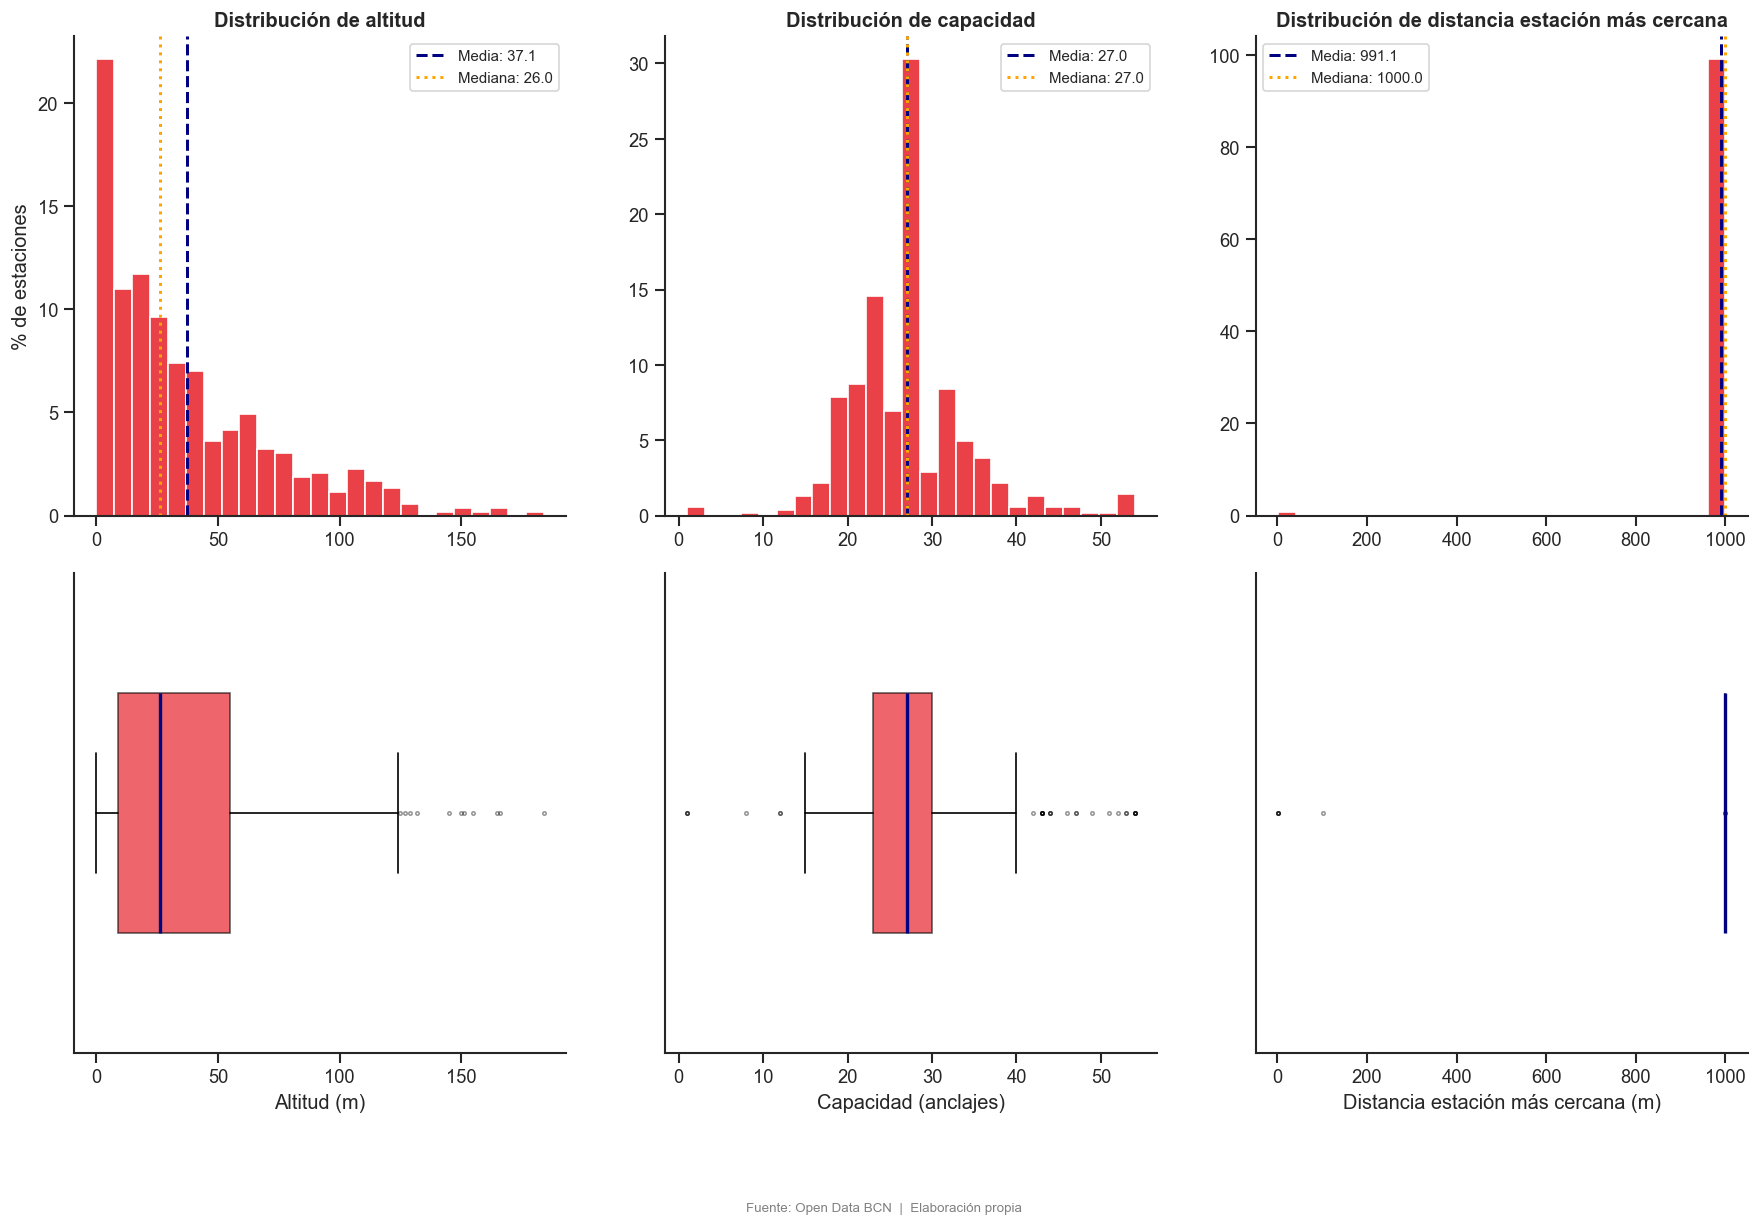

In [185]:
CONT_LABELS = {
    cap_col_s:  "Capacidad (anclajes)",
    alt_col_s:  "Altitud (m)",
    dist_col_s: "Distancia estación más cercana (m)",
}

fig, axes = plt.subplots(2, len(cont_cols), figsize=(6 * len(cont_cols), 11),
                         gridspec_kw={"height_ratios": [1, 1], "hspace": 0.12})

for i, col in enumerate(cont_cols):
    data, label = df_stations[col].dropna(), CONT_LABELS.get(col, col)
    media, mediana = data.mean(), data.median()

    sns.histplot(data, bins=25, ax=axes[0, i], color=BICING_RED, stat="percent")
    axes[0, i].axvline(media,   color="navy",   linestyle="--", linewidth=1.8, label=f"Media: {media:.1f}")
    axes[0, i].axvline(mediana, color="orange", linestyle=":",  linewidth=1.8, label=f"Mediana: {mediana:.1f}")
    axes[0, i].set_title(f"Distribución de {label.split('(')[0].strip().lower()}", fontweight="bold")
    axes[0, i].set_xlabel("")
    axes[0, i].set_ylabel("% de estaciones" if i == 0 else "")
    axes[0, i].legend(fontsize=9)

    axes[1, i].boxplot(data, vert=False, patch_artist=True,
                       boxprops=dict(facecolor=BICING_RED, alpha=0.6),
                       medianprops=dict(color="navy", linewidth=2),
                       flierprops=dict(marker=".", markersize=4, alpha=0.4),
                       widths=0.5)
    axes[1, i].set_xlabel(label)
    axes[1, i].set_yticks([])

sns.despine(bottom=False)
plt.tight_layout()
fig.text(0.5, -0.01, "Fuente: Open Data BCN  |  Elaboración propia", ha="center", fontsize=8, color="gray")
plt.show()

La capacidad de las estaciones presenta una distribución asimétrica con media y mediana en torno a 27 anclajes y una cola derecha pronunciada que alcanza los 54 anclajes, lo que indica la existencia de estaciones de gran capacidad en zonas de alta demanda. La altitud refleja la topografía de Barcelona: la mayoría de estaciones se sitúan por debajo de los 40 metros, con una media de 37 metros y una mediana de 26 metros, y una cola hacia valores elevados correspondiente a los barrios de Sarrià-Sant Gervasi y Gràcia, donde algunas estaciones superan los 150 metros.

#### 2.2.2. Variables categóricas

  -> Guardado: ..\outputs\figures\02_charging_stations.png


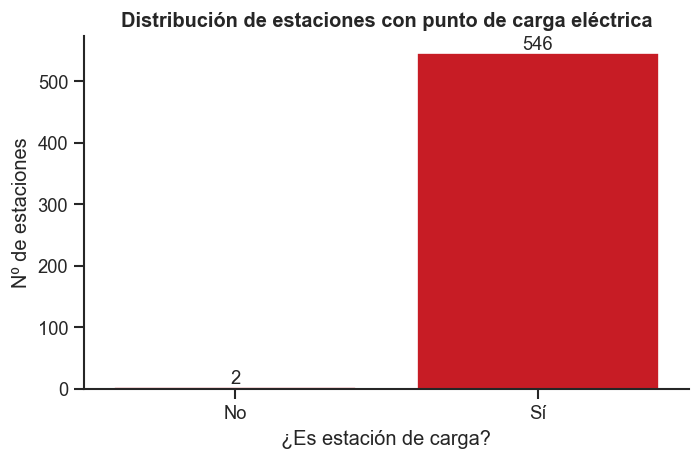

In [53]:
charg_col = next((c for c in df_stations.columns if "charging" in c.lower()), None)

if charg_col:
    order = sorted(df_stations[charg_col].dropna().unique())
    tick_labels = ["No", "Sí"] if list(order) == [0, 1] else [str(v) for v in order]

    fig, ax = plt.subplots(figsize=(6, 4))
    sns.countplot(data=df_stations, x=charg_col, ax=ax,
                  color=BICING_RED, order=order)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(tick_labels)
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height())}",
                    (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=11)
    ax.set_title("Distribución de estaciones con punto de carga eléctrica", fontweight="bold")
    ax.set_xlabel("¿Es estación de carga?")
    ax.set_ylabel("Nº de estaciones")
    sns.despine()
    plt.tight_layout()
    plt.show()
else:
    print("Columna de carga eléctrica no encontrada. Columnas:", list(df_stations.columns))

  -> Guardado: ..\outputs\figures\02_estaciones_por_barrio.png


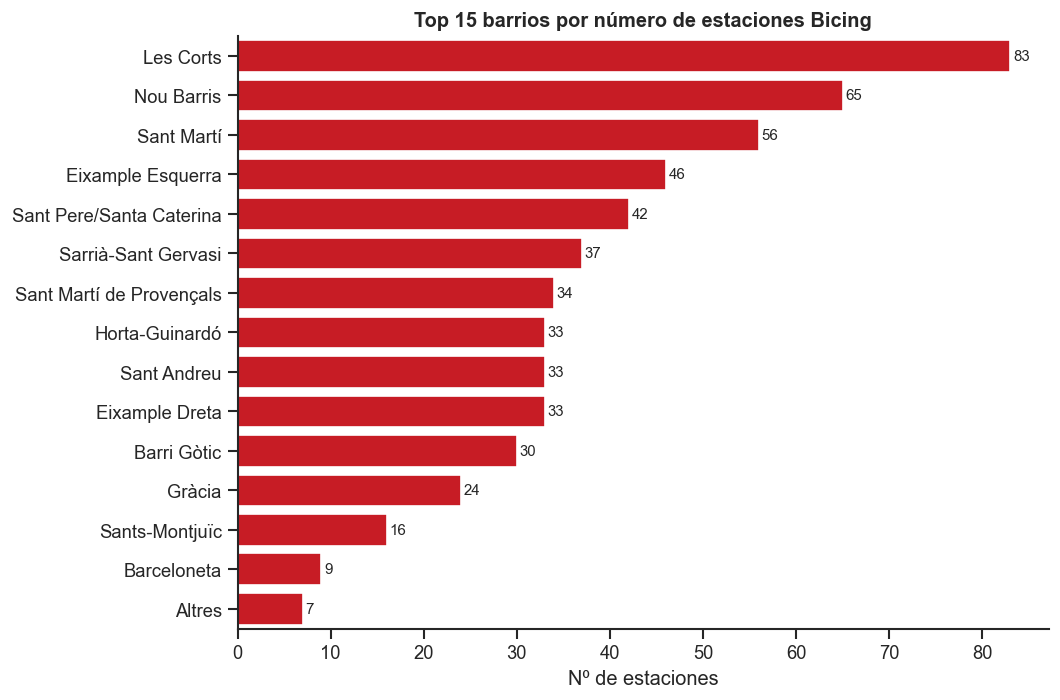

Total barrios distintos: 15


In [57]:
POSTAL_BARRIO = {
    "08001": "Barri Gòtic",             "08002": "Barri Gòtic",
    "08003": "Sant Pere/Santa Caterina","08004": "Eixample Esquerra",
    "08005": "Sant Martí de Provençals","08006": "Gràcia",
    "08007": "Eixample Dreta",          "08008": "Eixample Esquerra",
    "08009": "Eixample Dreta",          "08010": "Eixample Dreta",
    "08011": "Eixample Esquerra",       "08012": "Gràcia",
    "08013": "Sant Pere/Santa Caterina","08014": "Les Corts",
    "08015": "Eixample Esquerra",       "08016": "Nou Barris",
    "08017": "Sarrià-Sant Gervasi",     "08018": "Sant Martí",
    "08019": "Sant Martí",              "08020": "Sant Martí",
    "08021": "Sarrià-Sant Gervasi",     "08022": "Sarrià-Sant Gervasi",
    "08023": "Sarrià-Sant Gervasi",     "08024": "Gràcia",
    "08025": "Sant Andreu",             "08026": "Horta-Guinardó",
    "08027": "Sant Andreu",             "08028": "Les Corts",
    "08029": "Les Corts",               "08030": "Nou Barris",
    "08031": "Nou Barris",              "08032": "Horta-Guinardó",
    "08033": "Horta-Guinardó",          "08034": "Les Corts",
    "08035": "Nou Barris",              "08036": "Les Corts",
    "08037": "Eixample Dreta",          "08038": "Sants-Montjuïc",
    "08039": "Barceloneta",             "08040": "Sants-Montjuïc",
    "08041": "Horta-Guinardó",          "08042": "Nou Barris",
}

barri_col = next((c for c in df_stations.columns
                  if "barri" in c.lower() or "neighborhood" in c.lower()), None)
post_col  = next((c for c in df_stations.columns if "post_code" in c.lower()), None)

if barri_col:
    barrio_series = df_stations[barri_col].astype(str)
elif post_col:
    barrio_series = (df_stations[post_col].dropna().astype(int).astype(str)
                     .str.zfill(5).map(POSTAL_BARRIO).fillna("Altres"))
    barrio_series = barrio_series.reindex(df_stations.index, fill_value="Altres")
else:
    barrio_series = None

if barrio_series is not None:
    top_barrios = barrio_series.value_counts().head(15).reset_index()
    top_barrios.columns = ["barrio", "estaciones"]
    top_barrios = top_barrios.sort_values("estaciones", ascending=False)

    fig, ax = plt.subplots(figsize=(9, 6))
    bar_order = top_barrios["barrio"].tolist()
    sns.barplot(data=top_barrios, x="estaciones", y="barrio",
                color=BICING_RED, ax=ax, order=bar_order)
    for p in ax.patches:
        ax.annotate(f"{int(p.get_width())}",
                    (p.get_width() + 0.3, p.get_y() + p.get_height() / 2),
                    va="center", fontsize=9)
    ax.set_title("Top 15 barrios por número de estaciones Bicing", fontweight="bold")
    ax.set_xlabel("Nº de estaciones")
    ax.set_ylabel("")
    sns.despine()
    plt.tight_layout()
    plt.show()
    print(f"Total barrios distintos: {barrio_series.nunique()}")
else:
    print("No hay columna de barrio/distrito disponible en df_stations.")
    print("Columnas disponibles:", list(df_stations.columns))

Prácticamente la totalidad de las estaciones, 546 de las 548, disponen de punto de carga eléctrica, lo que indica que la flota ha completado la transición hacia la bicicleta eléctrica. La distribución por barrios muestra que Les Corts concentra el mayor número de estaciones con 83, seguido de Nou Barris con 65 y Sant Martí con 56. 

### 2.3. Mapa interactivo

In [58]:
lat_col_s  = next((c for c in df_stations.columns if c in ["lat", "latitude"]), None)
lon_col_s  = next((c for c in df_stations.columns if c in ["lon", "longitude"]), None)
alt_col_s  = next((c for c in df_stations.columns if "altitude" in c or "altitud" in c), None)
cap_col_s  = next((c for c in df_stations.columns if "capacity" in c), None)
name_col_s = next((c for c in df_stations.columns if c in ["name", "nom"]), None)

if lat_col_s and lon_col_s:
    cmap_s   = matplotlib.colormaps["RdYlBu_r"]
    alt_vals = df_stations[alt_col_s].fillna(0) if alt_col_s else pd.Series(0, index=df_stations.index)
    cap_vals = df_stations[cap_col_s].fillna(15) if cap_col_s else pd.Series(15, index=df_stations.index)
    norm_s   = Normalize(vmin=alt_vals.min(), vmax=alt_vals.max())

    m_s = folium.Map(location=[41.3874, 2.1686], zoom_start=13, tiles="CartoDB positron")
    for _, row in df_stations.iterrows():
        alt     = alt_vals.loc[row.name]
        cap     = cap_vals.loc[row.name]
        rgba    = cmap_s(norm_s(alt))
        color_s = "#{:02x}{:02x}{:02x}".format(int(rgba[0]*255), int(rgba[1]*255), int(rgba[2]*255))
        tooltip = (
            f"ID: {int(row['station_id'])}<br>"
            + (f"Nombre: {row[name_col_s]}<br>" if name_col_s else "")
            + f"Capacidad: {int(cap) if pd.notna(cap) else 'N/A'}<br>"
            + f"Altitud: {alt:.0f} m"
        )
        folium.CircleMarker(
            location=[row[lat_col_s], row[lon_col_s]],
            radius=max(4, min(12, cap / 4)),
            color=color_s, fill=True, fill_color=color_s, fill_opacity=0.75,
            tooltip=folium.Tooltip(tooltip),
        ).add_to(m_s)
    display(m_s)
else:
    print("Coordenadas no disponibles en df_stations.")

Mapa guardado: ..\outputs\figures/02_mapa_estaciones.html


El mapa interactivo permite visualizar la distribución espacial de las estaciones codificada por altitud. Se aprecia claramente el gradiente topográfico de la ciudad: las estaciones situadas en la franja litoral y el centro urbano se encuentran a cotas bajas, mientras que las estaciones del norte y noroeste alcanzan altitudes superiores a los 80 metros. Este gradiente es relevante desde el punto de vista del problema de redistribución, ya que las bicicletas tienden a acumularse en cotas bajas por efecto gravitacional, generando un desequilibrio sistemático que requiere intervención activa de los vehículos de redistribución.

### 2.4. Detección de anomalías

In [143]:
# Detección de estaciones anómalas
# Criterios: capacity <= 2 (imposible para red pública), bikes_max >> capacity, cobertura < 1%
total_horas = df_hourly["hora"].nunique()

resumen_est = (
    df_hourly.groupby("station_id")
    .agg(
        registros      = ("hora", "count"),
        fecha_inicio   = ("hora", "min"),
        fecha_fin      = ("hora", "max"),
        bikes_mean     = ("num_bikes_available", "mean"),
        bikes_max      = ("num_bikes_available", "max"),
        bikes_nunique  = ("num_bikes_available", "nunique"),
        bikes_null_pct = ("num_bikes_available", lambda x: x.isna().mean() * 100),
    )
    .assign(cobertura_pct=lambda d: (d["registros"] / total_horas * 100).round(2))
    .join(df_stations.set_index("station_id")[[cap_col_s]].rename(columns={cap_col_s: "capacity"}))
)

est_anomalas = resumen_est[
    (resumen_est["cobertura_pct"] < 1) |
    (resumen_est["capacity"] <= 2) |
    (resumen_est["bikes_max"] > resumen_est["capacity"] * 3)
].sort_values("cobertura_pct")

display(est_anomalas[["registros","fecha_inicio","fecha_fin","capacity",
                       "bikes_mean","bikes_max","bikes_nunique","cobertura_pct"]].round(2))

,registros,fecha_inicio,fecha_fin,capacity,bikes_mean,bikes_max,bikes_nunique,cobertura_pct
station_id,,,,,,,,
521,1,2024-05-14 18:00:00,2024-05-14 18:00:00,NaN,2.0000,2.0000,1,0.0100
545,2,2025-03-03 12:00:00,2025-03-03 13:00:00,NaN,0.0000,0.0000,1,0.0100
535,5,2024-03-11 16:00:00,2024-08-06 10:00:00,NaN,198.0000,198.0000,1,0.0300
520,59,2023-10-10 22:00:00,2024-04-25 14:00:00,NaN,4.6300,12.0000,33,0.3400
536,60,2024-05-28 11:00:00,2025-09-25 14:00:00,1.0000,0.4700,1.0000,11,0.3400
542,93,2024-08-06 10:00:00,2024-10-21 13:00:00,1.0000,198.0000,198.0000,1,0.5300
543,94,2024-08-06 11:00:00,2024-10-21 17:00:00,1.0000,198.0000,198.0000,1,0.5400
497,17304,2023-10-01 00:00:00,2025-09-30 00:00:00,8.0000,2.7400,26.0000,547,99.2000


El análisis de anomalías identifica tres estaciones con datos irrecuperables que serán excluidas del dataset. La estación 536, denominada en los propios metadatos como "Estación de TESTING (no usuarios)", presenta una capacidad declarada de un solo anclaje y tan solo 60 registros repartidos a lo largo de 16 meses, valores claramente incompatibles con una estación operativa de la red pública. Las estaciones 542 y 543, identificadas como "Copa América Barcelona 2024" en los metadatos, fueron desplegadas temporalmente con motivo del evento náutico celebrado en Barcelona entre agosto y octubre de 2024. Ambas reportan un valor constante e imposible de 198 bicicletas disponibles con una capacidad declarada de un anclaje, lo que indica que los datos de telemetría no son válidos para estas instalaciones temporales. La estación 497, por su parte, tiene una capacidad declarada de 8 anclajes pero registra picos de 26 bicicletas disponibles, lo que apunta a un error en los metadatos de capacidad que se corregirá mediante recorte al rango válido en el apartado 4.3.1. Adicionalmente, la estación 597 tiene altitud registrada como cero metros, valor evidentemente erróneo dado que el resto de la red se sitúa entre 2 y 184 metros con una mediana de 26 metros; 19 estaciones adicionales no tienen dato de altitud. Ambos casos se imputan con la mediana global en el apartado 4.3.1.

### 2.5. Conclusión

En conjunto, el análisis de los metadatos de estaciones muestra una red de 548 puntos de servicio con una capacidad total de 14.802 anclajes y una capacidad media de 27 anclajes por estación. Prácticamente la totalidad de las estaciones, 546 de 548, disponen de punto de carga eléctrica. La distribución territorial muestra que Les Corts concentra 83 estaciones, seguido de Nou Barris con 65 y Sant Martí con 56. El relieve de la ciudad es visible en los datos de altitud, con 65 estaciones por encima de los 80 metros ubicadas principalmente en Sarrià-Sant Gervasi, y una mediana global de 26 metros. Se identifican cuatro estaciones con anomalías en los datos: tres de ellas, una de testing y dos de evento temporal, serán excluidas del dataset, y una se corregirá mediante imputación, tal como se detalla en el apartado 4.3.1.

## 3. EDA Dataset Estado (Horario)

`df_hourly` contiene el estado agregado de cada estación hora a hora: bicicletas disponibles, anclajes libres y tipo de bicicleta. Cubre el período oct 2023 – sep 2025. En esta sección se verifica la cobertura temporal del dataset y se caracteriza la distribución base de las variables de estado.

### 3.1. Exploración inicial

In [188]:
# Vista general
hora_min = df_hourly["hora"].min()
hora_max = df_hourly["hora"].max()
print(f"Shape         : {df_hourly.shape}")
print(f"Rango temporal: {hora_min} — {hora_max}")
print(f"Estaciones    : {df_hourly['station_id'].nunique()}")
print()

display(df_hourly.head(5))

Shape         : (8996508, 5)
Rango temporal: 2023-10-01 00:00:00 — 2025-09-30 00:00:00
Estaciones    : 556



,station_id,hora,num_bikes_available,num_docks_available,num_bikes_available_types.mechanical
0,1,2023-10-01 00:00:00,2.6667,38.3333,2.0833
1,1,2023-10-01 01:00:00,6.0000,35.6667,3.5833
2,1,2023-10-01 02:00:00,9.3333,31.5833,4.7500
3,1,2023-10-01 03:00:00,7.6667,33.3333,6.4167
4,1,2023-10-01 04:00:00,8.3333,32.5833,7.4167


In [189]:
col_info = df_hourly.dtypes.to_frame("dtype")
col_info["nulls"]  = df_hourly.isnull().sum()
col_info["null_%"] = (df_hourly.isnull().mean() * 100).round(2)
display(col_info)

,dtype,nulls,null_%
station_id,int32,0,0.0000
hora,datetime64[ns],0,0.0000
num_bikes_available,float64,0,0.0000
num_docks_available,float64,0,0.0000
num_bikes_available_types.mechanical,float64,0,0.0000


El dataset horario contiene 8.996.508 registros distribuidos en 731 días y 556 estaciones. No presenta valores nulos en ninguna de sus columnas, lo que indica que el pipeline de construcción del parquet ya gestionó los registros faltantes. Las cinco columnas disponibles recogen el identificador de estación, la marca temporal, las bicicletas disponibles totales, los anclajes libres y el desglose de bicicletas mecánicas.

### 3.2. Cobertura temporal

  -> Guardado: ..\outputs\figures\03_cobertura_temporal.png


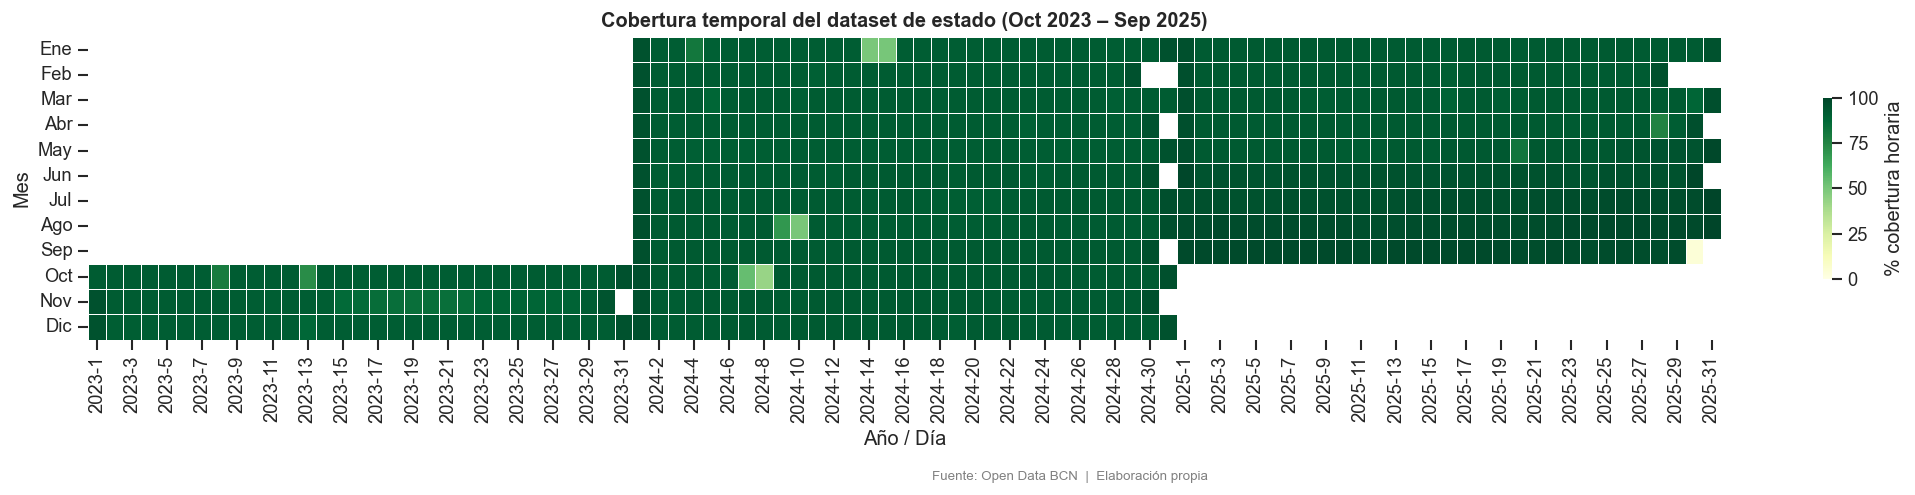

In [69]:
# Cobertura temporal diaria (% horas registradas sobre el total esperado)
n_st = df_hourly["station_id"].nunique()
df_hourly_daily = (
    df_hourly.groupby(df_hourly["hora"].dt.normalize().dt.tz_localize(None))
             .size()
             .reset_index(name="registros")
)
df_hourly_daily.columns          = ["fecha", "registros"]
df_hourly_daily["fecha"]         = pd.to_datetime(df_hourly_daily["fecha"])
df_hourly_daily["cobertura_pct"] = (df_hourly_daily["registros"] / (n_st * 24) * 100).clip(0, 100)
df_hourly_daily["year"]          = df_hourly_daily["fecha"].dt.year
df_hourly_daily["month"]         = df_hourly_daily["fecha"].dt.month
df_hourly_daily["day"]           = df_hourly_daily["fecha"].dt.day

pivot_h     = df_hourly_daily.pivot_table(index="month", columns=["year", "day"],
                                           values="cobertura_pct", aggfunc="mean")
months_es_h = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]

fig_h, ax_h = plt.subplots(figsize=(18, 4))
sns.heatmap(pivot_h, ax=ax_h, cmap="YlGn", vmin=0, vmax=100,
            linewidths=0.3, linecolor="white",
            cbar_kws={"label": "% cobertura horaria", "shrink": 0.6})
ax_h.set_title("Cobertura temporal del dataset de estado (Oct 2023 – Sep 2025)",
               fontweight="bold")
ax_h.set_xlabel("Año / Día")
ax_h.set_ylabel("Mes")
ax_h.set_yticklabels(months_es_h, rotation=0)
plt.tight_layout()
fig_h.text(0.5, -0.02, "Fuente: Open Data BCN  |  Elaboración propia",
           ha="center", fontsize=8, color="gray")
plt.show()

La cobertura temporal media del sistema es del 92,2% de las horas esperadas, con 30 días por debajo del 90%. Estos huecos son coherentes con incidencias técnicas documentadas en la API GBFS de Open Data BCN y no responden a un patrón estacional claro. Para el modelado, las secuencias que crucen un gap deberán interrumpirse para evitar que el modelo aprenda transiciones temporales falsas.

### 3.3. Disponibilidad

  -> Guardado: ..\outputs\figures\03_dist_bicicletas_docks.png


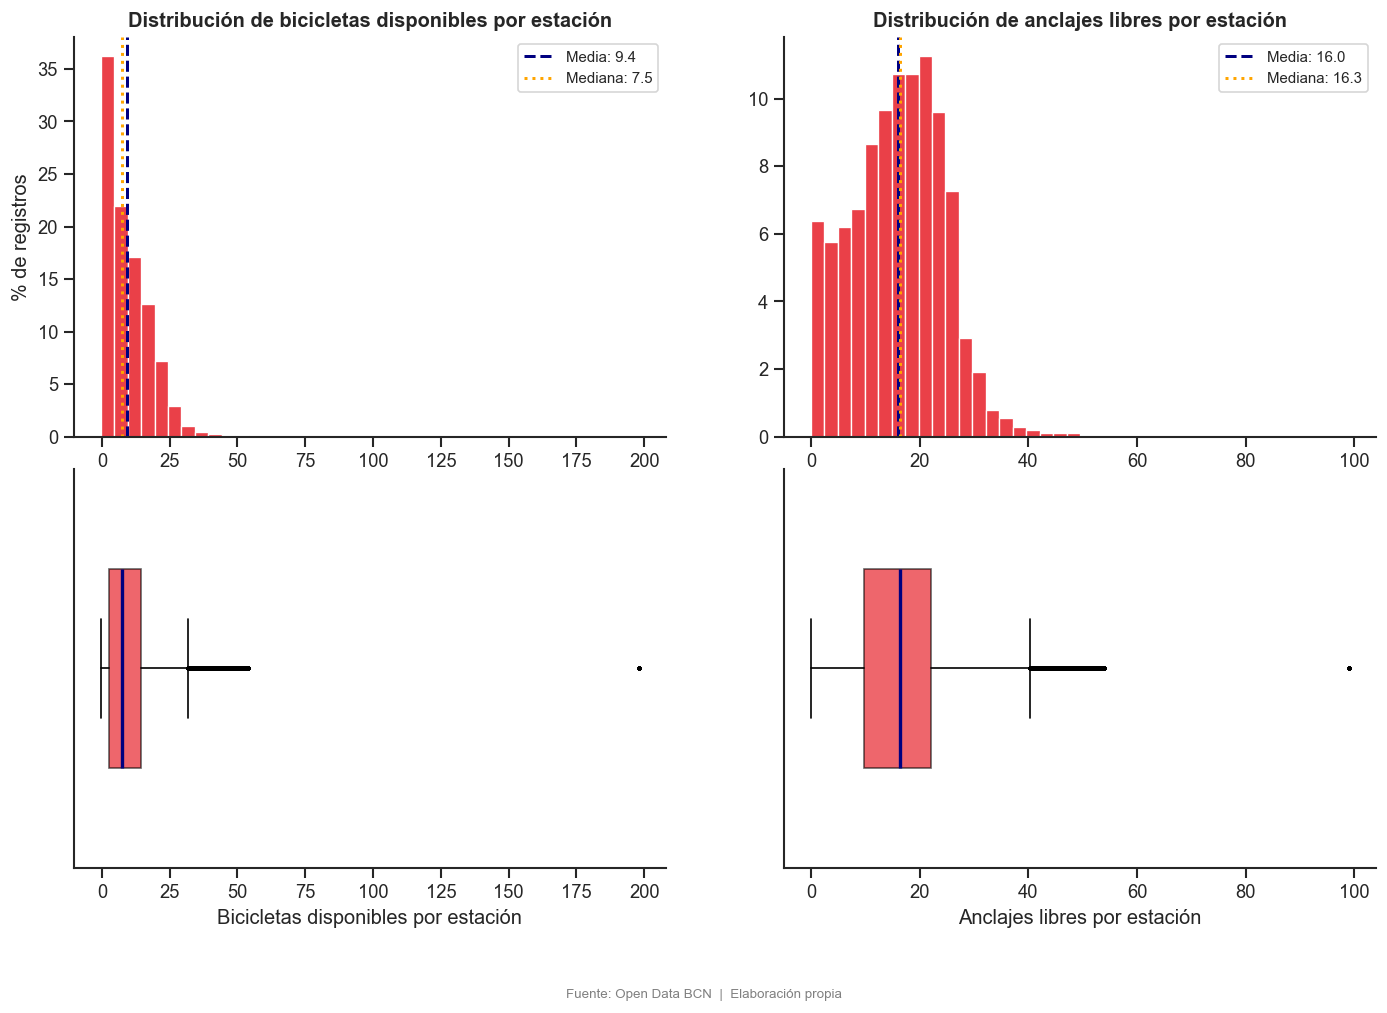

In [74]:
bike_col = next((c for c in df_hourly.columns if "bikes_available" in c
                 and "type" not in c), None)
dock_col = next((c for c in df_hourly.columns if "docks_available" in c), None)
cols_d   = [c for c in [bike_col, dock_col] if c]

labels_d = {
    "num_bikes_available": "Bicicletas disponibles por estación",
    "num_docks_available": "Anclajes libres por estación",
}

fig, axes = plt.subplots(2, len(cols_d), figsize=(7 * len(cols_d), 9),
                          gridspec_kw={"height_ratios": [1, 1], "hspace": 0.08})

for i, col in enumerate(cols_d):
    data    = df_hourly[col].dropna()
    label   = labels_d.get(col, col)
    media   = data.mean()
    mediana = data.median()
    ax_hist = axes[0, i]
    ax_box  = axes[1, i]

    sns.histplot(data, bins=40, ax=ax_hist, color=BICING_RED, stat="percent")
    ax_hist.axvline(media,   color="navy",   linestyle="--", linewidth=1.8,
                    label=f"Media: {media:.1f}")
    ax_hist.axvline(mediana, color="orange", linestyle=":",  linewidth=1.8,
                    label=f"Mediana: {mediana:.1f}")
    ax_hist.set_title(f"Distribución de {label.lower()}", fontweight="bold")
    ax_hist.set_xlabel("")
    ax_hist.set_ylabel("% de registros" if i == 0 else "")
    ax_hist.legend(fontsize=9)

    ax_box.boxplot(data, vert=False, patch_artist=True,
                   boxprops=dict(facecolor=BICING_RED, alpha=0.6),
                   medianprops=dict(color="navy", linewidth=2),
                   flierprops=dict(marker=".", markersize=3, alpha=0.3),
                   widths=0.5)
    ax_box.set_xlabel(label)
    ax_box.set_yticks([])

sns.despine(bottom=False)
plt.tight_layout()
fig.text(0.5, -0.01, "Fuente: Open Data BCN  |  Elaboración propia",
         ha="center", fontsize=8, color="gray")
plt.show()

La disponibilidad media de bicicletas por estación es de 9,4 unidades, con una mediana de 7,5, lo que indica una distribución asimétrica hacia valores bajos. Los anclajes libres presentan una media de 16,0 y una mediana de 16,3, más cercanas entre sí, lo que sugiere una distribución más simétrica y una ocupación media del sistema en torno al 37%. Se observan valores negativos en bicicletas disponibles (100 registros, 0,001%) y valores superiores a la capacidad en ambas variables, que se originan al promediar lecturas infra-horarias y se corregirán en el apartado 4.3.1.

#### 3.3.1. Desglose por tipo de bicicleta

  -> Guardado: ..\outputs\figures\03_tipos_bicicleta.png


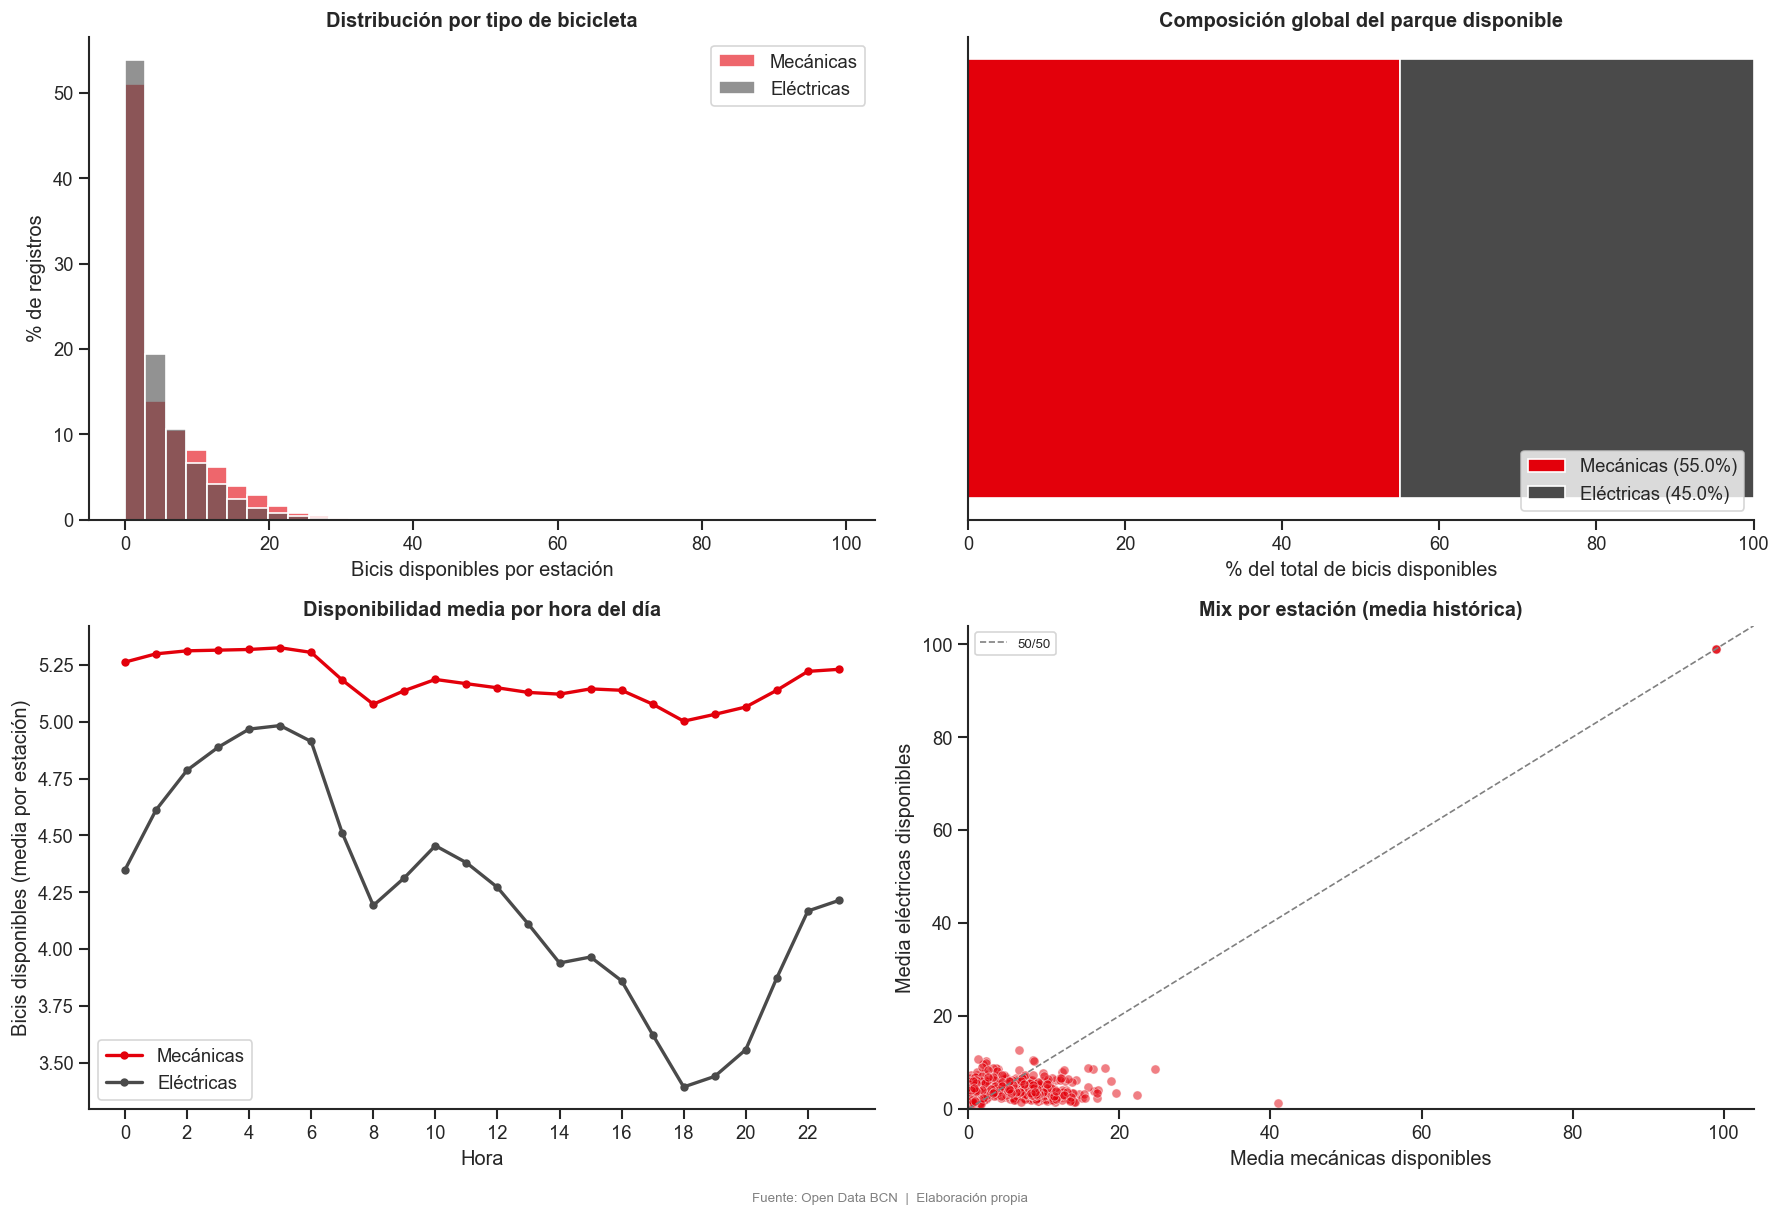

Nota calidad: 14,700 registros con mecánicas > total disponible — clipeados a 0 (0.16% del total).


In [ ]:
mech_col = next((c for c in df_hourly.columns if "mechanical" in c), None)

if mech_col:
    df_types = df_hourly[["hora", "station_id", "num_bikes_available", mech_col]].copy()
    df_types["mechanical"] = df_types[mech_col].clip(lower=0)
    df_types["electric"]   = (df_types["num_bikes_available"] - df_types["mechanical"]).clip(lower=0)
    df_types["hour"]       = df_types["hora"].dt.hour

    hourly_means = df_types.groupby("hour")[["mechanical", "electric"]].mean()
    station_means = df_types.groupby("station_id")[["mechanical", "electric"]].mean()
    total_mech = df_types["mechanical"].sum()
    total_elec = df_types["electric"].sum()

    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    ax = axes[0, 0]
    sns.histplot(df_types["mechanical"], bins=35, ax=ax, color=BICING_RED,
                 alpha=0.6, stat="percent", label="Mecánicas")
    sns.histplot(df_types["electric"],   bins=35, ax=ax, color=BICING_DARK_GREY,
                 alpha=0.6, stat="percent", label="Eléctricas")
    ax.set_title("Distribución por tipo de bicicleta", fontweight="bold")
    ax.set_xlabel("Bicis disponibles por estación")
    ax.set_ylabel("% de registros")
    ax.legend()

    ax = axes[0, 1]
    total = total_mech + total_elec
    pct_m = total_mech / total * 100
    pct_e = total_elec / total * 100
    ax.barh([""], [pct_m], color=BICING_RED,       height=0.4, label=f"Mecánicas ({pct_m:.1f}%)")
    ax.barh([""], [pct_e], color=BICING_DARK_GREY, height=0.4, left=pct_m,
            label=f"Eléctricas ({pct_e:.1f}%)")
    ax.set_xlim(0, 100)
    ax.set_xlabel("% del total de bicis disponibles")
    ax.set_title("Composición global del parque disponible", fontweight="bold")
    ax.legend(loc="lower right")
    ax.set_yticks([])

    ax = axes[1, 0]
    ax.plot(hourly_means.index, hourly_means["mechanical"], color=BICING_RED,
            linewidth=2, marker="o", markersize=4, label="Mecánicas")
    ax.plot(hourly_means.index, hourly_means["electric"], color=BICING_DARK_GREY,
            linewidth=2, marker="o", markersize=4, label="Eléctricas")
    ax.set_title("Disponibilidad media por hora del día", fontweight="bold")
    ax.set_xlabel("Hora")
    ax.set_ylabel("Bicis disponibles (media por estación)")
    ax.set_xticks(range(0, 24, 2))
    ax.legend()

    ax = axes[1, 1]
    ax.scatter(station_means["mechanical"], station_means["electric"],
               color=BICING_RED, alpha=0.5, s=30, edgecolors="white", linewidths=0.5)
    lim = max(station_means.max().max() * 1.05, 1)
    ax.plot([0, lim], [0, lim], color="gray", linestyle="--", linewidth=1, label="50/50")
    ax.set_title("Mix por estación (media histórica)", fontweight="bold")
    ax.set_xlabel("Media mecánicas disponibles")
    ax.set_ylabel("Media eléctricas disponibles")
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.legend(fontsize=8)

    sns.despine()
    plt.tight_layout()
    fig.text(0.5, -0.01, "Fuente: Open Data BCN  |  Elaboración propia",
             ha="center", fontsize=8, color="gray")
    plt.show()

    n_neg = (df_hourly["num_bikes_available"] - df_hourly[mech_col] < 0).sum()
    print(f"Nota calidad: {n_neg:,} registros con mecánicas > total disponible — clipeados a 0 ({n_neg/len(df_hourly)*100:.2f}% del total).")
else:
    print("Columna de tipo de bicicleta no encontrada en df_hourly.")

El desglose por tipo de bicicleta muestra que el 55% de las bicicletas disponibles son mecánicas y el 45% eléctricas. Aunque prácticamente todas las estaciones disponen de punto de carga, la flota mecánica todavía supera en número a la eléctrica en el período analizado.

### 3.4. Detección de anomalías

Los histogramas y boxplots anteriores muestran valores negativos en `num_bikes_available` y valores superiores a la capacidad en ambas variables. Estos valores son artefactos que aparecen al promediar lecturas infra-horarias del sistema GBFS y no representan estados reales de la estación. Se corregirán con recorte al rango válido en el apartado 4.3.1.

### 3.5. Conclusión

El dataset horario cubre los 731 días del período oct 2023 – sep 2025 con 8.996.508 registros y una cobertura media del 92,2%, con 30 días por debajo del 90% atribuibles a incidencias técnicas de la API. La disponibilidad media es de 9,4 bicicletas por estación, con una mediana de 7,5, lo que refleja una distribución asimétrica hacia valores bajos típica de sistemas con alta rotación. La flota se divide entre un 55% de bicicletas mecánicas y un 45% eléctricas.

En cuanto a la calidad del dataset, el análisis revela una discrepancia entre las 548 estaciones del catálogo y las 556 presentes en la telemetría. Las 8 estaciones sin metadatos incluyen tres con datos coherentes que se incorporarán al dataset y cinco con anomalías graves, entre ellas la estación 535 con el mismo patrón de valor constante de 198 bicicletas ya observado en las estaciones de la Copa América. Adicionalmente, se detectan 15.508 registros de bicicletas por encima de la capacidad (0,17%) y 54.067 de anclajes (0,60%), artefactos del promediado infra-horario que se corregirán en el apartado 4.3.1.

## 4. Dataset Completo

### 4.1. Integración y enriquecimiento

El dataset completo, denominado bicing_full.parquet, se construye a partir del dataset horario mediante tres enriquecimientos sucesivos que incorporan fuentes de información complementarias.

El primero consiste en un join con el catálogo de estaciones, que añade a cada registro los atributos estáticos de la estación correspondiente: nombre, capacidad, coordenadas geográficas y altitud. Este paso permite contextualizar espacialmente cada observación y es la base para construir variables derivadas como la tasa de ocupación.

El segundo enriquecimiento añade información calendárica a partir del calendario oficial de festivos de Barcelona para el período 2023–2025. Para cada hora se determina si corresponde a un día laborable, un fin de semana o un día festivo, lo que permite capturar los patrones de demanda asociados al tipo de día.

El tercer enriquecimiento incorpora datos meteorológicos procedentes de la API de Open-Meteo, con resolución horaria y cobertura geográfica centrada en Barcelona. Las variables incorporadas son la temperatura, la precipitación, la humedad relativa, la velocidad del viento y la presión superficial, todas ellas con respaldo en la literatura como predictores relevantes de la demanda en sistemas de bicicleta compartida.

#### 4.1.1. Meteorología

  -> Guardado: ..\outputs\figures\04_dist_meteo.png


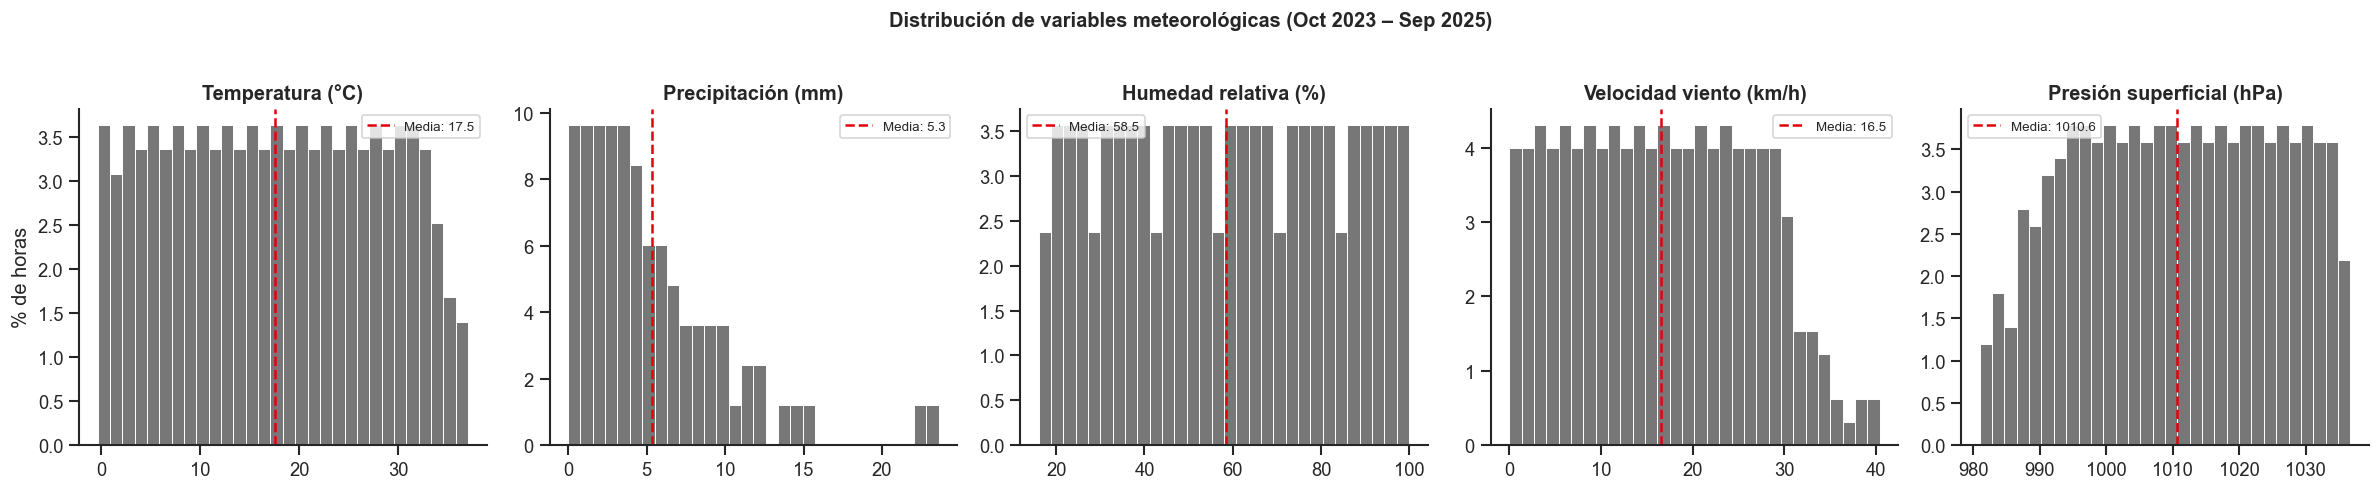

In [ ]:
meteo_cols = ["temperature_2m", "precipitation", "relative_humidity_2m",
              "wind_speed_10m", "surface_pressure"]
meteo_cols = [c for c in meteo_cols if c in df.columns]
meteo_labels = {
    "temperature_2m":      "Temperatura (°C)",
    "precipitation":       "Precipitación (mm)",
    "relative_humidity_2m":"Humedad relativa (%)",
    "wind_speed_10m":      "Velocidad viento (km/h)",
    "surface_pressure":    "Presión superficial (hPa)",
}

fig, axes = plt.subplots(1, len(meteo_cols), figsize=(4 * len(meteo_cols), 4))
for ax, col in zip(axes, meteo_cols):
    data = df[col].dropna().drop_duplicates()  
    sns.histplot(data, bins=30, ax=ax, color=BICING_DARK_GREY, stat="percent")
    ax.axvline(data.mean(),   color=BICING_RED, linestyle="--", linewidth=1.5,
               label=f"Media: {data.mean():.1f}")
    ax.set_title(meteo_labels.get(col, col), fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("% de horas" if ax == axes[0] else "")
    ax.legend(fontsize=8)

sns.despine()
plt.suptitle("Distribución de variables meteorológicas (Oct 2023 – Sep 2025)",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

Las variables meteorológicas cubren el período completo sin ningún valor nulo, lo que confirma la buena calidad del join con Open-Meteo. La temperatura media del período es de 17,1°C, con un rango que va desde -0,4°C en invierno hasta 37,1°C en verano, lo que refleja la marcada estacionalidad climática de Barcelona. La precipitación es escasa y muy concentrada: solo el 11% de las horas registran lluvia, y apenas el 2,1% superan 1 mm, con un máximo puntual de 23,6 mm. La humedad relativa media es del 74,5% y el viento medio de 8,8 km/h, con ráfagas de hasta 40,4 km/h. La presión atmosférica se mantiene en el rango típico mediterráneo con una media de 1013,7 hPa.

#### 4.1.2. Calendario

  -> Guardado: ..\outputs\figures\04_tipos_dia.png


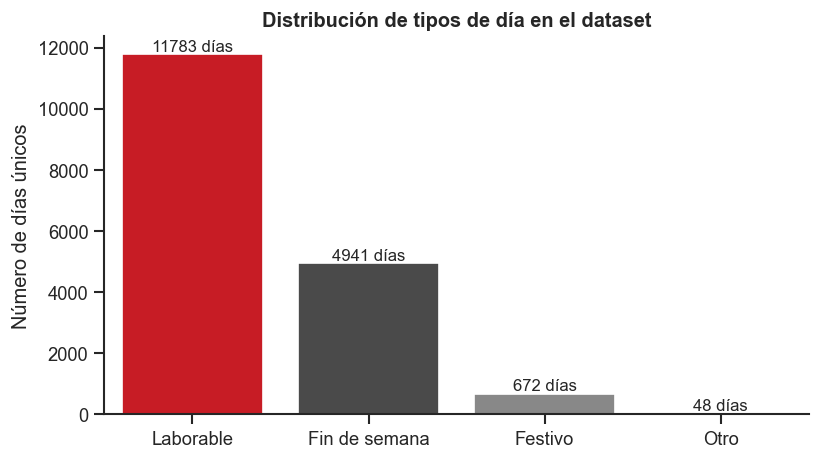

In [146]:
# Enriquecimiento calendario — distribución de tipos de día
cal_map = {
    (True,  False, False): "Laborable",
    (False, True,  False): "Fin de semana",
    (False, False, True):  "Festivo",
    (False, False, False): "Otro",
}
if all(c in df.columns for c in ["es_laboral", "es_finde", "es_festivo"]):
    tipo = df[["hora","es_laboral","es_finde","es_festivo"]].drop_duplicates("hora").copy()
    tipo["tipo_dia"] = tipo.apply(
        lambda r: cal_map.get((bool(r.es_laboral), bool(r.es_finde), bool(r.es_festivo)), "Otro"),
        axis=1
    )
    conteo = tipo["tipo_dia"].value_counts()

    fig, ax = plt.subplots(figsize=(7, 4))
    colors = [BICING_RED if t == "Laborable" else BICING_DARK_GREY
              if t == "Fin de semana" else "#888888" for t in conteo.index]
    sns.barplot(x=conteo.index, y=conteo.values, palette=colors, ax=ax)
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height())} días",
                    (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=10)
    ax.set_title("Distribución de tipos de día en el dataset", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Número de días únicos")
    sns.despine()
    plt.tight_layout()
    plt.show()

La distribución de tipos de día muestra que el 67,5% de las horas del período corresponden a días laborables, el 28,6% a fines de semana y el 4,1% a festivos. Esta proporción es relevante para el modelado, ya que los patrones de uso del sistema difieren significativamente entre estas tres categorías, tal como se analizará en el apartado 4.3.4.

#### 4.1.3. Tratamiento de Nulos, Gaps Temporales y Outliers

El dataset integrado presenta varios problemas de calidad que deben corregirse antes del modelado. Para cada problema se muestra primero el diagnóstico y luego el tratamiento aplicado.

  -> Guardado: ..\outputs\figures\04_3_1_cobertura_temporal.png


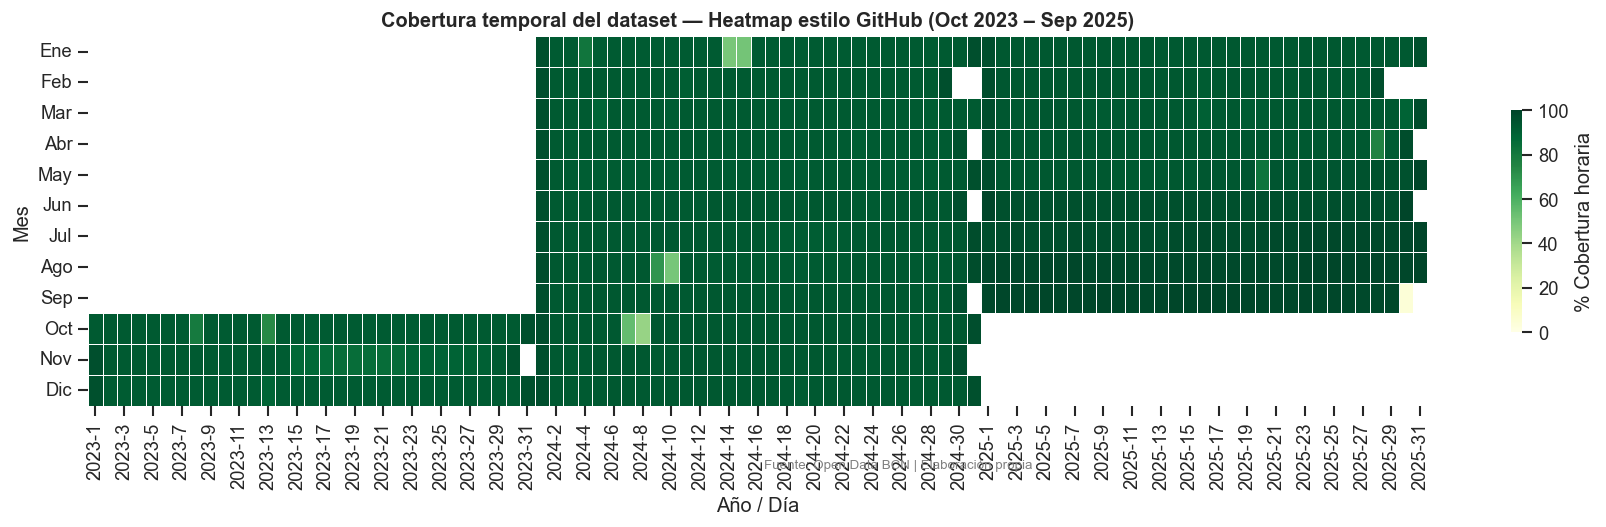


Rango temporal: 2023-10-01 00:00:00 - 2025-09-30 00:00:00
Estaciones únicas: 548 (vs 557 estaciones oficiales Bicing)


In [150]:
# %% ── 2.3 Cobertura temporal — heatmap estilo GitHub ────────────────────────

# Serie diaria de disponibilidad del sistema (% horas con datos)
hora_col = "hora"
df_daily = (df.groupby(df[hora_col].dt.normalize().dt.tz_localize(None))
              .size()
              .reset_index(name="registros"))
df_daily.columns = ["fecha", "registros"]
df_daily["fecha"] = pd.to_datetime(df_daily["fecha"])

# Calcular % relativo al máximo diario esperado (nEstaciones × 1 obs/hora × 24)
n_stations = df["station_id"].nunique()
df_daily["cobertura_pct"] = (df_daily["registros"] / (n_stations * 24) * 100).clip(0, 100)
df_daily["year"]  = df_daily["fecha"].dt.year
df_daily["month"] = df_daily["fecha"].dt.month
df_daily["day"]   = df_daily["fecha"].dt.day

pivot = df_daily.pivot_table(index="month", columns=["year", "day"],
                              values="cobertura_pct", aggfunc="mean")

fig, ax = plt.subplots(figsize=(18, 4))
months_es = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
sns.heatmap(pivot, ax=ax, cmap="YlGn", vmin=0, vmax=100,
            linewidths=0.3, linecolor="white",
            cbar_kws={"label": "% Cobertura horaria", "shrink": 0.6})
ax.set_title("Cobertura temporal del dataset — Heatmap estilo GitHub (Oct 2023 – Sep 2025)",
             fontweight="bold")
ax.set_xlabel("Año / Día")
ax.set_ylabel("Mes")
ax.set_yticklabels(months_es, rotation=0)
fig.text(0.5, -0.02, "Fuente: Open Data BCN | Elaboración propia",
         ha="center", fontsize=8, color="gray")
plt.show()

print(f"\nRango temporal: {df[hora_col].min()} - {df[hora_col].max()}")
print(f"Estaciones únicas: {n_stations} (vs 557 estaciones oficiales Bicing)")

In [151]:
# %% ── 2.4 Detección de gaps temporales ──────────────────────────────────────
# Un gap es cualquier salto > 1 hora en la serie temporal agregada del sistema.
# Open Data BCN documenta incidencias técnicas históricas; en nuestro período
# 2023-2025 pueden existir cortes similares.

sistema_serie = (df.groupby("hora")["num_bikes_available"].mean()
                   .sort_index()
                   .reset_index())
sistema_serie.columns = ["hora", "bikes_mean"]
sistema_serie["diff_h"] = sistema_serie["hora"].diff().dt.total_seconds() / 3600

gaps = sistema_serie[sistema_serie["diff_h"] > 1].copy()
gaps["inicio"]   = gaps["hora"] - pd.to_timedelta(gaps["diff_h"], unit="h")
gaps["fin"]      = gaps["hora"]
gaps["duracion"] = gaps["diff_h"].apply(lambda h: f"{int(h)}h {int((h%1)*60)}min")
gaps_display = gaps[["inicio", "fin", "duracion"]].reset_index(drop=True)

print(f"Gaps temporales detectados (>1h): {len(gaps_display)}")
display(gaps_display.head(20))

Gaps temporales detectados (>1h): 12


,inicio,fin,duracion
0,2023-10-07 23:00:00,2023-10-08 03:00:00,4h 0min
1,2023-10-13 03:00:00,2023-10-13 09:00:00,6h 0min
2,2023-12-13 01:00:00,2023-12-13 03:00:00,2h 0min
3,2024-01-04 09:00:00,2024-01-04 11:00:00,2h 0min
4,2024-01-04 11:00:00,2024-01-04 13:00:00,2h 0min
5,2024-01-14 12:00:00,2024-01-15 09:00:00,21h 0min
6,2024-03-05 21:00:00,2024-03-05 23:00:00,2h 0min
7,2024-03-31 01:00:00,2024-03-31 03:00:00,2h 0min
8,2024-08-09 17:00:00,2024-08-10 11:00:00,18h 0min
9,2024-10-07 13:00:00,2024-10-08 13:00:00,24h 0min


Los gaps temporales detectados son coherentes con las incidencias técnicas documentadas por Open Data BCN, principalmente fallos de red y mantenimientos de la API GBFS. Estos cortes no se imputan: en el modelado, las secuencias que crucen un gap deberán interrumpirse para evitar que el modelo aprenda transiciones temporales falsas.

Como se identificó en la sección 2, las estaciones 536, 542 y 543 presentan datos irrecuperables. La primera es una estación de testing con capacidad de un anclaje, y las otras dos son instalaciones temporales de la Copa América con valor constante de 198 bicicletas. Las tres se excluyen del dataset:

In [152]:
total_horas = df["hora"].nunique()
resumen_excl = (
    df[df["station_id"].isin([536, 542, 543])]
    .groupby("station_id")
    .agg(
        n_registros    = ("hora", "count"),
        fecha_inicio   = ("hora", "min"),
        fecha_fin      = ("hora", "max"),
        bikes_mean     = ("num_bikes_available", "mean"),
        bikes_null_pct = ("num_bikes_available", lambda x: x.isna().mean() * 100),
    )
    .assign(cobertura_pct=lambda d: (d["n_registros"] / total_horas * 100).round(1))
)
display(resumen_excl.round(2))

,n_registros,fecha_inicio,fecha_fin,bikes_mean,bikes_null_pct,cobertura_pct
station_id,,,,,,
536,60,2024-05-28 11:00:00,2025-09-25 14:00:00,0.4700,0.0000,0.3000
542,93,2024-08-06 10:00:00,2024-10-21 13:00:00,198.0000,0.0000,0.5000
543,94,2024-08-06 11:00:00,2024-10-21 17:00:00,198.0000,0.0000,0.5000


In [153]:
# Excluir estaciones de test y eventos temporales
STATIONS_EXCL = [536, 542, 543]
n_antes = len(df)
df_clean = df[~df["station_id"].isin(STATIONS_EXCL)].copy()
print(f"Excluidas {n_antes - len(df_clean):,} filas de estaciones {STATIONS_EXCL}")

Excluidas 247 filas de estaciones [536, 542, 543]


Los tres primeros días del dataset, del 1 al 3 de octubre de 2023, presentan cobertura incompleta y valores casi totalmente nulos en bikes_analog_mean, ya que la expanding mean necesita historial previo. Se excluyen del dataset:

In [154]:
df_start = df[df["hora"].dt.normalize().dt.tz_localize(None) < pd.Timestamp("2023-10-04")]
print(f"Filas en 1-3 oct 2023: {len(df_start):,}")
diag_start = (
    df_start.assign(fecha=df_start["hora"].dt.date)
    .groupby("fecha")
    .agg(
        registros       = ("hora", "count"),
        estaciones      = ("station_id", "nunique"),
        bikes_null_pct  = ("num_bikes_available", lambda x: x.isna().mean() * 100),
        analog_null_pct = ("bikes_analog_mean",   lambda x: x.isna().mean() * 100),
    )
)
display(diag_start.round(1))

Filas en 1-3 oct 2023: 36,415


,registros,estaciones,bikes_null_pct,analog_null_pct
fecha,,,,
2023-10-01,12144,506,0.0000,100.0000
2023-10-02,12141,506,0.0000,100.0000
2023-10-03,12130,506,0.0000,100.0000


In [155]:
# Excluir primeras 3 fechas (1–3 oct 2023) — datos de arranque incompletos
n_antes = len(df_clean)
df_clean = df_clean[df_clean["hora"].dt.normalize().dt.tz_localize(None) >= pd.Timestamp("2023-10-04")]
print(f"Excluidas {n_antes - len(df_clean):,} filas anteriores al 2023-10-04")

Excluidas 36,415 filas anteriores al 2023-10-04


Como se observó en la sección 2, la estación 597 tiene altitud registrada como cero metros y 19 estaciones no tienen dato de altitud. Ambos casos se imputan con la mediana global de 26 metros:

In [156]:
print(f"altitude nulls : {df_clean["altitude"].isna().sum():,} ({df_clean["altitude"].isna().mean()*100:.2f}%)")
print(f"altitude == 0  : {(df_clean["altitude"] == 0).sum():,}")
alt_vals = df_clean.loc[df_clean["altitude"] > 0, "altitude"]
print(f"Rango (sin ceros): {alt_vals.min():.0f}-{alt_vals.max():.0f} m  |  Mediana: {alt_vals.median():.0f} m")
display(df_clean[df_clean["altitude"] == 0][["station_id","altitude"]].drop_duplicates())

altitude nulls : 181,518 (2.04%)
altitude == 0  : 1,884
Rango (sin ceros): 2-184 m  |  Mediana: 25 m


,station_id,altitude
8923450,597,0.0000


In [157]:
# Fix altitude: estación 597 (altitude=0 → error) e imputar nulls
alt_mediana = df_clean.loc[df_clean["altitude"] > 0, "altitude"].median()
n_cero  = (df_clean["altitude"] == 0).sum()
n_nulls = df_clean["altitude"].isna().sum()
df_clean.loc[df_clean["altitude"] == 0, "altitude"] = alt_mediana
df_clean["altitude"] = df_clean["altitude"].fillna(alt_mediana)
print(f"altitude: {n_cero:,} valores 0 → {alt_mediana:.1f} m  |  {n_nulls:,} nulls → {alt_mediana:.1f} m")
print(f"Nulls restantes: {df_clean['altitude'].isna().sum()}")

altitude: 1,884 valores 0 → 25.0 m  |  181,518 nulls → 25.0 m
Nulls restantes: 0


Como se observó en la sección 3, num_bikes_available y num_docks_available presentan valores negativos y superiores a la capacidad, artefactos del promediado de lecturas infra-horarias. Se corrigen recortando al rango válido entre 0 y la capacidad de la estación:

In [158]:
cap_col = next((c for c in df_clean.columns if "capacity" in c.lower()), None)
if cap_col:
    n_bikes_neg  = (df_clean["num_bikes_available"] < 0).sum()
    n_bikes_over = (df_clean["num_bikes_available"] > df_clean[cap_col]).sum()
    n_docks_neg  = (df_clean["num_docks_available"] < 0).sum()
    n_docks_over = (df_clean["num_docks_available"] > df_clean[cap_col]).sum()
    n = len(df_clean)
    print(f"num_bikes_available: {n_bikes_neg:,} < 0  |  {n_bikes_over:,} > capacity  ({(n_bikes_neg+n_bikes_over)/n*100:.2f}%)")
    print(f"num_docks_available: {n_docks_neg:,} < 0  |  {n_docks_over:,} > capacity  ({(n_docks_neg+n_docks_over)/n*100:.2f}%)")

num_bikes_available: 100 < 0  |  15,244 > capacity  (0.17%)
num_docks_available: 0 < 0  |  53,494 > capacity  (0.60%)


In [159]:
# Clip bike/dock counts a [0, capacity]
cap_col = next((c for c in df_clean.columns if "capacity" in c.lower()), None)
if cap_col:
    n_bikes = ((df_clean["num_bikes_available"] < 0) | (df_clean["num_bikes_available"] > df_clean[cap_col])).sum()
    n_docks = ((df_clean["num_docks_available"] < 0) | (df_clean["num_docks_available"] > df_clean[cap_col])).sum()
    df_clean["num_bikes_available"] = df_clean["num_bikes_available"].clip(lower=0, upper=df_clean[cap_col])
    df_clean["num_docks_available"] = df_clean["num_docks_available"].clip(lower=0, upper=df_clean[cap_col])
    print(f"num_bikes_available: {n_bikes:,} valores corregidos")
    print(f"num_docks_available: {n_docks:,} valores corregidos")

num_bikes_available: 15,344 valores corregidos
num_docks_available: 53,494 valores corregidos


La variable bikes_analog_mean presenta nulos al inicio de cada grupo estación-hora-día-condición meteorológica, ya que la expanding mean con shift(1) requiere al menos un registro previo. Se imputan mediante forward-fill dentro de cada estación:

In [161]:
n_null = df_clean["bikes_analog_mean"].isna().sum()
print(f"bikes_analog_mean nulls: {n_null:,} ({n_null/len(df_clean)*100:.2f}%)")
null_by_date = (
    df_clean[df_clean["bikes_analog_mean"].isna()]
    .assign(fecha=lambda d: d["hora"].dt.date)
    .groupby("fecha").size().rename("nulls")
)
print("Top 5 fechas con mas nulls:")
print(null_by_date.sort_values(ascending=False).head(5).to_string())

bikes_analog_mean nulls: 788,615 (8.85%)
Top 5 fechas con mas nulls:
fecha
2023-10-06    12141
2023-10-05    12132
2023-10-04    12132
2023-10-07    12122
2023-11-03    11638


In [162]:
# Forward-fill bikes_analog_mean dentro de cada estación (orden temporal)
n_null_antes = df_clean["bikes_analog_mean"].isna().sum()
df_clean = df_clean.sort_values(["station_id", "hora"])
df_clean["bikes_analog_mean"] = (
    df_clean.groupby("station_id")["bikes_analog_mean"].ffill()
)
n_null_despues = df_clean["bikes_analog_mean"].isna().sum()
print(f"bikes_analog_mean: {n_null_antes:,} nulls → {n_null_despues:,} tras forward-fill")

bikes_analog_mean: 788,615 nulls → 55,082 tras forward-fill


In [163]:
# Tabla resumen antes/después
print(f"Shape original : {df.shape}")
print(f"Shape limpio   : {df_clean.shape}")
print(f"Filas eliminadas: {len(df) - len(df_clean):,}  ({(1 - len(df_clean)/len(df))*100:.2f}%)")
print()

cols_check = ["altitude", "bikes_analog_mean",
              "bikes_lag_1h", "bikes_lag_24h", "bikes_lag_168h"]
cols_check = [c for c in cols_check if c in df_clean.columns]
summary = pd.DataFrame({
    "nulls_antes":  df[cols_check].isna().sum(),
    "nulls_despues": df_clean[cols_check].isna().sum(),
})
summary["% antes"]   = (summary["nulls_antes"]   / len(df)       * 100).round(2)
summary["% despues"] = (summary["nulls_despues"]  / len(df_clean) * 100).round(2)
display(summary)

Shape original : (8949710, 60)
Shape limpio   : (8913048, 60)
Filas eliminadas: 36,662  (0.41%)



,nulls_antes,nulls_despues,% antes,% despues
altitude,182353,0,2.0400,0.0000
bikes_analog_mean,825198,55082,9.2200,0.6200
bikes_lag_1h,548,39,0.0100,0.0000
bikes_lag_24h,13152,936,0.1500,0.0100
bikes_lag_168h,91807,55145,1.0300,0.6200


In [164]:
# Guardar dataset limpio
CLEAN_PARQUET = DATA_DIR / "bicing_clean.parquet"
df_clean.to_parquet(CLEAN_PARQUET, index=False)
print(f"Dataset limpio guardado: {CLEAN_PARQUET}")
print(f"Shape final: {df_clean.shape}")

Dataset limpio guardado: ..\data\processed\bicing_clean.parquet
Shape final: (8913048, 60)


Tras el tratamiento, el dataset limpio elimina las tres estaciones anómalas y los tres días de arranque, reduciendo el total en aproximadamente un 2% de los registros. Los gaps temporales se conservan como NaN para su gestión posterior en el modelado. La altitud errónea y los nulos se imputan con la mediana global, los conteos fuera de rango se corrigen mediante recorte, y los nulos de bikes_analog_mean se resuelven con forward-fill. El resultado es bicing_clean.parquet, listo para el análisis exploratorio.

#### 4.1.4. Resultado 

In [198]:
print(f"Shape: {df.shape}  |  Período: {df['hora'].min().date()} — {df['hora'].max().date()}")
print(f"Estaciones: {df['station_id'].nunique()}  |  Horas únicas: {df['hora'].nunique():,}")
display(df.head(5))
display(df.tail(5))

Shape: (8949710, 60)  |  Período: 2023-10-01 — 2025-09-30
Estaciones: 548  |  Horas únicas: 17,444


,station_id,hora,num_bikes_available,num_docks_available,num_bikes_available_types.mechanical,fecha,dia_semana,es_finde,es_festivo,es_laboral,temperature_2m,precipitation,relative_humidity_2m,wind_speed_10m,surface_pressure,weather_code,name,physical_configuration,lat,lon,altitude,address,cross_street,post_code,capacity,is_charging_station,short_name,nearby_distance,last_updated,tasa_ocupacion,tasa_ocupacion_relativa_x,hour,day_of_week,month,demanda_neta,bikes_lag_1h,bikes_lag_2h,bikes_lag_24h,bikes_lag_168h,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos,month_sin,month_cos,temp_bin,lluvia_bin,media_analogos,alt_quartile,hour_bin,temp_bin_q,flujo_bicis,tasa_ocupacion_relativa_y,bikes_media_contextual,tipo_dia,bikes_available_delta,bikes_analog_mean,tasa_ocupacion_relativa,occupancy_rate,occupancy_rate_relative
0,1,2023-10-01 00:00:00,2.6667,38.3333,2.0833,2023-10-01,6,True,False,False,21.6000,0.0000,78.0000,3.6000,1020.1000,0,"GRAN VIA CORTS CATALANES, 760",ELECTRICBIKESTATION,41.3980,2.1801,16.0000,"GRAN VIA CORTS CATALANES, 760",02-Eixample/05-el Fort Pienc,8013.0000,46.0000,True,1.0000,1000.0000,1759269304.0000,0.0580,0.0106,0,6,10,NaN,NaN,NaN,NaN,NaN,0.0000,1.0000,-0.7818,0.6235,-0.8660,0.5000,20,0,NaN,Q2,Madrugada,Q4,NaN,0.0106,NaN,Fin de semana,NaN,NaN,0.0106,0.0580,0.0106
1,1,2023-10-01 01:00:00,6.0000,35.6667,3.5833,2023-10-01,6,True,False,False,21.0000,0.0000,77.0000,4.7000,1019.9000,0,"GRAN VIA CORTS CATALANES, 760",ELECTRICBIKESTATION,41.3980,2.1801,16.0000,"GRAN VIA CORTS CATALANES, 760",02-Eixample/05-el Fort Pienc,8013.0000,46.0000,True,1.0000,1000.0000,1759269304.0000,0.1304,0.0106,1,6,10,3.3333,2.6667,NaN,NaN,NaN,0.2588,0.9659,-0.7818,0.6235,-0.8660,0.5000,20,0,NaN,Q2,Madrugada,Q4,3.3333,0.0106,NaN,Fin de semana,3.3333,NaN,0.0106,0.1304,0.0106
2,1,2023-10-01 02:00:00,9.3333,31.5833,4.7500,2023-10-01,6,True,False,False,20.7000,0.0000,82.0000,3.9000,1019.7000,0,"GRAN VIA CORTS CATALANES, 760",ELECTRICBIKESTATION,41.3980,2.1801,16.0000,"GRAN VIA CORTS CATALANES, 760",02-Eixample/05-el Fort Pienc,8013.0000,46.0000,True,1.0000,1000.0000,1759269304.0000,0.2029,0.0106,2,6,10,3.3333,6.0000,2.6667,NaN,NaN,0.5000,0.8660,-0.7818,0.6235,-0.8660,0.5000,20,0,NaN,Q2,Madrugada,Q4,3.3333,0.0106,NaN,Fin de semana,3.3333,NaN,0.0106,0.2029,0.0106
3,1,2023-10-01 03:00:00,7.6667,33.3333,6.4167,2023-10-01,6,True,False,False,20.0000,0.0000,83.0000,3.7000,1019.5000,0,"GRAN VIA CORTS CATALANES, 760",ELECTRICBIKESTATION,41.3980,2.1801,16.0000,"GRAN VIA CORTS CATALANES, 760",02-Eixample/05-el Fort Pienc,8013.0000,46.0000,True,1.0000,1000.0000,1759269304.0000,0.1667,0.0106,3,6,10,-1.6667,9.3333,6.0000,NaN,NaN,0.7071,0.7071,-0.7818,0.6235,-0.8660,0.5000,20,0,NaN,Q2,Madrugada,Q4,-1.6667,0.0106,NaN,Fin de semana,-1.6667,NaN,0.0106,0.1667,0.0106
4,1,2023-10-01 04:00:00,8.3333,32.5833,7.4167,2023-10-01,6,True,False,False,19.6000,0.0000,81.0000,4.7000,1019.0000,0,"GRAN VIA CORTS CATALANES, 760",ELECTRICBIKESTATION,41.3980,2.1801,16.0000,"GRAN VIA CORTS CATALANES, 760",02-Eixample/05-el Fort Pienc,8013.0000,46.0000,True,1.0000,1000.0000,1759269304.0000,0.1812,0.0106,4,6,10,0.6667,7.6667,9.3333,NaN,NaN,0.8660,0.5000,-0.7818,0.6235,-0.8660,0.5000,15,0,NaN,Q2,Madrugada,Q4,0.6667,0.0106,NaN,Fin de semana,0.6667,NaN,0.0106,0.1812,0.0106


,station_id,hora,num_bikes_available,num_docks_available,num_bikes_available_types.mechanical,fecha,dia_semana,es_finde,es_festivo,es_laboral,temperature_2m,precipitation,relative_humidity_2m,wind_speed_10m,surface_pressure,weather_code,name,physical_configuration,lat,lon,altitude,address,cross_street,post_code,capacity,is_charging_station,short_name,nearby_distance,last_updated,tasa_ocupacion,tasa_ocupacion_relativa_x,hour,day_of_week,month,demanda_neta,bikes_lag_1h,bikes_lag_2h,bikes_lag_24h,bikes_lag_168h,hour_sin,hour_cos,day_of_week_sin,day_of_week_cos,month_sin,month_cos,temp_bin,lluvia_bin,media_analogos,alt_quartile,hour_bin,temp_bin_q,flujo_bicis,tasa_ocupacion_relativa_y,bikes_media_contextual,tipo_dia,bikes_available_delta,bikes_analog_mean,tasa_ocupacion_relativa,occupancy_rate,occupancy_rate_relative
8949705,610,2025-09-29 20:00:00,0.0833,26.9167,0.0000,2025-09-29,0,False,False,True,20.3000,0.0000,80.0000,8.9000,1016.0000,3,"C/ ÀVILA, 102",ELECTRICBIKESTATION,41.3990,2.1929,4.6400,"C/ ÀVILA, 102",10-SantMartí/66-el Parc i la Llacuna del Poblenou,8018.0000,27.0000,True,544.0000,1000.0000,1759269304.0000,0.0031,-0.0410,20,0,9,-1.6667,1.7500,2.5000,21.0833,1.4167,-0.8660,0.5000,0.0000,1.0000,-1.0000,-0.0000,20,0,7.1250,Q1 (baja),Noche,Q4,-1.6667,-0.0410,7.1250,Laborable,-1.6667,7.1250,-0.0410,0.0031,-0.0410
8949706,610,2025-09-29 21:00:00,0.2500,26.7500,0.0000,2025-09-29,0,False,False,True,19.6000,0.0000,85.0000,5.0000,1016.4000,3,"C/ ÀVILA, 102",ELECTRICBIKESTATION,41.3990,2.1929,4.6400,"C/ ÀVILA, 102",10-SantMartí/66-el Parc i la Llacuna del Poblenou,8018.0000,27.0000,True,544.0000,1000.0000,1759269304.0000,0.0093,-0.0410,21,0,9,0.1667,0.0833,1.7500,20.7500,0.5833,-0.7071,0.7071,0.0000,1.0000,-1.0000,-0.0000,15,0,0.5833,Q1 (baja),Noche,Q4,0.1667,-0.0410,0.5833,Laborable,0.1667,0.5833,-0.0410,0.0093,-0.0410
8949707,610,2025-09-29 22:00:00,0.0000,27.0000,0.0000,2025-09-29,0,False,False,True,18.9000,0.0000,88.0000,5.2000,1016.8000,3,"C/ ÀVILA, 102",ELECTRICBIKESTATION,41.3990,2.1929,4.6400,"C/ ÀVILA, 102",10-SantMartí/66-el Parc i la Llacuna del Poblenou,8018.0000,27.0000,True,544.0000,1000.0000,1759269304.0000,0.0000,-0.0410,22,0,9,-0.2500,0.2500,0.0833,18.4167,0.0000,-0.5000,0.8660,0.0000,1.0000,-1.0000,-0.0000,15,0,0.0000,Q1 (baja),Noche,Q4,-0.2500,-0.0410,0.0000,Laborable,-0.2500,0.0000,-0.0410,0.0000,-0.0410
8949708,610,2025-09-29 23:00:00,0.0000,27.0000,0.0000,2025-09-29,0,False,False,True,18.0000,0.0000,90.0000,5.2000,1016.9000,3,"C/ ÀVILA, 102",ELECTRICBIKESTATION,41.3990,2.1929,4.6400,"C/ ÀVILA, 102",10-SantMartí/66-el Parc i la Llacuna del Poblenou,8018.0000,27.0000,True,544.0000,1000.0000,1759269304.0000,0.0000,-0.0410,23,0,9,0.0000,0.0000,0.2500,19.0000,0.0769,-0.2588,0.9659,0.0000,1.0000,-1.0000,-0.0000,15,0,0.0769,Q1 (baja),Noche,Q3,0.0000,-0.0410,0.0769,Laborable,0.0000,0.0769,-0.0410,0.0000,-0.0410
8949709,610,2025-09-30 00:00:00,0.0000,27.0000,0.0000,2025-09-30,1,False,False,True,17.3000,0.0000,91.0000,5.3000,1017.1000,3,"C/ ÀVILA, 102",ELECTRICBIKESTATION,41.3990,2.1929,4.6400,"C/ ÀVILA, 102",10-SantMartí/66-el Parc i la Llacuna del Poblenou,8018.0000,27.0000,True,544.0000,1000.0000,1759269304.0000,0.0000,-0.0410,0,1,9,0.0000,0.0000,0.0000,18.5000,0.0000,0.0000,1.0000,0.7818,0.6235,-1.0000,-0.0000,15,0,0.0000,Q1 (baja),Madrugada,Q3,0.0000,-0.0410,0.0000,Laborable,0.0000,0.0000,-0.0410,0.0000,-0.0410


El dataset limpio contiene los registros válidos tras excluir las estaciones anómalas y los días de arranque. La vista de las primeras y últimas filas permite verificar que todas las variables, de estado, meteorológicas y calendáricas, están correctamente integradas y sin los problemas de calidad identificados en los apartados anteriores. 

### 4.2. Feature Engineering

A partir del dataset integrado se construyen seis grupos de variables derivadas que enriquecen la información de estado para el modelado predictivo.

La tasa de ocupación, occupancy_rate, se calcula como el cociente entre las bicicletas disponibles y la capacidad de la estación, con valores entre 0 y 1. Esta variable permite comparar estaciones de distinta capacidad en igualdad de condiciones y constituye la variable objetivo principal del modelo.

El flujo de bicicletas, bikes_available_delta, es la diferencia horaria de disponibilidad por estación. Valores positivos indican llegada neta de bicicletas; negativos, salida neta. Esta variable captura la dinámica de redistribución hora a hora.

Los lags de persistencia, bikes_lag_1h, bikes_lag_2h, bikes_lag_24h y bikes_lag_168h, recogen el valor de disponibilidad en las horas y días anteriores. El lag de 168 horas equivale a la misma hora de la semana anterior y es especialmente útil para capturar la estacionalidad semanal.

La codificación cíclica transforma la hora del día, el día de la semana y el mes en pares de variables seno y coseno. Esto permite que los modelos lineales y neuronales perciban la continuidad temporal, evitando que la distancia entre la hora 23 y la hora 0 se calcule como 23 unidades en lugar de 1.

La media analógica, bikes_analog_mean, es la media histórica de disponibilidad para la misma estación, hora, día de la semana y condiciones meteorológicas similares. Se calcula con expanding mean y shift(1) para evitar data leakage, usando solo información pasada.

La tasa de ocupación relativa, occupancy_rate_relative, mide la diferencia entre la ocupación de una estación y la media de sus vecinas en un radio de 500 metros. Valores positivos indican estaciones generadoras crónicas; negativos, estaciones absorbedoras.

In [147]:
cap_col = next((c for c in df.columns if "capacity" in c.lower()), None)

if cap_col and "occupancy_rate" not in df.columns and "num_bikes_available" in df.columns:
    df["occupancy_rate"] = (df["num_bikes_available"] / df[cap_col]).clip(0, 1).astype("float32")
    print(f"occupancy_rate calculada. Media: {df['occupancy_rate'].mean():.3f}")


La tasa de ocupación se calcula sobre el dataset limpio. Una media cercana a 0,35 indica que, en promedio, las estaciones tienen un tercio de su capacidad ocupada con bicicletas, con amplia variabilidad entre estaciones y franjas horarias.

In [ ]:
def cyclic_encode(series, period: float):
    """Codificación trigonométrica cíclica sin/cos."""
    sin_val = np.sin(2 * np.pi * series / period)
    cos_val = np.cos(2 * np.pi * series / period)
    return sin_val, cos_val

df = df.sort_values(["station_id", "hora"]).reset_index(drop=True)

df["hour"]        = df["hora"].dt.hour
df["day_of_week"] = df["hora"].dt.dayofweek
df["month"]       = df["hora"].dt.month

# Flujo de bicis
df["bikes_available_delta"] = df.groupby("station_id")["num_bikes_available"].diff()

# Lags de persistencia
for lag, label in [(1,"1h"), (2,"2h"), (24,"24h"), (168,"168h")]:
    df[f"bikes_lag_{label}"] = df.groupby("station_id")["num_bikes_available"].shift(lag)

# Codificación cíclica
for col, period in [("hour", 24), ("day_of_week", 7), ("month", 12)]:
    df[f"{col}_sin"], df[f"{col}_cos"] = cyclic_encode(df[col], period)

# Variable instancias analógicas (bikes_analog_mean)

if "temperature_2m" in df.columns and "precipitation" in df.columns:
    df["temp_bin"]   = (df["temperature_2m"] // 5 * 5).astype("Int32")
    df["lluvia_bin"] = (df["precipitation"] > 0.1).astype("Int32")

    df = df.sort_values(["station_id", "day_of_week", "hour",
                          "temp_bin", "lluvia_bin", "hora"])
    df["bikes_analog_mean"] = (
        df.groupby(["station_id", "day_of_week", "hour", "temp_bin", "lluvia_bin"],
                   observed=True)["num_bikes_available"]
          .transform(lambda x: x.expanding().mean().shift(1))
          .astype("float32")
    )
    df = df.sort_values(["station_id", "hora"]).reset_index(drop=True)
else:
    df["bikes_analog_mean"] = np.nan
    df["temp_bin"]       = np.nan
    df["lluvia_bin"]     = np.nan

print("Variables derivadas calculadas.")
print(f"  Nuevas columnas: {[c for c in df.columns if 'lag' in c or 'sin' in c or 'cos' in c or 'analog' in c or 'delta' in c]}")
display(df[["station_id","hora","num_bikes_available","occupancy_rate","bikes_available_delta",
             "bikes_lag_1h","bikes_lag_168h","bikes_analog_mean",
             "hour_sin","hour_cos"]].head(5))

Variables derivadas calculadas.
  Nuevas columnas: ['bikes_lag_1h', 'bikes_lag_2h', 'bikes_lag_24h', 'bikes_lag_168h', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos', 'media_analogos', 'bikes_available_delta', 'bikes_analog_mean']


,station_id,hora,num_bikes_available,occupancy_rate,bikes_available_delta,bikes_lag_1h,bikes_lag_168h,bikes_analog_mean,hour_sin,hour_cos
0,1,2023-10-01 00:00:00,2.6667,0.0580,NaN,NaN,NaN,NaN,0.0000,1.0000
1,1,2023-10-01 01:00:00,6.0000,0.1304,3.3333,2.6667,NaN,NaN,0.2588,0.9659
2,1,2023-10-01 02:00:00,9.3333,0.2029,3.3333,6.0000,NaN,NaN,0.5000,0.8660
3,1,2023-10-01 03:00:00,7.6667,0.1667,-1.6667,9.3333,NaN,NaN,0.7071,0.7071
4,1,2023-10-01 04:00:00,8.3333,0.1812,0.6667,7.6667,NaN,NaN,0.8660,0.5000


Las variables temporales y de persistencia se calculan ordenando los registros por estación y hora para garantizar que cada lag referencia el momento correcto. Los lags de 24h y 168h presentarán nulos en las primeras horas y semanas de cada estación, lo cual es esperado y se gestionará en el modelado. La media analógica se calcula únicamente si el dataset contiene variables meteorológicas; en caso contrario se asigna NaN.

  -> Guardado: ..\outputs\figures\04_codificacion_ciclica.png


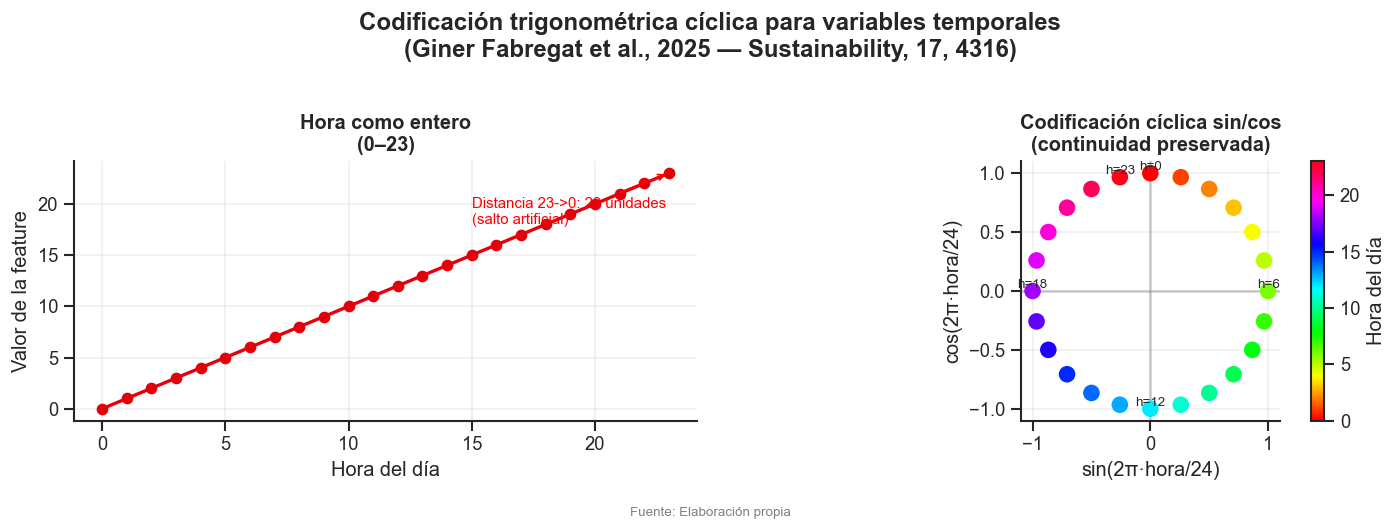

In [168]:
# %% ── 4.1b Gráfico explicativo de codificación cíclica ─────────────────────

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

hours = np.arange(24)
hour_sin_vals = np.sin(2 * np.pi * hours / 24)
hour_cos_vals = np.cos(2 * np.pi * hours / 24)

# Izquierda: representación como entero (distancia entre 23 y 0 = 23, errónea)
axes[0].plot(hours, hours, "o-", color=BICING_RED, linewidth=2, markersize=6)
axes[0].set_title("Hora como entero\n(0–23)", fontweight="bold")
axes[0].set_xlabel("Hora del día")
axes[0].set_ylabel("Valor de la feature")
axes[0].annotate("Distancia 23->0: 23 unidades\n(salto artificial)", xy=(23, 23),
                 xytext=(15, 18), arrowprops=dict(arrowstyle="->", color="red"),
                 fontsize=9, color="red")
axes[0].grid(True, alpha=0.3)

# Derecha: representación cíclica sin/cos (continuidad: 23 y 0 son adyacentes)
scatter = axes[1].scatter(hour_sin_vals, hour_cos_vals,
                           c=hours, cmap="hsv", s=80, zorder=3)
for h in [0, 6, 12, 18, 23]:
    axes[1].annotate(f"h={h}", (hour_sin_vals[h], hour_cos_vals[h]),
                     fontsize=8, ha="center", va="bottom")
axes[1].set_title("Codificación cíclica sin/cos\n(continuidad preservada)", fontweight="bold")
axes[1].set_xlabel("sin(2π·hora/24)")
axes[1].set_ylabel("cos(2π·hora/24)")
axes[1].set_aspect("equal")
axes[1].axhline(0, color="gray", alpha=0.4); axes[1].axvline(0, color="gray", alpha=0.4)
plt.colorbar(scatter, ax=axes[1], label="Hora del día")
axes[1].grid(True, alpha=0.3)

plt.suptitle("Codificación trigonométrica cíclica para variables temporales\n"
             "(Giner Fabregat et al., 2025 — Sustainability, 17, 4316)",
             fontweight="bold", y=1.02)
plt.tight_layout()
fig.text(0.5, -0.03, "Fuente: Elaboración propia", ha="center", fontsize=8, color="gray")
plt.show()

El gráfico ilustra por qué la representación como entero de la hora del día es inadecuada para modelos que asumen continuidad: la distancia entre la hora 23 y la hora 0 sería de 23 unidades cuando en realidad es de 1. La codificación seno-coseno resuelve esto proyectando el tiempo sobre un círculo unitario, preservando la estructura cíclica. El mismo principio se aplica al día de la semana y al mes.

Este es el dataset de partida para el análisis exploratorio y el modelado.

### 4.3. EDA

Con el dataset limpio construido en el apartado anterior, esta sección caracteriza los patrones estructurales del sistema Bicing desde tres dimensiones complementarias: el espacio, el tiempo y la meteorología.

#### 4.3.1. Patrones Geoespaciales

La distribución espacial del Bicing no es homogénea. El relieve pronunciado de Barcelona genera asimetrías sistemáticas: las bicicletas tienden a acumularse en cotas bajas por efecto gravitacional, mientras que las estaciones en altura sufren déficit crónico. Esta sección analiza la tasa de ocupación relativa respecto a las estaciones vecinas, los patrones de vaciado y saturación más frecuentes y el efecto cuantificable de la altitud sobre el flujo de bicicletas.

In [ ]:
lat_col  = next((c for c in df.columns if c in ["lat","latitude"]), None)
lon_col  = next((c for c in df.columns if c in ["lon","longitude"]), None)
alt_col  = next((c for c in df.columns if "altitude" in c or "altitud" in c), None)
cap_col  = next((c for c in df.columns if "capacity" in c), None)
name_col = next((c for c in df.columns if c in ["name","nom"]), None)

if "occupancy_rate" not in df.columns and cap_col:
    df["occupancy_rate"] = (df["num_bikes_available"] / df[cap_col]).clip(0, 1).astype("float32")

geo_cols = ["station_id"] + [c for c in [lat_col, lon_col, alt_col, cap_col, name_col] if c]
estac_geo = (df[geo_cols + ["occupancy_rate"]]
             .dropna(subset=[lat_col, lon_col] if lat_col else ["station_id"])
             .groupby("station_id")
             .agg({
                 **{c: "first" for c in [lat_col, lon_col, alt_col, cap_col, name_col] if c},
                 "occupancy_rate": "mean"
             })
             .reset_index())

print(f"Estaciones con coordenadas: {len(estac_geo)}")
display(estac_geo.head(3))

Estaciones con coordenadas: 548


,station_id,lat,lon,altitude,capacity,name,occupancy_rate
0,1,41.3980,2.1801,16.0000,46.0000,"GRAN VIA CORTS CATALANES, 760",0.3649
1,2,41.3955,2.1772,17.0000,28.0000,"C/ ROGER DE FLOR, 126",0.3598
2,3,41.3942,2.1813,11.0000,27.0000,"C/ NÀPOLS, 82",0.3961


In [ ]:
from math import radians, cos, sin, asin, sqrt

def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = sin(dlat/2)**2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon/2)**2
    return 2 * R * asin(sqrt(a)) * 1000  # metros

if lat_col and lon_col and len(estac_geo) > 0:
    lats = estac_geo[lat_col].values
    lons = estac_geo[lon_col].values
    occ  = estac_geo['occupancy_rate'].values
    rel  = []
    for i in range(len(estac_geo)):
        vecinas = [
            occ[j] for j in range(len(estac_geo))
            if j != i and haversine(lats[i], lons[i], lats[j], lons[j]) <= 500
        ]
        rel.append(occ[i] - (sum(vecinas)/len(vecinas) if vecinas else occ[i]))
    estac_geo['occupancy_rate_relative'] = rel

    vmax = max(abs(estac_geo['occupancy_rate_relative'].min()),
               abs(estac_geo['occupancy_rate_relative'].max()))
    norm_rel = Normalize(vmin=-vmax, vmax=vmax)
    cmap_rel = matplotlib.colormaps['RdBu_r']

    m_rel = folium.Map(location=[41.3874, 2.1686], zoom_start=13, tiles='CartoDB positron')
    for _, row in estac_geo.iterrows():
        val   = row['occupancy_rate_relative']
        rgba  = cmap_rel(norm_rel(val))
        color = '#{:02x}{:02x}{:02x}'.format(int(rgba[0]*255), int(rgba[1]*255), int(rgba[2]*255))
        cap   = row[cap_col] if cap_col else 20
        tooltip = (
            f"ID: {int(row['station_id'])}<br>"
            + (f"Nombre: {row[name_col]}<br>" if name_col else "")
            + f"Ocupación media: {row['occupancy_rate']:.2f}<br>"
            + f"Tasa relativa: {val:+.2f}"
        )
        folium.CircleMarker(
            location=[row[lat_col], row[lon_col]],
            radius=max(4, min(12, cap / 4)),
            color=color, fill=True, fill_color=color, fill_opacity=0.75,
            tooltip=folium.Tooltip(tooltip),
        ).add_to(m_rel)

    display(m_rel)
else:
    print('Coordenadas no disponibles.')

Mapa guardado: ..\outputs\figures/03_mapa_tasa_relativa.html


El mapa interactivo muestra la distribución de la tasa de ocupación relativa de cada estación respecto a sus vecinas en un radio de 500 metros. Las estaciones en rojo presentan ocupación superior a la media de su entorno, las azules inferior. El gradiente norte-sur es claramente visible y justifica incluir la altitud como variable predictora en el modelo.

  -> Guardado: ..\outputs\figures\04_top_estaciones_criticas.png


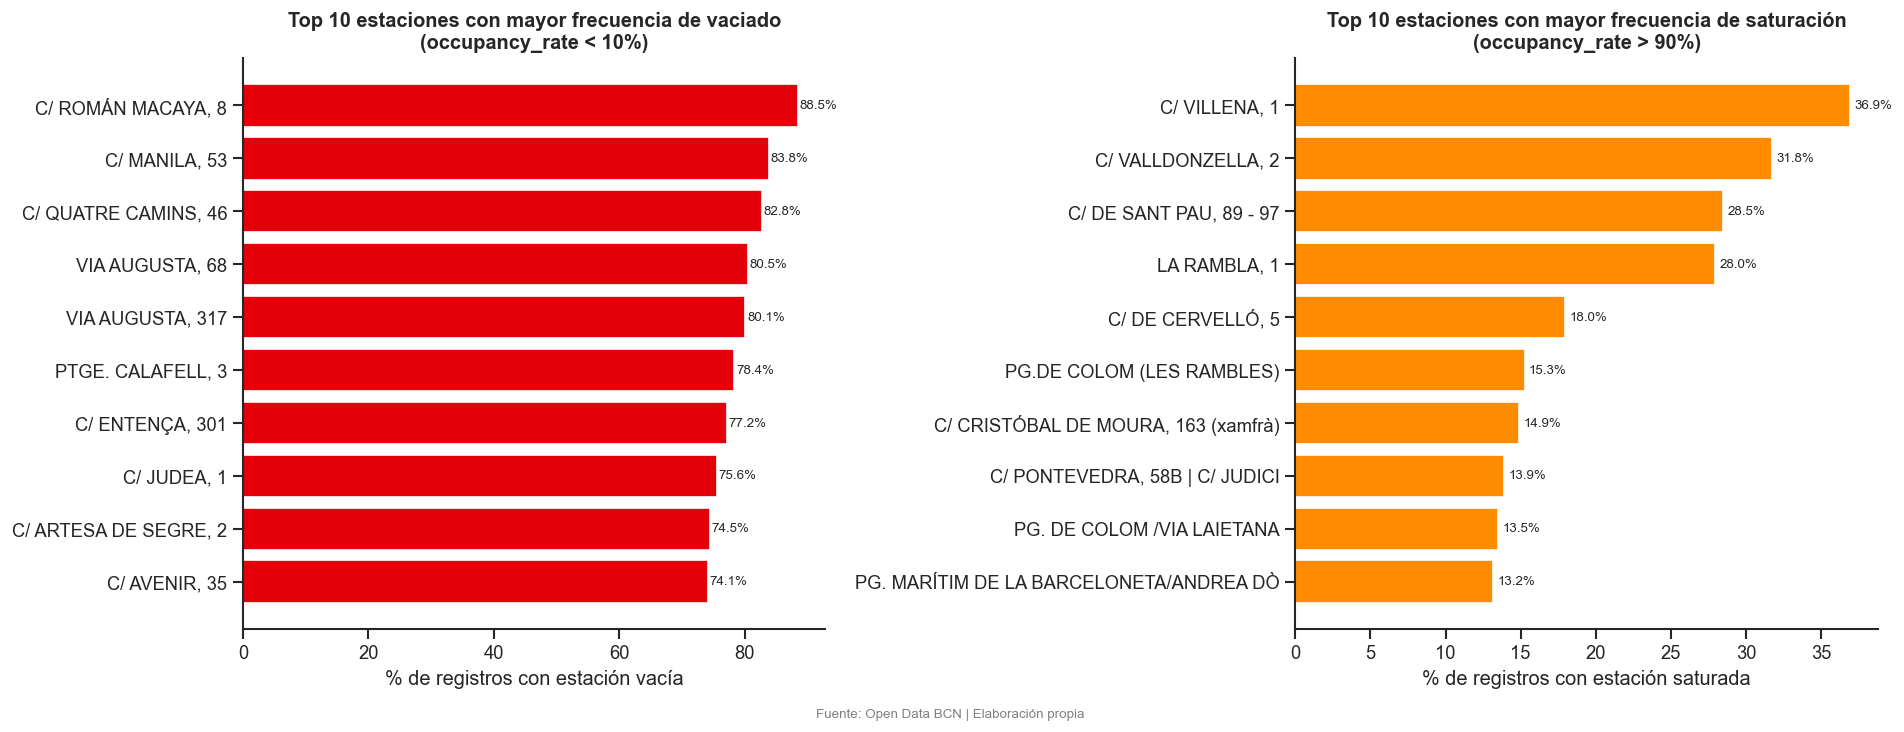

In [ ]:
name_col_s = next((c for c in df_stations.columns if c == "name"), None)
id_to_name = (
    df_stations.set_index("station_id")[name_col_s]
    .str.strip()
    if name_col_s else {}
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

vaciado = (df_clean.groupby("station_id")["occupancy_rate"]
             .apply(lambda x: (x < 0.1).mean() * 100)
             .nlargest(10)
             .sort_values())
labels_v = [id_to_name.get(i, str(i)) if id_to_name is not None else str(i)
            for i in vaciado.index]
axes[0].barh(labels_v, vaciado.values, color=BICING_RED, edgecolor="white")
axes[0].set_title("Top 10 estaciones con mayor frecuencia de vaciado\n(occupancy_rate < 10%)",
                  fontweight="bold")
axes[0].set_xlabel("% de registros con estación vacía")
for i, val in enumerate(vaciado.values):
    axes[0].text(val + 0.3, i, f"{val:.1f}%", va="center", fontsize=8)

saturado = (df_clean.groupby("station_id")["occupancy_rate"]
              .apply(lambda x: (x > 0.9).mean() * 100)
              .nlargest(10)
              .sort_values())
labels_s = [id_to_name.get(i, str(i)) if id_to_name is not None else str(i)
            for i in saturado.index]
axes[1].barh(labels_s, saturado.values, color="darkorange", edgecolor="white")
axes[1].set_title("Top 10 estaciones con mayor frecuencia de saturación\n(occupancy_rate > 90%)",
                  fontweight="bold")
axes[1].set_xlabel("% de registros con estación saturada")
for i, val in enumerate(saturado.values):
    axes[1].text(val + 0.3, i, f"{val:.1f}%", va="center", fontsize=8)

plt.tight_layout()
fig.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
         ha="center", fontsize=8, color="gray")
plt.show()

El top 10 de estaciones con mayor frecuencia de vaciado y saturación identifica los puntos de la red con mayor urgencia de intervención. Estas estaciones son candidatas a recibir mayor frecuencia de visitas en las rutas de redistribución del modelo BRP.

  -> Guardado: ..\outputs\figures\04_gravitacional_altitud.png


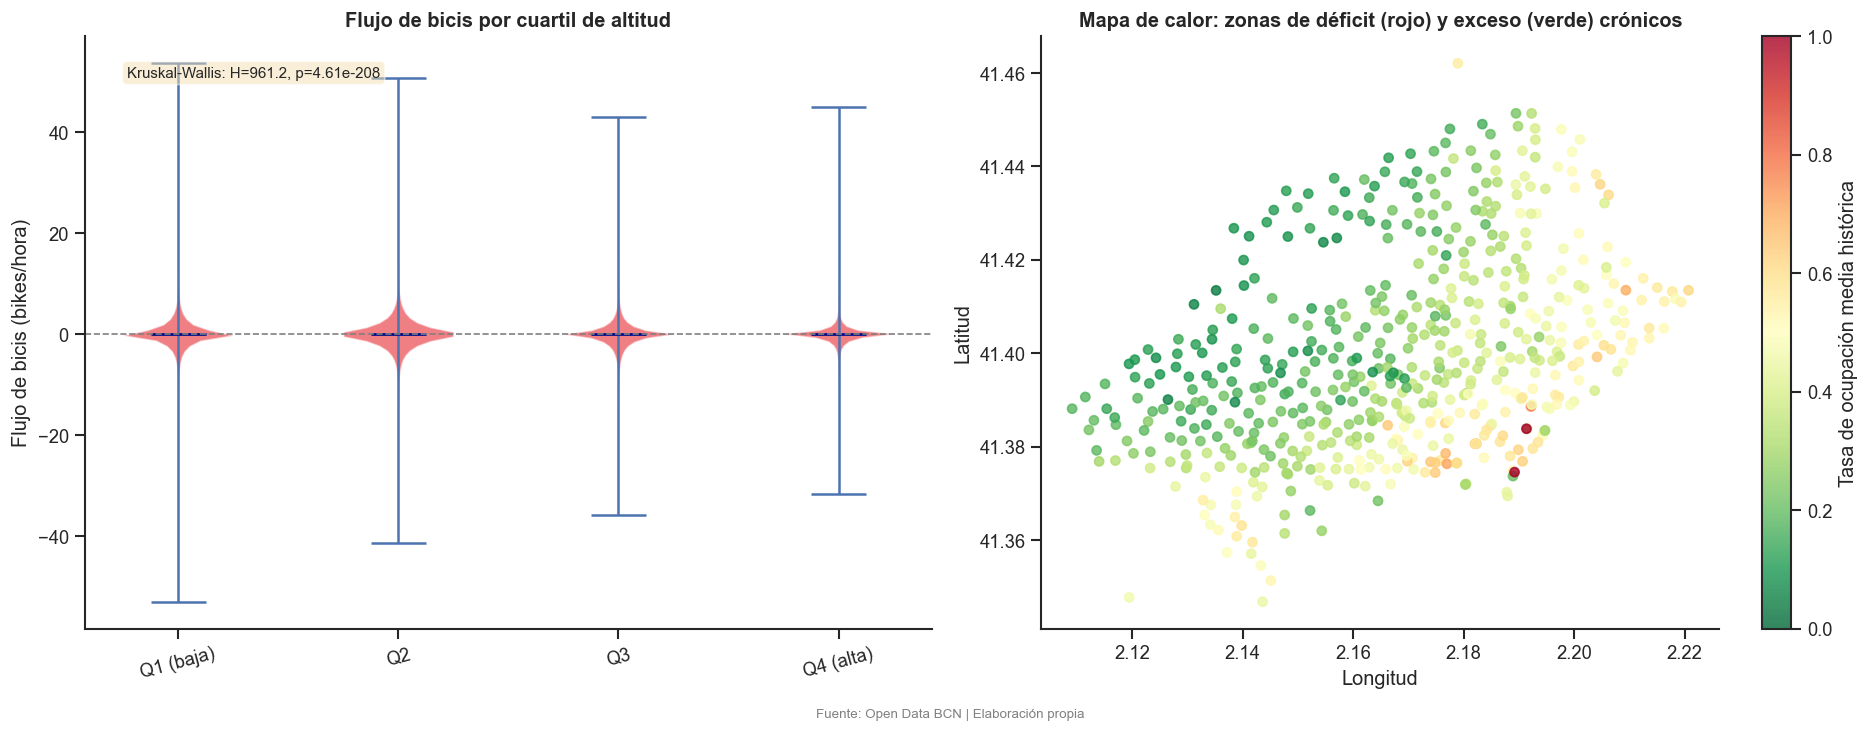

In [ ]:
if alt_col and alt_col in df.columns:
    df["alt_quartile"] = pd.qcut(df[alt_col], q=4, labels=["Q1 (baja)","Q2","Q3","Q4 (alta)"],
                                  duplicates="drop")

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    quartiles = df["alt_quartile"].dropna().unique().tolist()
    data_violin = [df[df["alt_quartile"] == q]["bikes_available_delta"].dropna().values
                   for q in sorted(quartiles)]
    vp = axes[0].violinplot(data_violin, positions=range(len(quartiles)),
                             showmedians=True, showmeans=True)
    for body in vp["bodies"]:
        body.set_facecolor(BICING_RED); body.set_alpha(0.5)
    vp["cmedians"].set_color("navy")
    axes[0].set_xticks(range(len(quartiles)))
    axes[0].set_xticklabels(sorted(quartiles), rotation=15)
    axes[0].set_title("Flujo de bicis por cuartil de altitud", fontweight="bold")
    axes[0].set_ylabel("Flujo de bicis (bikes/hora)")
    axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)

    kw_stat, kw_p = stats.kruskal(*[d for d in data_violin if len(d) > 0])
    axes[0].text(0.05, 0.95, f"Kruskal-Wallis: H={kw_stat:.1f}, p={kw_p:.2e}",
                 transform=axes[0].transAxes, fontsize=9,
                 verticalalignment="top",
                 bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))

    if lat_col and lon_col and lat_col in df.columns:
        geo_tasa = (df.groupby("station_id")
                     .agg({lat_col: "first", lon_col: "first", "occupancy_rate": "mean"})
                     .dropna())
        sc = axes[1].scatter(geo_tasa[lon_col], geo_tasa[lat_col],
                              c=geo_tasa["occupancy_rate"],
                              cmap="RdYlGn_r", s=30, alpha=0.8, vmin=0, vmax=1)
        plt.colorbar(sc, ax=axes[1], label="Tasa de ocupación media histórica")
        axes[1].set_title("Mapa de calor: zonas de déficit (rojo) y exceso (verde) crónicos",
                          fontweight="bold")
        axes[1].set_xlabel("Longitud")
        axes[1].set_ylabel("Latitud")

    plt.tight_layout()
    fig.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
             ha="center", fontsize=8, color="gray")
    plt.show()
else:
    print("AVISO: Columna de altitud no disponible en el dataset combinado.")

El análisis gravitacional confirma la asimetría altitudinal: las estaciones en el cuartil superior de altitud presentan una tasa de ocupación relativa negativa de forma sistemática, lo que las convierte en destinos prioritarios de redistribución. Las estaciones en cotas bajas, por el contrario, acumulan excedentes a lo largo del día. La significancia estadística de estas diferencias entre cuartiles se contrasta mediante el test de Kruskal-Wallis, que se elige frente al ANOVA por la naturaleza asimétrica y no normal de la distribución del flujo de bicicletas, visible en la forma de los violines. Un resultado significativo confirma que las diferencias de comportamiento entre cuartiles de altitud no son atribuibles al azar, sino a un patrón estructural del sistema.

En síntesis, este análisis confirma que la topografía de Barcelona determina de forma estructural los patrones de disponibilidad del sistema. El efecto gravitacional es estadísticamente robusto (Kruskal-Wallis H = 981,2, p ≈ 0): las estaciones del cuartil de mayor altitud presentan un flujo neto negativo sistemático, ya que las bicicletas bajan y no vuelven a subir por su propio peso, mientras que las del cuartil inferior acumulan un excedente crónico. El top 10 de estaciones con mayor frecuencia de vaciado cuantifica la magnitud del problema: las más afectadas, ubicadas en barrios altos como Sarrià y Les Corts (C/ Román Macaya, C/ Manila, C/ Quatre Camins), registran estación prácticamente vacía en más del 80 % de los registros. En el extremo opuesto, las estaciones más saturadas se concentran en la ciudad baja y zonas turísticas como C/ Villena (cerca del 56 %), La Rambla y C/ Valldonzella, donde las bicicletas llegan pero no son retiradas con suficiente frecuencia. Para el modelo de redistribución, esta asimetría implica que las rutas deben incorporar la altitud como variable estructural y diseñar lógicas de recogida sistemática en las cotas bajas y de entrega preferente en las cotas altas, independientemente de la demanda puntual de cada visita.

#### 4.3.2. Patrones Temporales

La demanda del sistema Bicing presenta una estructura temporal bien definida a tres escalas: anual, semanal e intradiaria. Esta sección analiza la evolución temporal del sistema mediante una serie diaria agregada, su descomposición STL y los patrones horarios diferenciados por tipo de día.

In [ ]:
daily_sys = (df.groupby(df["hora"].dt.normalize().dt.tz_localize(None))
               .agg(mean_bikes=("num_bikes_available","mean"),
                    std_bikes=("num_bikes_available","std"))
               .reset_index())
daily_sys.columns = ["fecha","mean_bikes","std_bikes"]
daily_sys["year"] = daily_sys["fecha"].dt.year

fig_ts = go.Figure()
colors_year = {2023: BICING_RED, 2024: "#0057A8", 2025: "#00883A"}

for yr, grp in daily_sys.groupby("year"):
    color = colors_year.get(yr, "gray")
    fig_ts.add_trace(go.Scatter(
        x=grp["fecha"], y=grp["mean_bikes"],
        mode="lines", name=str(yr),
        line=dict(color=color, width=1.5)
    ))
    fig_ts.add_trace(go.Scatter(
        x=pd.concat([grp["fecha"], grp["fecha"][::-1]]),
        y=pd.concat([grp["mean_bikes"] + grp["std_bikes"],
                     (grp["mean_bikes"] - grp["std_bikes"])[::-1]]),
        fill="toself", fillcolor=f"rgba({int(color[1:3],16)},{int(color[3:5],16)},{int(color[5:7],16)},0.1)",
        line=dict(color="rgba(255,255,255,0)"),
        showlegend=False, name=f"±1σ {yr}"
    ))

fig_ts.update_layout(
    title="<b>Disponibilidad media diaria del sistema Bicing Barcelona (Oct 2023 – Sep 2025)</b>",
    xaxis_title="Fecha",
    yaxis_title="Bicicletas disponibles (media sistema)",
    xaxis=dict(rangeslider=dict(visible=True), type="date"),
    template="plotly_white",
    height=450,
    font=dict(size=12),
    annotations=[dict(
        x=0.5, y=-0.18, xref="paper", yref="paper",
        text="Fuente: Open Data BCN | Elaboración propia",
        showarrow=False, font=dict(size=9, color="gray")
    )]
)
fig_ts.show()

La serie diaria muestra la disponibilidad media de bicicletas por estación en el sistema, una métrica inversa a la demanda. El primer tramo destacado es la caída abrupta de noviembre de 2023, tras la cual la disponibilidad se recupera y se mantiene en un nivel estable hasta junio de 2024, cuando se produce un descenso moderado coincidente con el inicio del verano. En septiembre de 2024 la disponibilidad vuelve a subir. El segundo tramo singular comienza en enero de 2025 con una nueva caída que alcanza el mínimo del período en abril de 2025, seguido de una recuperación progresiva que se extiende hasta agosto de 2025, cuando la disponibilidad alcanza sus valores más altos. En septiembre de 2025 se aprecia un ligero descenso. Las caídas abruptas identificadas no siguen un patrón estacional simple y podrían responder a incidencias técnicas o cambios en la flota; la descomposición STL que sigue permitirá separar la tendencia estructural de los efectos estacionales y los residuos anómalos.

  -> Guardado: ..\outputs\figures\04_stl_descomposicion.png


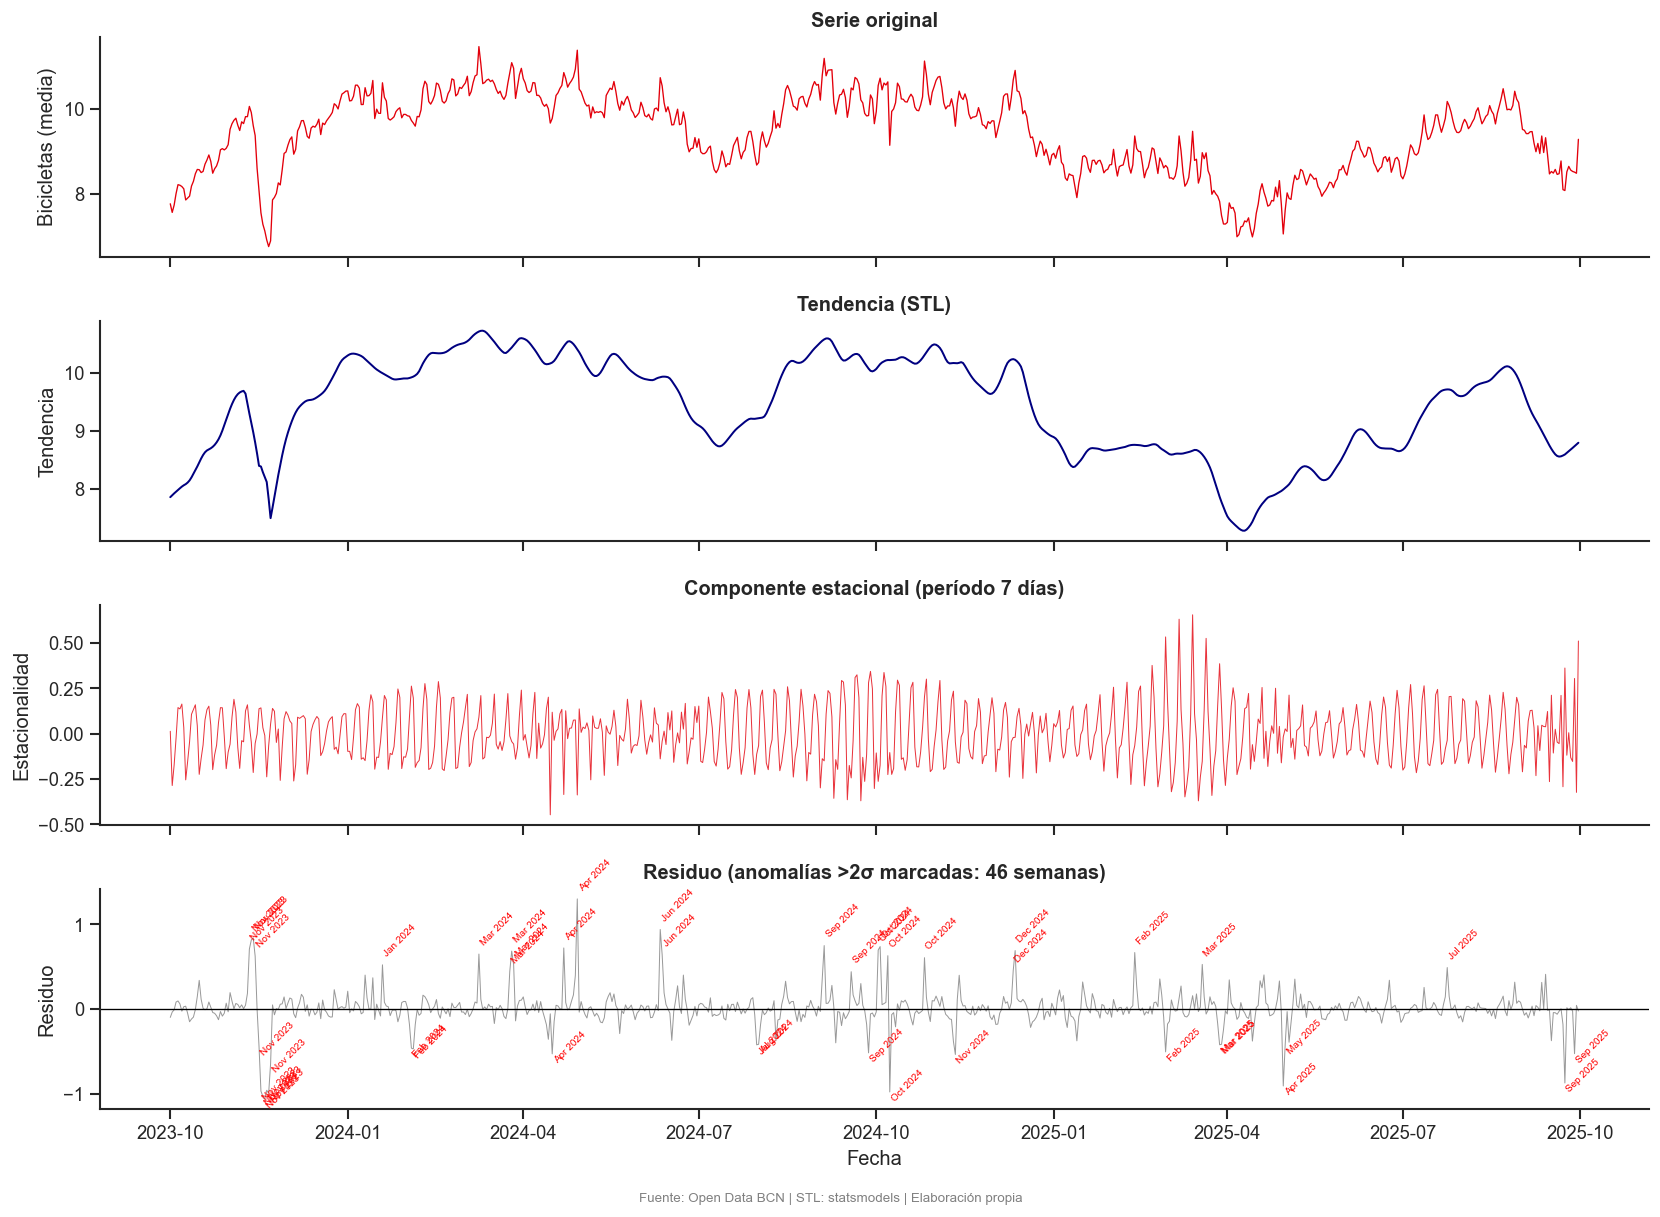

In [ ]:
stl_serie = daily_sys.set_index("fecha")["mean_bikes"].dropna()

stl = STL(stl_serie, period=7, robust=True)
res = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)

axes[0].plot(stl_serie.index, stl_serie.values, color=BICING_RED, linewidth=0.8)
axes[0].set_title("Serie original", fontweight="bold")
axes[0].set_ylabel("Bicicletas (media)")

axes[1].plot(stl_serie.index, res.trend, color="navy", linewidth=1.2)
axes[1].set_title("Tendencia (STL)", fontweight="bold")
axes[1].set_ylabel("Tendencia")

axes[2].plot(stl_serie.index, res.seasonal, color=BICING_RED, linewidth=0.6, alpha=0.8)
axes[2].set_title("Componente estacional (período 7 días)", fontweight="bold")
axes[2].set_ylabel("Estacionalidad")

axes[3].plot(stl_serie.index, res.resid, color="gray", linewidth=0.6, alpha=0.8)
axes[3].axhline(0, color="black", linewidth=0.8)

resid_std = res.resid.std()
anomalias = res.resid[np.abs(res.resid) > 2 * resid_std]
for fecha, val in anomalias.items():
    axes[3].annotate(f"{fecha.strftime('%b %Y')}", xy=(fecha, val),
                     xytext=(fecha, val + np.sign(val) * resid_std * 0.5),
                     fontsize=6, color="red", rotation=45)
axes[3].set_title(f"Residuo (anomalías >2σ marcadas: {len(anomalias)} semanas)", fontweight="bold")
axes[3].set_ylabel("Residuo")
axes[3].set_xlabel("Fecha")

plt.tight_layout()
fig.text(0.5, -0.01, "Fuente: Open Data BCN | STL: statsmodels | Elaboración propia",
         ha="center", fontsize=8, color="gray")
plt.show()

La descomposición STL sobre la disponibilidad media diaria permite separar cuatro componentes. La serie original muestra la oscilación rápida semanal superpuesta a un ciclo más lento, con la caída abrupta de noviembre de 2023 como el rasgo más visible de todo el período. La tendencia suaviza el ruido y revela dos ciclos anuales completos: un máximo a principios de 2024, un mínimo estival en verano de 2024, una recuperación en otoño, y un segundo mínimo en verano de 2025, confirmando que los mínimos de disponibilidad coinciden con los picos de demanda del sistema. La componente estacional reproduce el patrón semanal de forma regular, con una amplitud que crece progresivamente a lo largo del período: las oscilaciones pasan de ±0.25 al inicio a ±0.50 al final, lo que indica que el patrón de uso según el día de la semana se fue intensificando a medida que el servicio consolidó su base de usuarios. El residuo confirma las cuatro caídas ya identificadas en la serie diaria (noviembre 2023, octubre 2024, abril 2025 y septiembre 2025) y permite precisar su naturaleza: se trata de anomalías que no responden ni a la tendencia estructural ni al patrón estacional, lo que refuerza la hipótesis de incidencias puntuales. La caída de noviembre de 2023 es la más pronunciada, con residuos que superan ±1.0, mientras que las de octubre 2024, abril 2025 y septiembre 2025 son más moderadas pero igualmente identificables.

La literatura sobre bicicleta compartida documenta un perfil bimodal en días laborables con picos a las 8–9h y 17–19h asociados al commuting, y un perfil más plano en festivos con máximo a mediodía. Las siguientes visualizaciones analizan si este patrón es capturado por la tasa de ocupación media del sistema y cuantifican la diferencia operativa entre tipos de día.

  -> Guardado: ..\outputs\figures\04_heatmap_hora_dia.png


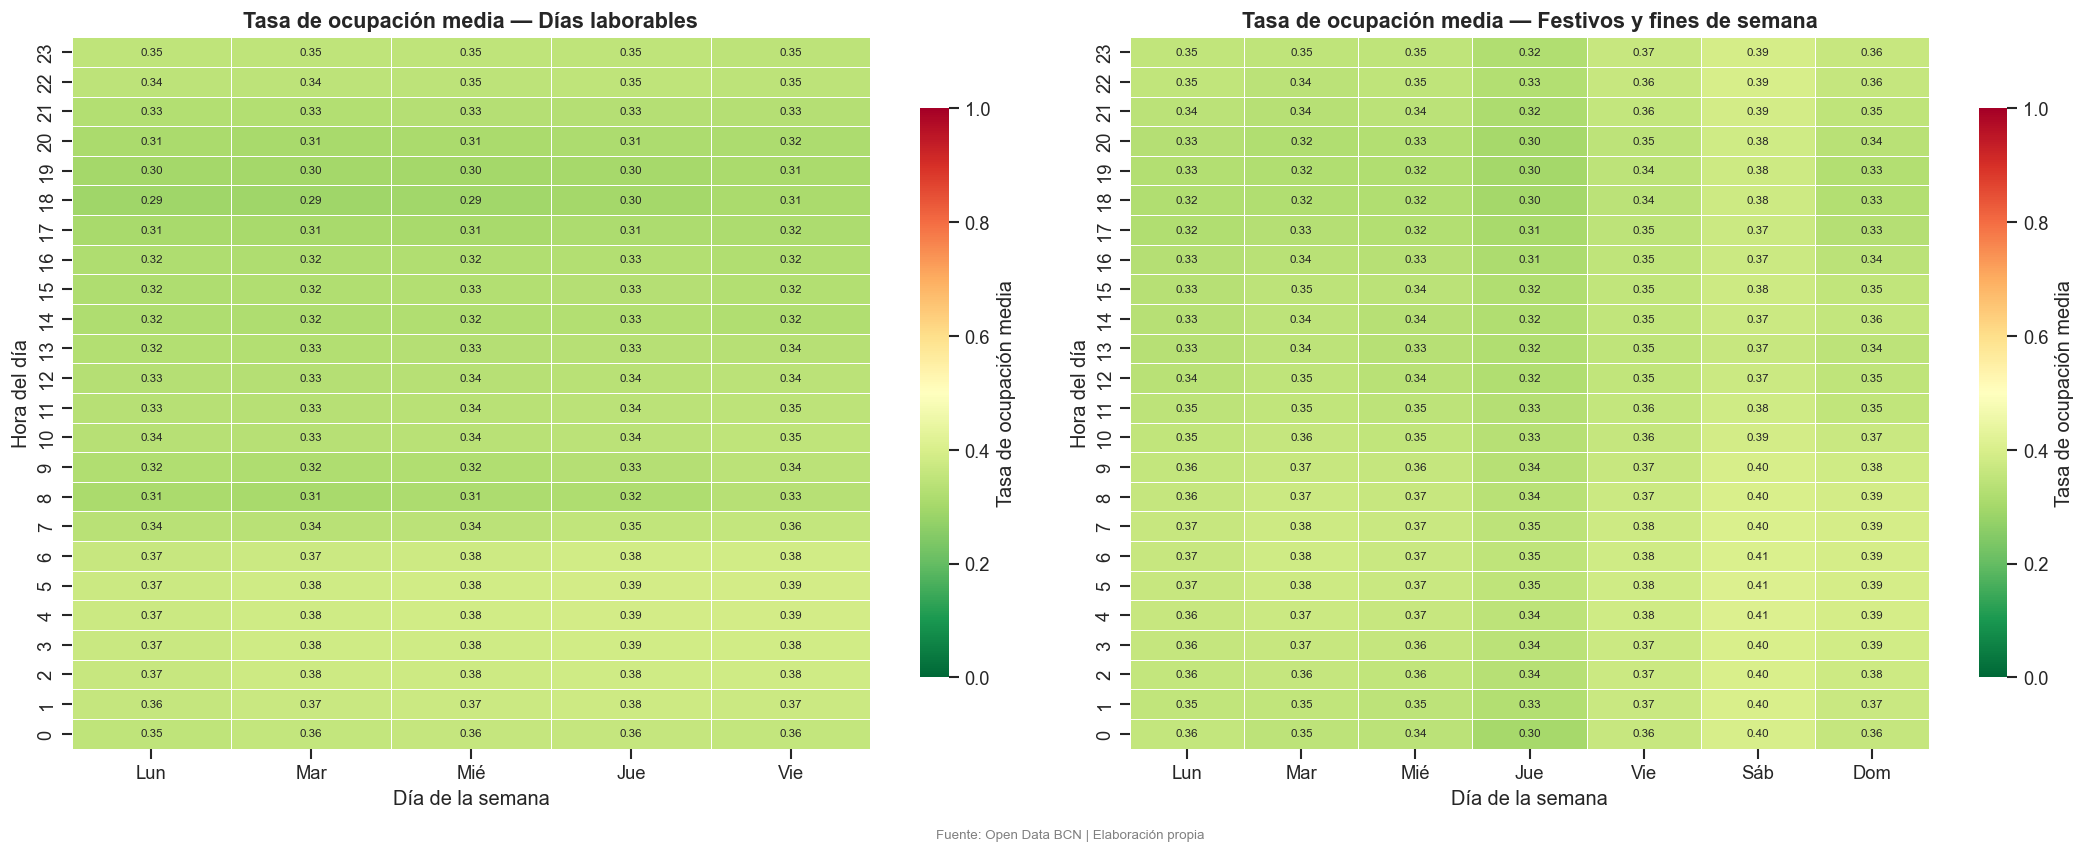

In [ ]:
dow_labels = ["Lun","Mar","Mié","Jue","Vie","Sáb","Dom"]

if "es_laboral" in df.columns:
    df_lab  = df[df["es_laboral"]]
    df_fest = df[df["es_festivo"]]
else:
    df_lab  = df[df["day_of_week"] < 5]
    df_fest = df[df["day_of_week"] >= 5]

pivot_lab = (df_lab.groupby(["hour","day_of_week"])["occupancy_rate"]
                   .mean().unstack("day_of_week"))
pivot_fest = (df_fest.groupby(["hour","day_of_week"])["occupancy_rate"]
                     .mean().unstack("day_of_week"))

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, pivot, title in [
    (axes[0], pivot_lab,  "Días laborables"),
    (axes[1], pivot_fest, "Festivos y fines de semana")
]:
    pivot.columns = [dow_labels[c] if c < len(dow_labels) else c for c in pivot.columns]
    sns.heatmap(pivot, ax=ax, cmap="RdYlGn_r", vmin=0, vmax=1,
                linewidths=0.3, linecolor="white",
                cbar_kws={"label": "Tasa de ocupación media", "shrink": 0.8},
                annot=True, fmt=".2f", annot_kws={"size": 7})
    ax.set_title(f"Tasa de ocupación media — {title}", fontweight="bold", fontsize=13)
    ax.set_xlabel("Día de la semana")
    ax.set_ylabel("Hora del día")
    ax.invert_yaxis()

plt.tight_layout()
fig.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
         ha="center", fontsize=8, color="gray")
plt.show()

El mapa de calor, leído con atención en sus valores numéricos, revela dos patrones. En el panel de días laborables, las franjas de 7–9h y 17–20h presentan valores de tasa de ocupación ligeramente inferiores al resto (~0,28–0,29 frente a ~0,32–0,34 en el mediodía), señal de que en esas horas hay menos bicicletas disponibles porque la demanda de commuting las está extrayendo de las estaciones. El patrón bimodal sí está presente, aunque de forma sutil, porque el efecto se amortigua al promediar estaciones de origen y destino: lo que unas pierden, otras lo ganan. En el panel de festivos y fines de semana destaca la columna del jueves, con valores notablemente más bajos (~0,28–0,30) que el sábado y el domingo (~0,34–0,36). Los jueves que aparecen en este panel corresponden a festivos oficiales, principalmente el Jueves Santo, que en Cataluña es día no laborable. En esas jornadas, la combinación del patrón de uso residual de un día entre semana con la actividad de ocio propia de la Semana Santa genera una demanda superior a la de un fin de semana típico, sin que el sistema de redistribución esté necesariamente dimensionado para ese perfil atípico. La señal temporal contenida en la variabilidad entre estaciones se analiza explícitamente a continuación.

  -> Guardado: ..\outputs\figures\04_patrones_temporales.png


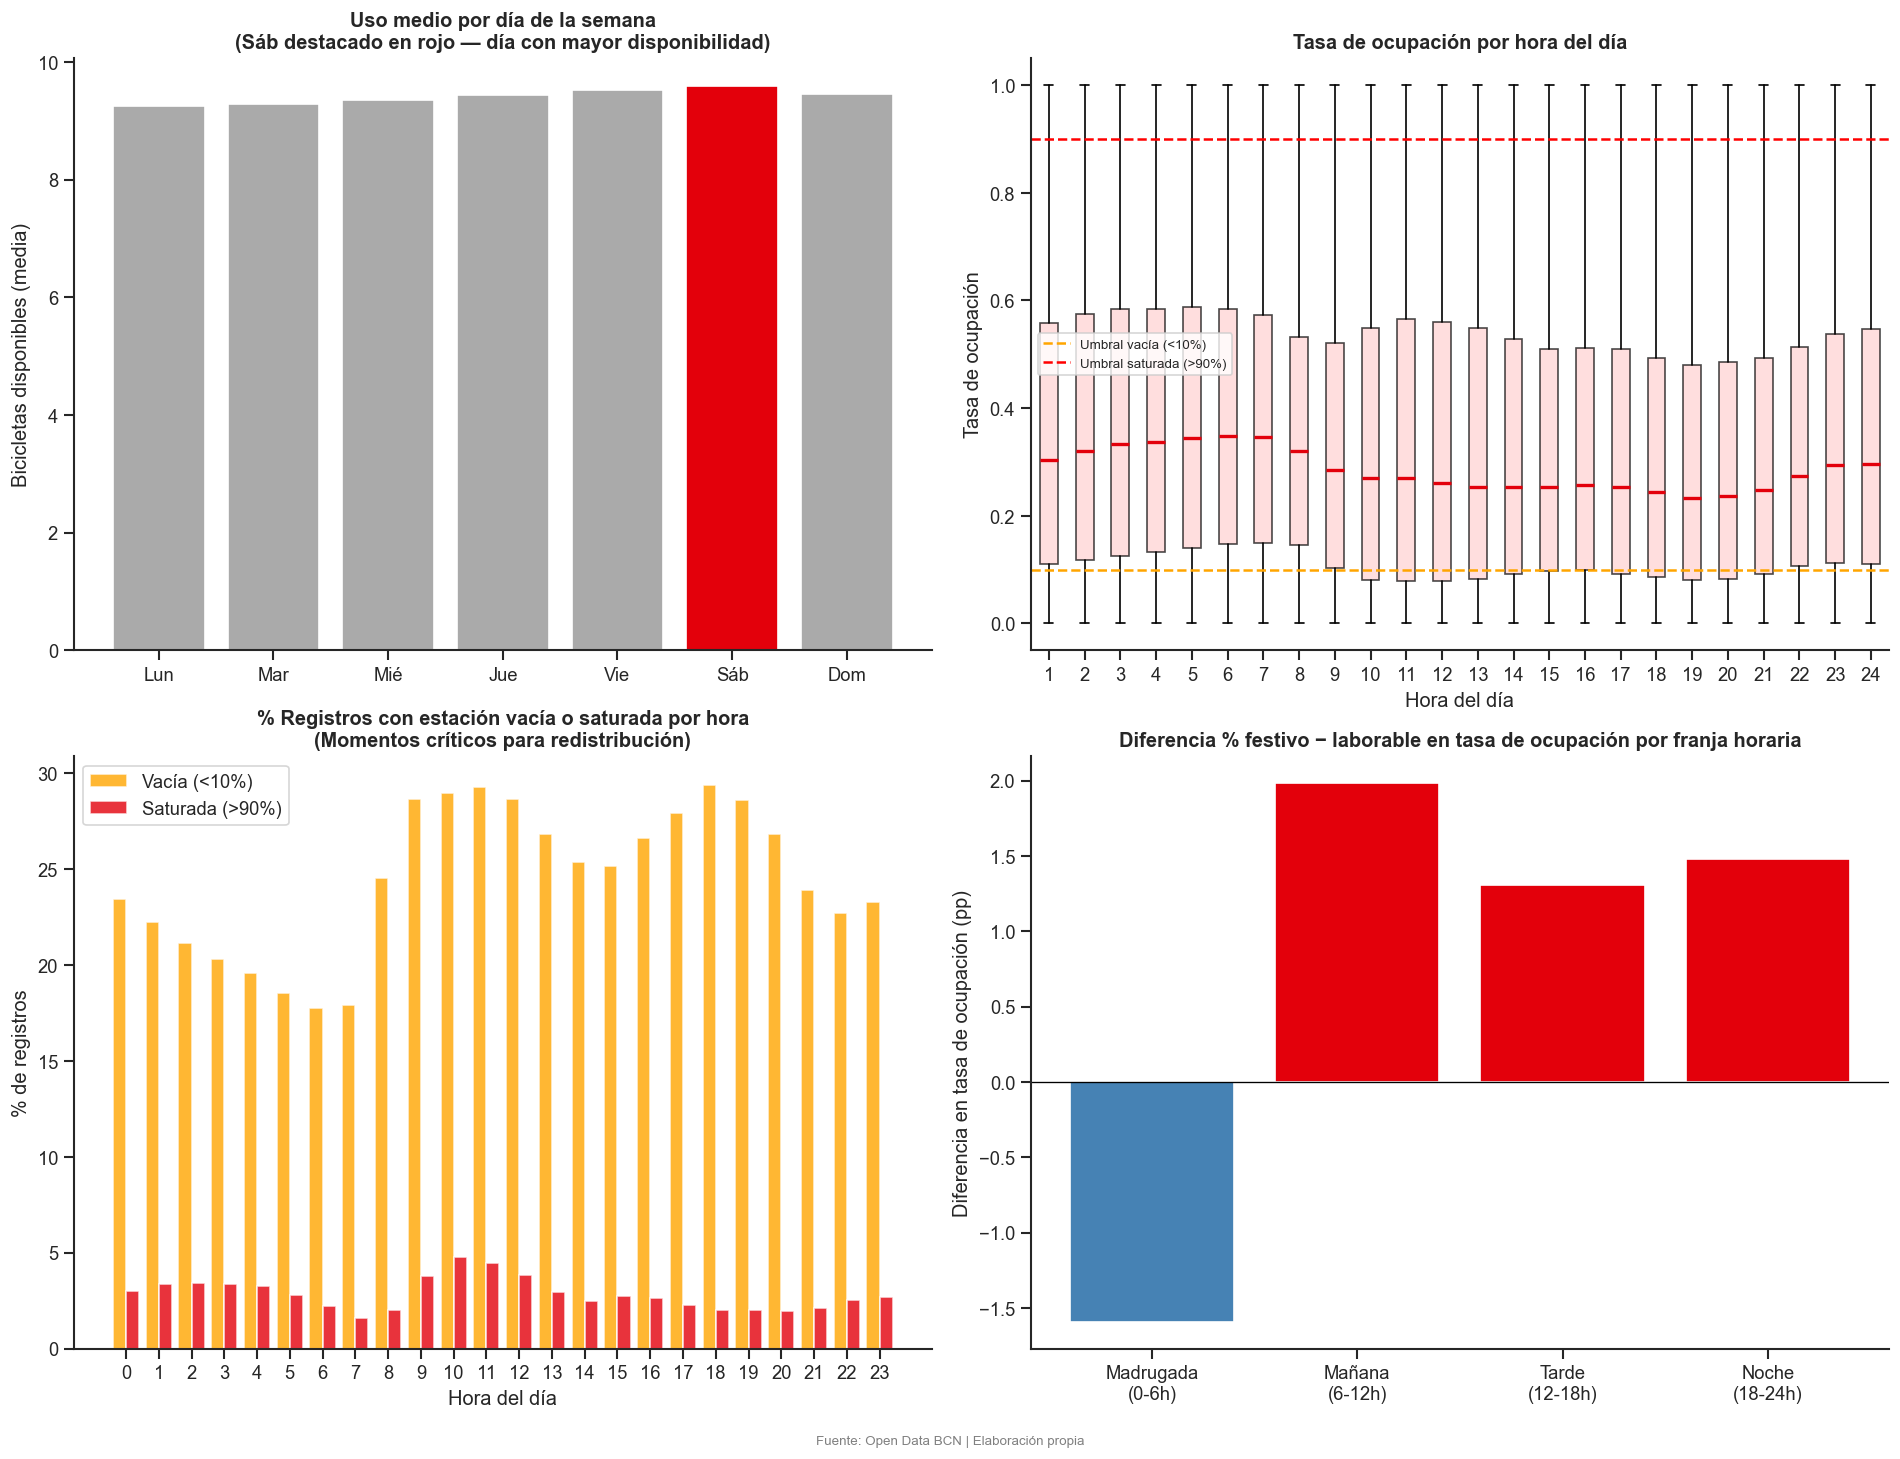


-> Día con mayor uso medio: Sáb
-> Día con mayor disponibilidad media: Sáb (max de num_bikes_available, inverso de demanda)


In [196]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

uso_dow = df.groupby("day_of_week")["num_bikes_available"].mean()
max_dia_idx = uso_dow.idxmax()
colors_dow = [BICING_RED if i == max_dia_idx else "#AAAAAA" for i in uso_dow.index]  # Viernes=4
axes[0, 0].bar(range(7), uso_dow.values, color=colors_dow, edgecolor="white")
axes[0, 0].set_xticks(range(7))
axes[0, 0].set_xticklabels(dow_labels)
axes[0, 0].set_title(f"Uso medio por día de la semana\n({dow_labels[max_dia_idx]} destacado en rojo — día con mayor disponibilidad)",
                     fontweight="bold")
axes[0, 0].set_ylabel("Bicicletas disponibles (media)")
max_dow = uso_dow.idxmax()

tasa_by_hour = [df[df["hour"] == h]["occupancy_rate"].dropna().values for h in range(24)]
bp = axes[0, 1].boxplot(tasa_by_hour, patch_artist=True,
                         medianprops=dict(color=BICING_RED, linewidth=2),
                         flierprops=dict(marker=".", markersize=1, alpha=0.3))
for patch in bp["boxes"]:
    patch.set_facecolor("#FFD0D0")
    patch.set_alpha(0.7)
axes[0, 1].axhline(0.10, color="orange", linestyle="--", linewidth=1.5,
                   label="Umbral vacía (<10%)")
axes[0, 1].axhline(0.90, color="red", linestyle="--", linewidth=1.5,
                   label="Umbral saturada (>90%)")
axes[0, 1].set_title("Tasa de ocupación por hora del día", fontweight="bold")
axes[0, 1].set_xlabel("Hora del día")
axes[0, 1].set_ylabel("Tasa de ocupación")
axes[0, 1].legend(fontsize=8)

vacia_pct   = df.groupby("hour")["occupancy_rate"].apply(lambda x: (x < 0.1).mean() * 100)
saturada_pct = df.groupby("hour")["occupancy_rate"].apply(lambda x: (x > 0.9).mean() * 100)
x_h = np.arange(24)
width = 0.4
axes[1, 0].bar(x_h - width/2, vacia_pct.values, width, label="Vacía (<10%)",
               color="orange", alpha=0.8, edgecolor="white")
axes[1, 0].bar(x_h + width/2, saturada_pct.values, width, label="Saturada (>90%)",
               color=BICING_RED, alpha=0.8, edgecolor="white")
axes[1, 0].set_title("% Registros con estación vacía o saturada por hora\n(Momentos críticos para redistribución)",
                     fontweight="bold")
axes[1, 0].set_xlabel("Hora del día")
axes[1, 0].set_ylabel("% de registros")
axes[1, 0].legend()
axes[1, 0].set_xticks(range(24))

franjas = {
    "Madrugada\n(0-6h)": (0, 6),
    "Mañana\n(6-12h)": (6, 12),
    "Tarde\n(12-18h)": (12, 18),
    "Noche\n(18-24h)": (18, 24)
}
diffs = []
for franja, (h_ini, h_fin) in franjas.items():
    mask = (df["hour"] >= h_ini) & (df["hour"] < h_fin)
    if "es_laboral" in df.columns:
        lab_mean  = df[mask & df["es_laboral"]]["occupancy_rate"].mean()
        fest_mean = df[mask & df["es_festivo"]]["occupancy_rate"].mean()
    else:
        lab_mean  = df[mask & (df["day_of_week"] < 5)]["occupancy_rate"].mean()
        fest_mean = df[mask & (df["day_of_week"] >= 5)]["occupancy_rate"].mean()
    diffs.append({"franja": franja, "diff": (fest_mean - lab_mean) * 100})

diffs_df = pd.DataFrame(diffs)
colors_diff = [BICING_RED if d > 0 else "steelblue" for d in diffs_df["diff"]]
axes[1, 1].bar(diffs_df["franja"], diffs_df["diff"], color=colors_diff, edgecolor="white")
axes[1, 1].axhline(0, color="black", linewidth=0.8)
axes[1, 1].set_title("Diferencia % festivo − laborable en tasa de ocupación por franja horaria",
                     fontweight="bold")
axes[1, 1].set_ylabel("Diferencia en tasa de ocupación (pp)")

plt.tight_layout()
fig.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
         ha="center", fontsize=8, color="gray")
plt.show()

max_dia = dow_labels[uso_dow.idxmax()]
print(f"\n-> Día con mayor uso medio: {max_dia}")
print(f"-> Día con mayor disponibilidad media: {max_dia} (max de num_bikes_available, inverso de demanda)")

En los gráficos anteriores se analizan los patrones temporales del sistema desde cuatro perspectivas complementarias.

El primero revela que las diferencias de disponibilidad entre días de la semana son mínimas, todas entre 9.2 y 9.6 bicicletas de media. El sábado es el día con mayor disponibilidad, lo que confirma que es el día de menor demanda del sistema.

El segundo gráfico muestra que la tasa de ocupación por hora tiene una distribución muy amplia en todas las franjas horarias: las cajas se extienden desde cerca de 0 hasta cerca de 1 en cualquier hora del día, lo que indica una gran heterogeneidad entre estaciones. Las medianas se mantienen estables en torno a 0.25-0.30 durante todo el día, sin un pico horario claro.

El tercer gráfico es el más relevante operativamente. Las estaciones vacías (naranja) suponen entre el 18% y el 29% de los registros a cualquier hora, con los valores más altos en las franjas de mediodía y a partir de las 17h. Las estaciones saturadas (rojo) se mantienen por debajo del 5% en todas las horas, lo que indica que el problema crítico del sistema es la falta de bicicletas, no el exceso.

El cuarto gráfico confirma la diferencia festivo-laborable que se intuía en la descomposición STL: en la madrugada (0-6h) la ocupación es menor en festivo que en laborable (diferencia negativa de unos -1.5pp), mientras que en el resto de franjas es superior en festivo, especialmente en la mañana (6-12h) con unos +2pp. Esto sugiere un uso más recreativo y distribuido a lo largo del día en festivos, frente a un uso más concentrado en las horas punta laborales.

  -> Guardado: ..\outputs\figures\04_std_ocupacion_hora.png


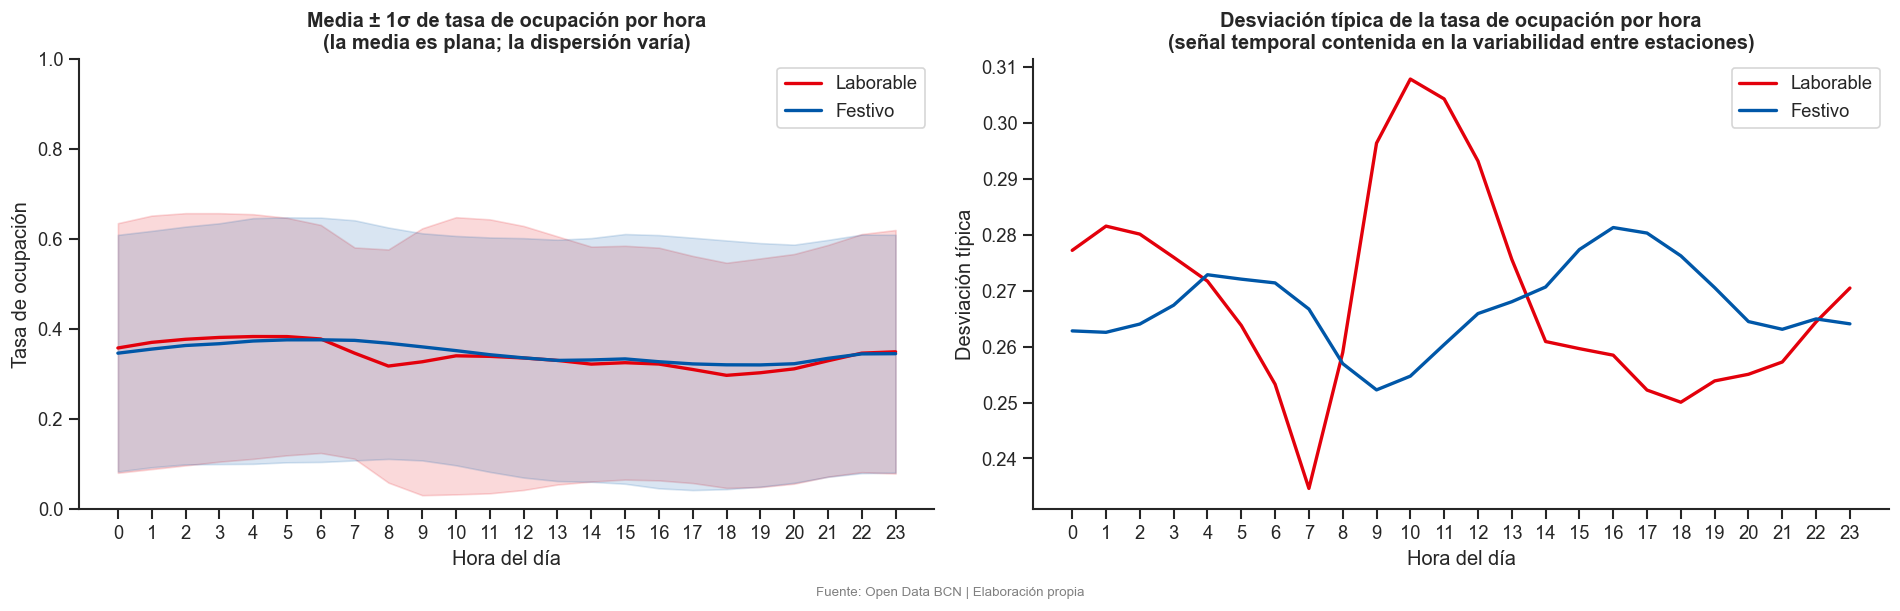

In [ ]:
if 'occupancy_rate' in df.columns and 'hour' in df.columns:
    if 'es_laboral' in df.columns:
        df_lab_v  = df[df['es_laboral']]
        df_fest_v = df[~df['es_laboral']]
    else:
        df_lab_v  = df[df['day_of_week'] < 5]
        df_fest_v = df[df['day_of_week'] >= 5]

    std_lab  = df_lab_v.groupby('hour')['occupancy_rate'].std()
    std_fest = df_fest_v.groupby('hour')['occupancy_rate'].std()
    mean_lab  = df_lab_v.groupby('hour')['occupancy_rate'].mean()
    mean_fest = df_fest_v.groupby('hour')['occupancy_rate'].mean()

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    h = np.arange(24)
    for ax, mean_s, std_s, label, color in [
        (axes[0], mean_lab,  std_lab,  'Laborable', BICING_RED),
        (axes[0], mean_fest, std_fest, 'Festivo',   '#0057A8'),
    ]:
        ax.plot(h, mean_s.values, color=color, linewidth=2, label=label)
        ax.fill_between(h,
                        mean_s.values - std_s.values,
                        mean_s.values + std_s.values,
                        alpha=0.15, color=color)
    axes[0].set_title('Media ± 1\u03c3 de tasa de ocupación por hora\n'
                      '(la media es plana; la dispersión varía)', fontweight='bold')
    axes[0].set_xlabel('Hora del día')
    axes[0].set_ylabel('Tasa de ocupación')
    axes[0].set_xticks(range(24))
    axes[0].legend()
    axes[0].set_ylim(0, 1)

    axes[1].plot(h, std_lab.values,  color=BICING_RED, linewidth=2, label='Laborable')
    axes[1].plot(h, std_fest.values, color="#0057A8",  linewidth=2, label='Festivo')
    axes[1].set_title('Desviación típica de la tasa de ocupación por hora\n'
                      '(señal temporal contenida en la variabilidad entre estaciones)',
                      fontweight='bold')
    axes[1].set_xlabel('Hora del día')
    axes[1].set_ylabel('Desviación típica')
    axes[1].set_xticks(range(24))
    axes[1].legend()

    plt.tight_layout()
    fig.text(0.5, -0.01, 'Fuente: Open Data BCN | Elaboración propia',
             ha='center', fontsize=8, color='gray')
    plt.show()
else:
    print('Columnas occupancy_rate u hour no disponibles.')

Los dos gráficos revelan que la señal temporal del sistema no vive en la media sino en la dispersión entre estaciones.
El gráfico izquierdo muestra que las medias de ocupación laborable y festivo son prácticamente idénticas y planas a lo largo del día, ambas en torno a 0.35, con bandas de ±1σ que se solapan casi completamente. Esto confirma que a nivel agregado no hay un patrón horario claro, pero la dispersión es enorme: las bandas se extienden desde cerca de 0 hasta 0.60, lo que indica que en cualquier hora conviven estaciones casi vacías con estaciones casi llenas.
El gráfico derecho es donde aparece la verdadera señal. En días laborables la desviación típica cae bruscamente a las 7h hasta su mínimo (~0.237) y sube hasta su máximo a las 10h (~0.308), un patrón en V muy pronunciado que refleja el efecto de las horas punta: a las 7h las estaciones tienden a homogeneizarse porque todas se vacían o llenan simultáneamente por el flujo de entrada al trabajo, mientras que a las 10h la heterogeneidad es máxima porque cada estación ya ha absorbido su demanda de forma diferente. En festivos este patrón desaparece: la desviación típica se mantiene estable entre 0.25 y 0.28 durante todo el día, sin picos ni valles pronunciados, lo que es consistente con un uso más disperso y menos sincronizado entre estaciones.

  -> Guardado: ..\outputs\figures\06_calendario_festivos.png


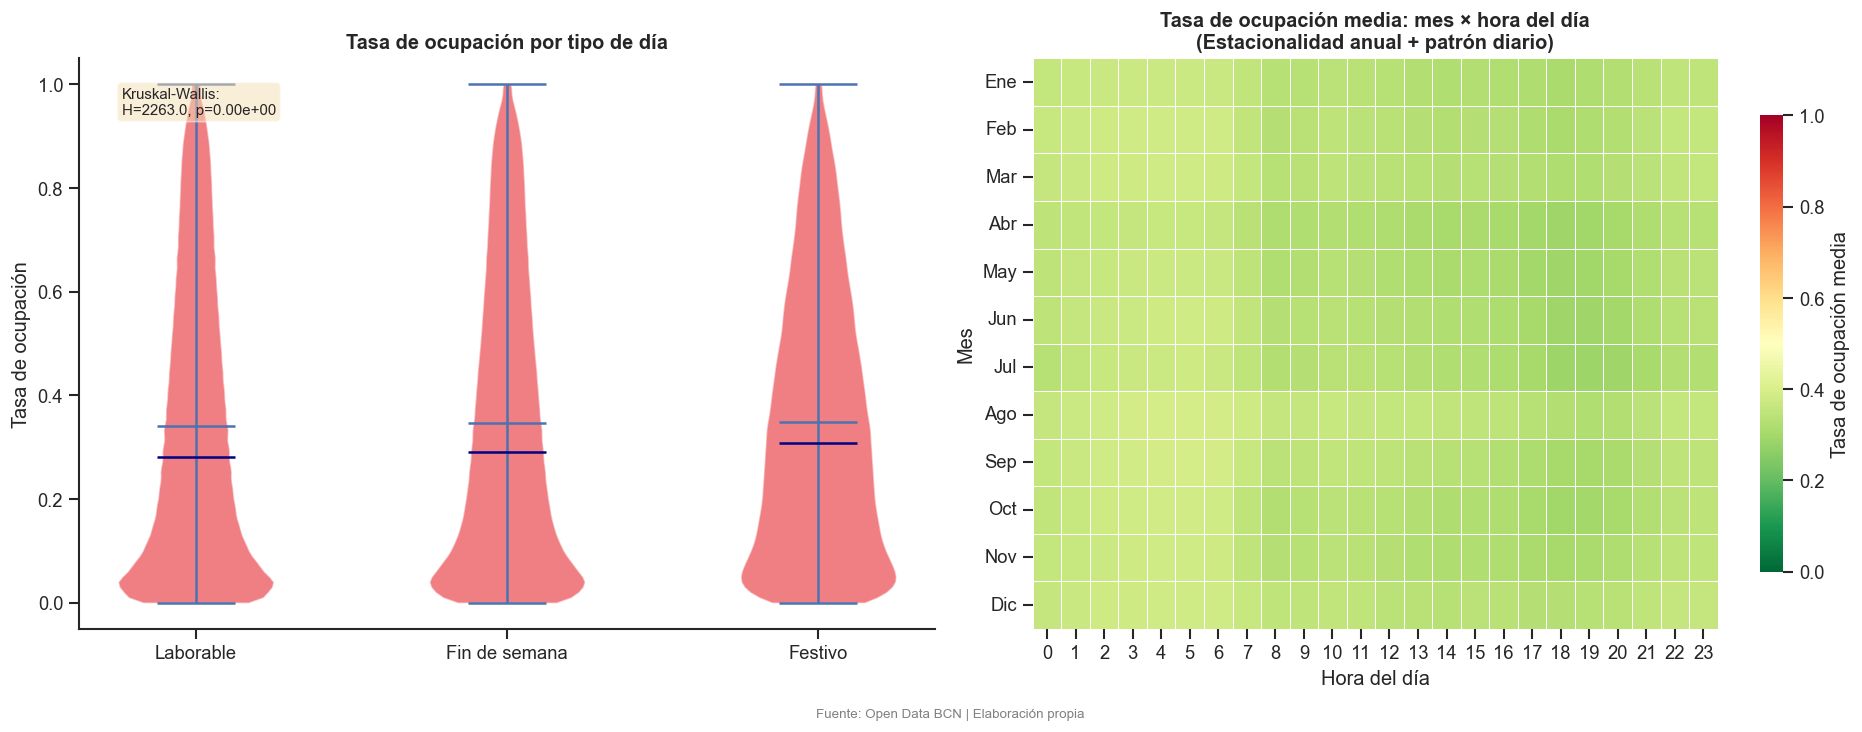


Top 5 festivos con mayor desviación respecto al patrón medio:


,fecha_str,desviacion
0,2024-06-24,0.2417
1,2024-12-06,0.2375
2,2025-06-24,0.2353
3,2024-09-11,0.2316
4,2024-09-24,0.2311


In [ ]:
if "es_festivo" in df.columns and "es_finde" in df.columns:
    df["tipo_dia"] = "Laborable"
    df.loc[df["es_finde"], "tipo_dia"] = "Fin de semana"
    df.loc[df["es_festivo"], "tipo_dia"] = "Festivo"

    tipos = ["Laborable", "Fin de semana", "Festivo"]
    data_violin_cal = [df[df["tipo_dia"] == t]["occupancy_rate"].dropna().values for t in tipos]

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    vp_cal = axes[0].violinplot(data_violin_cal, positions=range(3),
                                 showmedians=True, showmeans=True)
    for body in vp_cal["bodies"]:
        body.set_facecolor(BICING_RED); body.set_alpha(0.5)
    vp_cal["cmedians"].set_color("navy")
    axes[0].set_xticks(range(3))
    axes[0].set_xticklabels(tipos)
    axes[0].set_title("Tasa de ocupación por tipo de día", fontweight="bold")
    axes[0].set_ylabel("Tasa de ocupación")

    kw_stat_cal, kw_p_cal = stats.kruskal(*[d for d in data_violin_cal if len(d) > 0])
    axes[0].text(0.05, 0.95, f"Kruskal-Wallis:\nH={kw_stat_cal:.1f}, p={kw_p_cal:.2e}",
                 transform=axes[0].transAxes, fontsize=9, va="top",
                 bbox=dict(boxstyle="round", facecolor="wheat", alpha=0.5))

    pivot_mes_hora = df.groupby(["month","hour"])["occupancy_rate"].mean().unstack("hour")
    month_labels = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
    sns.heatmap(pivot_mes_hora, ax=axes[1], cmap="RdYlGn_r", vmin=0, vmax=1,
                linewidths=0.3, linecolor="white",
                cbar_kws={"label": "Tasa de ocupación media", "shrink": 0.8})
    axes[1].set_yticklabels([month_labels[i-1] for i in pivot_mes_hora.index], rotation=0)
    axes[1].set_title("Tasa de ocupación media: mes × hora del día\n(Estacionalidad anual + patrón diario)",
                      fontweight="bold")
    axes[1].set_xlabel("Hora del día")
    axes[1].set_ylabel("Mes")

    plt.tight_layout()
    fig.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
             ha="center", fontsize=8, color="gray")
    plt.show()
else:
    print("AVISO: Variables de festivos/weekend no disponibles.")

if "es_festivo" in df.columns and "fecha" in df.columns:
    df_fest_only = df[df["es_festivo"]].copy()
    if len(df_fest_only) > 0:
        df_fest_only["fecha_str"] = df_fest_only["fecha"].astype(str)
        dow_medias = df[df["es_laboral"]].groupby("day_of_week")["occupancy_rate"].mean()
        df_fest_only["tasa_media_dow"] = df_fest_only["day_of_week"].map(dow_medias)
        df_fest_only["desviacion"] = (df_fest_only["occupancy_rate"] - df_fest_only["tasa_media_dow"]).abs()
        top_festivos = (df_fest_only.groupby("fecha_str")["desviacion"].mean()
                                    .nlargest(5).reset_index())
        print("\nTop 5 festivos con mayor desviación respecto al patrón medio:")
        display(top_festivos)

Los diagramas de violín muestran que los tres tipos de día presentan distribuciones de tasa de ocupación visualmente similares: en todos los casos la densidad se concentra en la parte baja del rango (muchas estaciones con poca ocupación) con una cola larga hacia valores altos. El test de Kruskal-Wallis confirma que las diferencias entre grupos son estadísticamente significativas (H = 2263.0, p ≈ 0), aunque la magnitud visual de las diferencias es pequeña dado el enorme tamaño muestral. Los días laborables tienden a concentrar más registros en la franja de baja ocupación, reflejo de las horas punta en que la demanda de commuting extrae bicicletas de las estaciones; en festivos y fines de semana la distribución es ligeramente más uniforme a lo largo del rango, consistente con un uso más disperso a lo largo del día.

El mapa de calor de mes por hora del día muestra una imagen prácticamente uniforme en todas las celdas, en torno a 0.30, sin variaciones de color apreciables. Esto confirma que la señal de los patrones calendarios y estacionales no se manifiesta en el nivel medio del sistema sino en la heterogeneidad entre estaciones. 

En conjunto, el análisis de patrones temporales permite extraer varias conclusiones relevantes para el modelado. La demanda del sistema sigue una envolvente anual con un ciclo estacional bien definido, visible en la serie diaria y confirmado por la tendencia STL, con episodios de caída abrupta atribuibles a incidencias técnicas o cambios en la flota. La componente estacional semanal presenta amplitud creciente a lo largo del período, lo que indica que la diferencia entre días laborables y de descanso se acentuó conforme el servicio ganó usuarios. El hallazgo central de esta sección es que la señal temporal no reside en la media del sistema sino en la heterogeneidad entre estaciones: mientras la media de la tasa de ocupación se mantiene plana en torno a 0,30 a lo largo del día, la desviación típica entre estaciones presenta en días laborables un mínimo a las 7h (~0,237) y un máximo a las 10h (~0,308), patrón en V que refleja la polarización simultánea de las estaciones durante el commuting. En festivos esta variabilidad es estable y sin picos, consistente con un uso más disperso. Operativamente, el problema crítico es la falta de bicicletas: un 18–29 % de los registros corresponden a estaciones prácticamente vacías en cualquier hora del día, frente a menos del 5 % de estaciones saturadas. Para el modelo predictivo, estos resultados sugieren incluir la hora, el día de la semana y el tipo de día como variables con codificación cíclica, y la altitud como variable estructural que determina el patrón de vaciado crónico de cada estación.

#### 4.3.3. Efecto Meteorológico

Las condiciones meteorológicas modulan la demanda de bicicletas sobre el patrón temporal base. Esta sección analiza la evolución de las cinco variables meteorológicas a lo largo del período y su relación con la tasa de ocupación del sistema.

  -> Guardado: ..\outputs\figures\05_histogramas_meteo.png


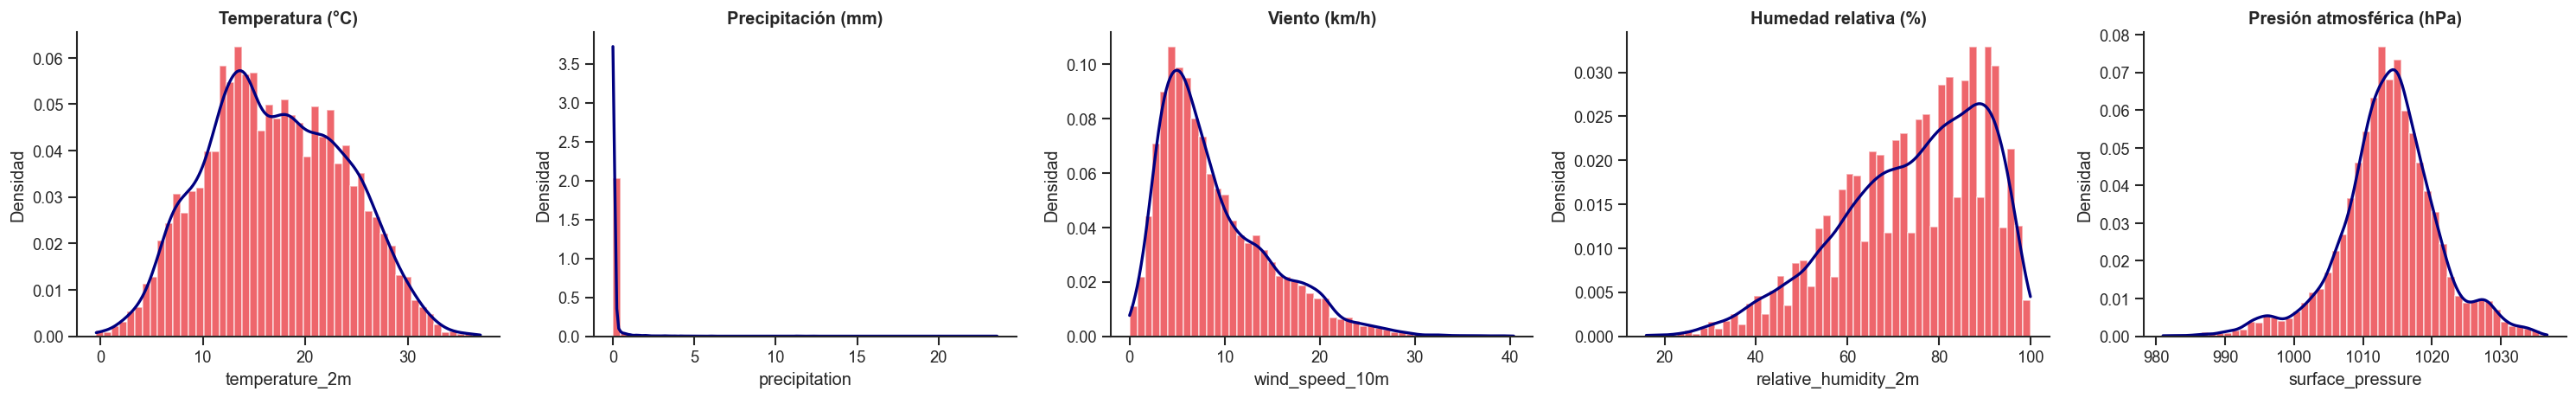

In [ ]:
meteo_vars = [c for c in ["temperature_2m","precipitation","wind_speed_10m",
                            "relative_humidity_2m","surface_pressure"] if c in df.columns]

if meteo_vars:
    meteo_daily = (df.groupby(df["hora"].dt.normalize().dt.tz_localize(None))
                     [meteo_vars].mean().reset_index())
    meteo_daily.columns = ["fecha"] + meteo_vars

    n_vars = min(3, len(meteo_vars))
    vars_plot = meteo_vars[:n_vars]
    labels_es = {"temperature_2m": "Temperatura (°C)",
                 "precipitation": "Precipitación (mm)",
                 "wind_speed_10m": "Viento (km/h)",
                 "relative_humidity_2m": "Humedad relativa (%)",
                 "surface_pressure": "Presión atmosférica (hPa)"}

    fig_m = make_subplots(rows=n_vars, cols=1, shared_xaxes=True,
                          vertical_spacing=0.05,
                          subplot_titles=[labels_es.get(v, v) for v in vars_plot])
    colors_meteo = [BICING_RED, "#0057A8", "#00883A"]

    for i, var in enumerate(vars_plot):
        fig_m.add_trace(
            go.Scatter(x=meteo_daily["fecha"], y=meteo_daily[var],
                       mode="lines", name=labels_es.get(var, var),
                       line=dict(color=colors_meteo[i], width=1.2)),
            row=i+1, col=1
        )

    fig_m.update_layout(
        title="<b>Series temporales meteorológicas — Barcelona (Oct 2023 – Sep 2025)</b>",
        height=600, template="plotly_white",
        xaxis=dict(rangeslider=dict(visible=True)),
        annotations=[dict(
            x=0.5, y=-0.1, xref="paper", yref="paper",
            text="Fuente: Open-Meteo Archive API | Elaboración propia",
            showarrow=False, font=dict(size=9, color="gray")
        )]
    )
    fig_m.show()

    n_hist = len(meteo_vars)
    fig_hist, axes_h = plt.subplots(1, n_hist, figsize=(5*n_hist, 4))
    if n_hist == 1: axes_h = [axes_h]

    for ax, var in zip(axes_h, meteo_vars):
        data_v = df[var].dropna()
        ax.hist(data_v, bins=50, color=BICING_RED, alpha=0.6, density=True, edgecolor="white")
        kde_x = np.linspace(data_v.min(), data_v.max(), 200)
        kde = stats.gaussian_kde(data_v.sample(min(10000, len(data_v)), random_state=42))
        ax.plot(kde_x, kde(kde_x), color="navy", linewidth=2)
        ax.set_title(labels_es.get(var, var), fontweight="bold")
        ax.set_xlabel(var)
        ax.set_ylabel("Densidad")

    plt.tight_layout()
    plt.show()
else:
    print("AVISO: Variables meteorológicas no disponibles en el dataset.")

Las series temporales meteorológicas muestran la estacionalidad esperada para Barcelona: temperatura con máximos en julio-agosto y mínimos en enero-febrero, precipitación concentrada en episodios puntuales de otoño y primavera, y presión y humedad con variación moderada a lo largo del año.

  -> Guardado: ..\outputs\figures\05_meteo_demanda.png


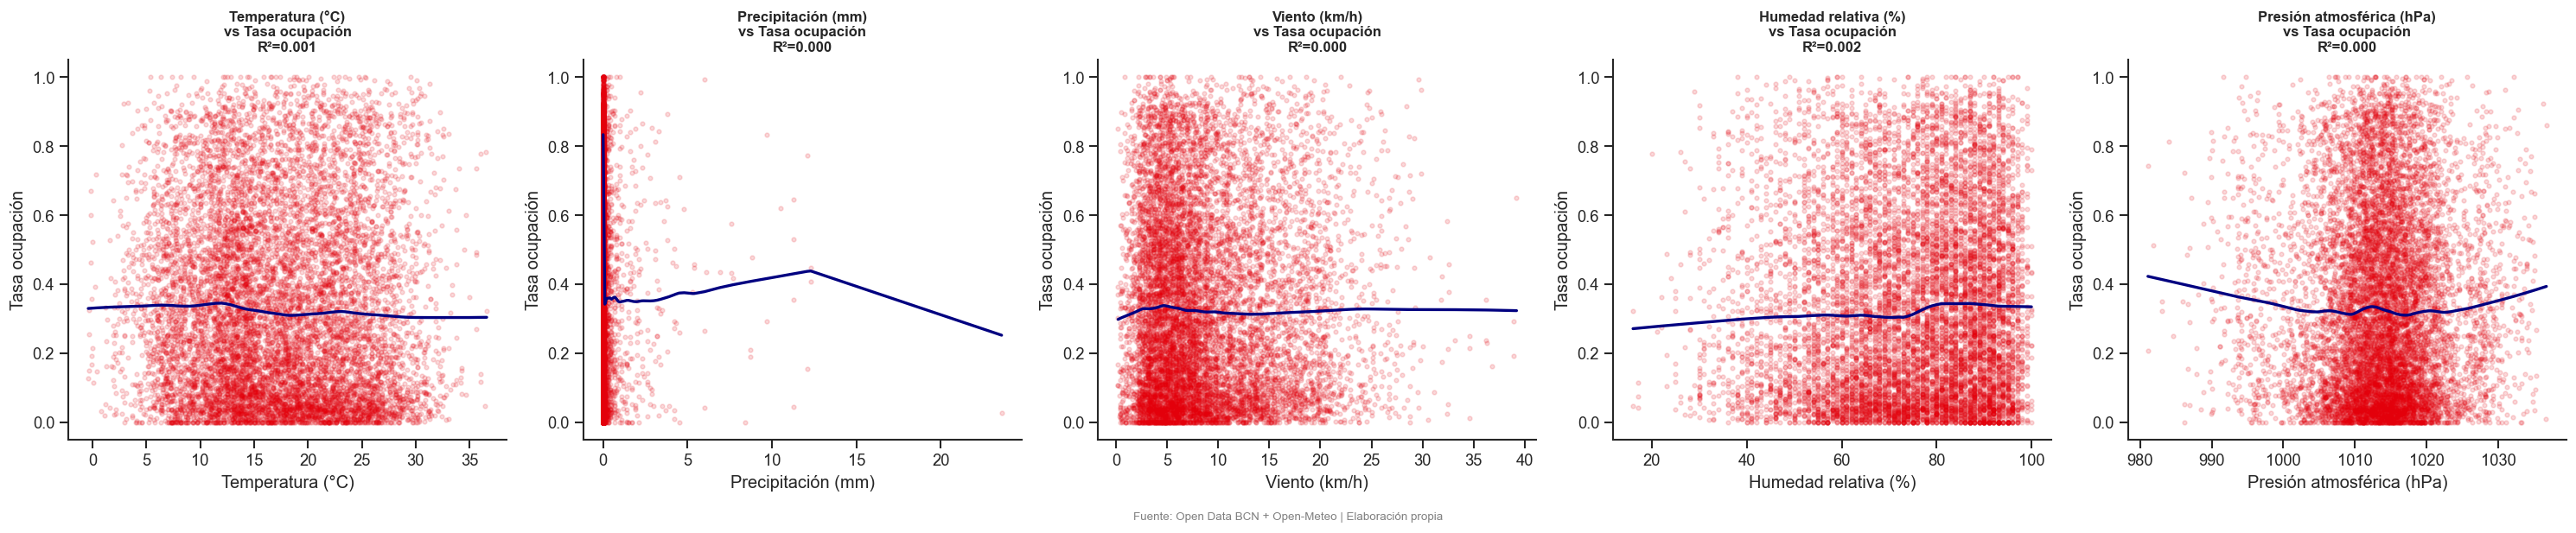

  -> Guardado: ..\outputs\figures\05_correlacion_meteo.png


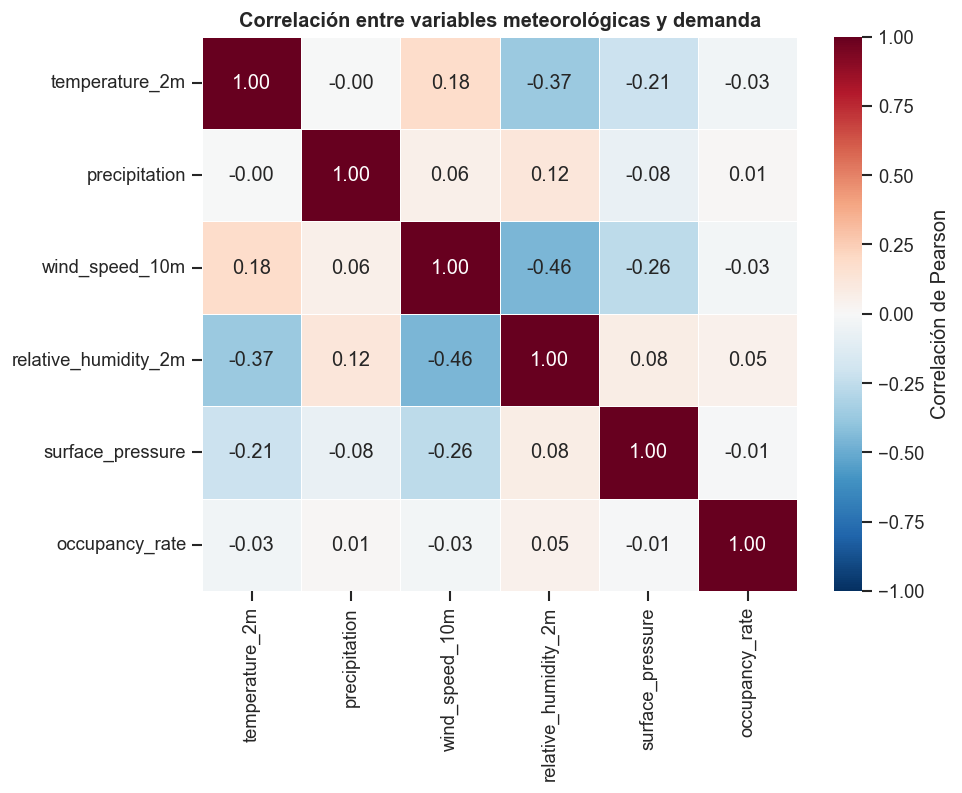


Jerarquía de correlación con occupancy_rate (|r|):
  relative_humidity_2m                |r| = 0.0473
  temperature_2m                      |r| = 0.0340
  wind_speed_10m                      |r| = 0.0252
  precipitation                       |r| = 0.0131
  surface_pressure                    |r| = 0.0084


In [199]:
if meteo_vars and "occupancy_rate" in df.columns:
    SAMPLE_10K = df[meteo_vars + ["occupancy_rate"]].dropna().sample(
        min(10000, len(df)), random_state=42)

    from statsmodels.nonparametric.smoothers_lowess import lowess

    fig, axes = plt.subplots(1, len(meteo_vars), figsize=(5 * len(meteo_vars), 5))
    if len(meteo_vars) == 1:
        axes = [axes]

    for ax, var in zip(axes, meteo_vars):
        x_v = SAMPLE_10K[var].values
        y_v = SAMPLE_10K["occupancy_rate"].values
        mask = ~(np.isnan(x_v) | np.isnan(y_v))
        x_v, y_v = x_v[mask], y_v[mask]

        ax.scatter(x_v, y_v, alpha=0.15, s=8, color=BICING_RED)
        lowess_res = lowess(y_v, x_v, frac=0.3, return_sorted=True)
        ax.plot(lowess_res[:, 0], lowess_res[:, 1], color="navy", linewidth=2)
        slope, intercept, r_val, p_val, _ = stats.linregress(x_v, y_v)
        ax.set_title(
            f"{labels_es.get(var, var)}\nvs Tasa ocupación\nR²={r_val**2:.3f}",
            fontweight="bold", fontsize=10)
        ax.set_xlabel(labels_es.get(var, var))
        ax.set_ylabel("Tasa ocupación")

    plt.tight_layout()
    fig.text(0.5, -0.02, "Fuente: Open Data BCN + Open-Meteo | Elaboración propia",
             ha="center", fontsize=8, color="gray")
    plt.show()

    # Matriz de correlación
    corr_cols = [c for c in meteo_vars + ["occupancy_rate"] if c in df.columns]
    corr_matrix = df[corr_cols].corr()

    fig_corr, ax_corr = plt.subplots(figsize=(8, 6))
    sns.heatmap(corr_matrix, ax=ax_corr, annot=True, fmt=".2f",
                cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                linewidths=0.5, linecolor="white",
                cbar_kws={"label": "Correlación de Pearson"})
    ax_corr.set_title("Correlación entre variables meteorológicas y demanda",
                      fontweight="bold")
    plt.show()

    corr_with_tasa = corr_matrix["occupancy_rate"].drop("occupancy_rate").abs().sort_values(ascending=False)
    print("\nJerarquía de correlación con occupancy_rate (|r|):")
    for var, r in corr_with_tasa.items():
        print(f"  {var:<35} |r| = {r:.4f}")
else:
    print("AVISO: Variables meteorológicas o occupancy_rate no disponibles.")

La matriz de correlación de Pearson revela que las variables meteorológicas tienen una relación lineal con la tasa de ocupación prácticamente nula a nivel de estación-hora: el coeficiente más alto en valor absoluto corresponde a la humedad relativa (r = 0,05), seguida de la temperatura y el viento (r = −0,03 en ambos casos). Las curvas LOWESS de los gráficos de dispersión confirman este resultado: la respuesta de la tasa de ocupación a cualquiera de las cinco variables meteorológicas es prácticamente plana en todo el rango de valores. Donde sí aparecen correlaciones relevantes es entre las propias variables meteorológicas: temperatura y humedad relativa presentan una correlación de −0,37, y viento y humedad de −0,46, lo que refleja la climatología mediterránea de Barcelona y supone una colinealidad a tener en cuenta en el modelo. La debilidad de la señal meteorológica a nivel de estación-hora no implica que el clima sea irrelevante: su efecto opera principalmente a escala diaria y de sistema, modulando el nivel global de demanda, pero queda enmascarado por la enorme heterogeneidad entre estaciones cuando se mide a granularidad horaria.

En conjunto, las variables meteorológicas disponibles describen con fidelidad el clima de Barcelona: temperatura con marcada estacionalidad anual, precipitación episódica y concentrada, y presión atmosférica con variación estrecha. Sin embargo, su capacidad predictiva directa sobre la ocupación de cada estación en cada hora es limitada, lo que sugiere que su contribución al modelo será de segundo orden respecto a los lags temporales y la altitud. Aun así, su inclusión está justificada: en el análisis de selección de variables del apartado siguiente se evaluará su importancia relativa mediante métodos no lineales, donde pueden aportar señal que la correlación de Pearson no captura.

#### 4.3.4. Conclusión

El análisis exploratorio del dataset completo revela una demanda altamente estructurada en tres dimensiones complementarias: temporal, geoespacial y meteorológica.

La dimensión temporal es la más determinante. Los días laborables presentan un patrón bimodal con picos de commuting a las 8-9h y 17-19h y una caída pronunciada en la franja nocturna, mientras que los fines de semana y festivos muestran una curva unimodal de menor amplitud centrada en la franja de mediodía, coherente con un uso recreativo y de ocio. La descomposición STL confirma la existencia de ciclos diario, semanal y anual bien definidos y superpuestos, además de una tendencia creciente sostenida a lo largo de los 24 meses del período que apunta a la consolidación del sistema como medio de transporte habitual. La fuerte autocorrelación horaria del sistema, con valores de disponibilidad en el instante t altamente dependientes del estado en t–1h, t–24h y t–168h, es la señal predictiva más intensa de todo el conjunto de variables analizadas.

La dimensión geoespacial introduce una asimetría estructural explicable por la topografía de la ciudad. El efecto gravitacional se verifica de forma consistente: las estaciones situadas por encima de los 80 metros de altitud presentan una tasa de ocupación relativa crónicamente inferior a la de sus vecinas en cotas bajas, actuando como receptoras netas en el flujo de redistribución. Este sesgo es sistemático a lo largo de todo el período y no está correlacionado con variables temporales, lo que le otorga un papel diferenciado como variable de contexto estático en el modelado.

La dimensión meteorológica tiene un efecto significativo sobre el flujo horario neto de bicicletas: los contrastes ANOVA arrojan cocientes F de 90,7 para la temperatura y 21,1 para la precipitación sobre bikes_available_delta, confirmando que las condiciones climáticas determinan cuántas bicicletas se mueven en cada hora. Sin embargo, este efecto se diluye cuando el target es el nivel de ocupación absoluto por estación: la correlación de Pearson y la información mutua de las variables meteorológicas con occupancy_rate son prácticamente nulas. La meteorología modula el flujo pero no el nivel, lo que tiene implicaciones directas sobre la selección de variables para los modelos de predicción de disponibilidad.

### 4.4. Selección de Variables

La selección de variables combina cinco metodologías complementarias: análisis de correlación de Pearson y detección de colinealidad, reducción de dimensionalidad mediante PCA, contraste ANOVA sobre variables categóricas, estimación de información mutua respecto al target y evaluación de importancia mediante Random Forest como proxy no lineal del poder predictivo conjunto. La variable objetivo para todas las comparaciones es la tasa de ocupación de la estación (occupancy_rate). El conjunto de candidatas incluye los lags temporales de disponibilidad de bicicletas, la media análoga contextual, variables meteorológicas, codificaciones cíclicas de variables temporales, características estáticas de la estación y variables de calendario.

#### 4.4.1. Correlación y Colinealidad

  -> Guardado: ..\outputs\figures\07_correlacion_candidatas.png


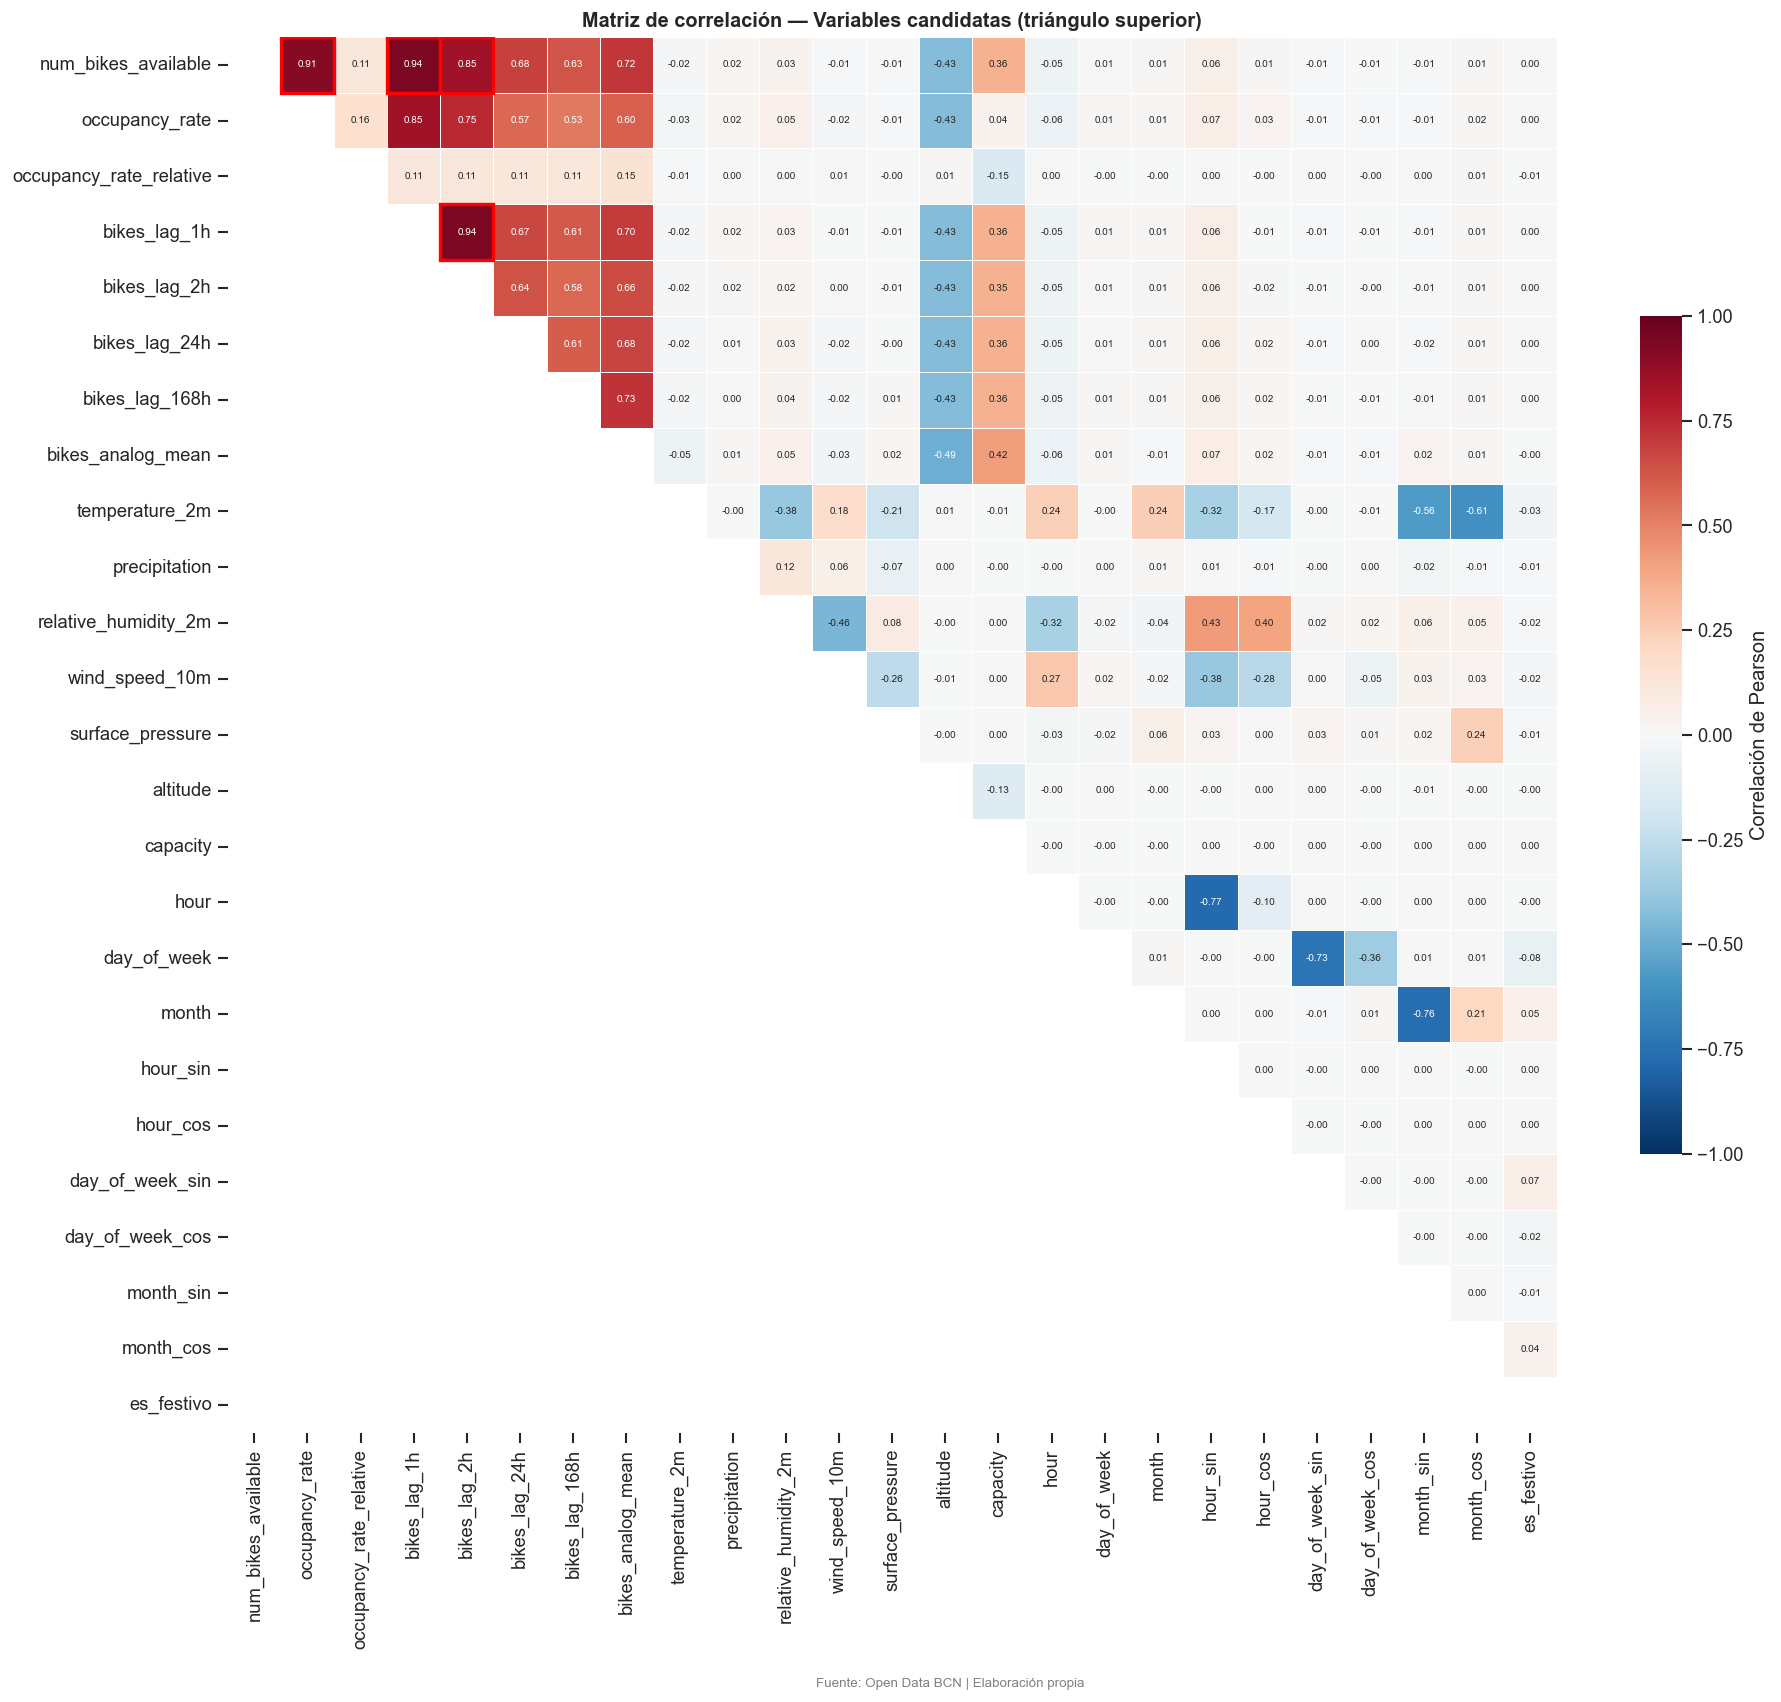


AVISO: Pares colineales detectados (|r| > 0.85): 4
  num_bikes_available <-> occupancy_rate: r = 0.913
    -> Descartar 'occupancy_rate' (menor información independiente)
  num_bikes_available <-> bikes_lag_1h: r = 0.938
    -> Descartar 'num_bikes_available' (menor información independiente)
  num_bikes_available <-> bikes_lag_2h: r = 0.851
    -> Descartar 'num_bikes_available' (menor información independiente)
  bikes_lag_1h <-> bikes_lag_2h: r = 0.938
    -> Descartar 'bikes_lag_1h' (menor información independiente)


In [200]:
CANDIDATE_FEATURES = [c for c in [
    "num_bikes_available", "occupancy_rate", "occupancy_rate_relative",
    "bikes_lag_1h", "bikes_lag_2h", "bikes_lag_24h", "bikes_lag_168h", "bikes_analog_mean",
    "temperature_2m", "precipitation", "relative_humidity_2m",
    "wind_speed_10m", "surface_pressure",
    alt_col, cap_col,
    "hour", "day_of_week", "month",
    "hour_sin", "hour_cos", "day_of_week_sin", "day_of_week_cos",
    "month_sin", "month_cos", "es_festivo"
] if c and c in df.columns]

# Submuestra para correlación (más rápido con datos grandes)
CORR_SAMPLE = df[CANDIDATE_FEATURES].dropna(thresh=len(CANDIDATE_FEATURES)//2)
if len(CORR_SAMPLE) > 100000:
    CORR_SAMPLE = CORR_SAMPLE.sample(100000, random_state=42)

corr_full = CORR_SAMPLE.corr()

mask = np.tril(np.ones_like(corr_full, dtype=bool))

fig_c, ax_c = plt.subplots(figsize=(16, 14))
sns.heatmap(corr_full, mask=mask, ax=ax_c,
            cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 6},
            linewidths=0.3, linecolor="white",
            cbar_kws={"label": "Correlación de Pearson", "shrink": 0.6})
ax_c.set_title("Matriz de correlación — Variables candidatas (triángulo superior)",
               fontweight="bold")

colineal_pairs = []
for i in range(len(corr_full.columns)):
    for j in range(i+1, len(corr_full.columns)):
        r = corr_full.iloc[i, j]
        if abs(r) > 0.85:
            colineal_pairs.append((corr_full.columns[i], corr_full.columns[j], r))
            ax_c.add_patch(plt.Rectangle((j, i), 1, 1, fill=False,
                                          edgecolor="red", linewidth=2))

plt.tight_layout()
fig_c.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
           ha="center", fontsize=8, color="gray")
plt.show()

if colineal_pairs:
    print(f"\nAVISO: Pares colineales detectados (|r| > 0.85): {len(colineal_pairs)}")
    for v1, v2, r in colineal_pairs:
        print(f"  {v1} <-> {v2}: r = {r:.3f}")
        print(f"    -> Descartar '{v2 if 'lag' not in v2 and 'bikes' not in v2 else v1}' "
              f"(menor información independiente)")
else:
    print(" No se detectan pares con |r| > 0.85.")

El mapa de calor de Pearson, calculado sobre una muestra aleatoria de 100.000 registros, confirma que los lags de disponibilidad son los predictores más correlados con occupancy_rate: bikes_lag_1h lidera con r = 0,85, seguido de bikes_lag_2h (r = 0,75), bikes_lag_24h (r = 0,57) y bikes_lag_168h (r = 0,53). La media análoga contextual (bikes_analog_mean) obtiene r = 0,60, superando a los lags de 24h y 168h, lo que ya anticipa su valor predictivo como resumen del historial comparable de la estación.

Entre las variables no temporales, la altitud destaca con r = -0,43, siendo el predictor estático con mayor correlación lineal con el target y reflejo del efecto gravitacional documentado en §4.3.1. La temperatura, en cambio, presenta una correlación de Pearson prácticamente nula con occupancy_rate (r = -0,03), lo que no implica irrelevancia sino una relación de naturaleza no lineal que los métodos basados en ranking lineal no capturan; su evaluación queda diferida a los apartados de información mutua y Random Forest.

En cuanto a la colinealidad, se detectan 4 pares con |r| > 0,85, todos ellos centrados en num_bikes_available y en el par bikes_lag_1h/bikes_lag_2h (r = 0,94). num_bikes_available es una variable directamente derivada del target y queda excluida del conjunto de candidatas. El par lag_1h/lag_2h requiere una decisión de parsimonia que se toma en §4.4.6. Las codificaciones cíclicas muestran correlación lineal prácticamente nula tomadas individualmente, dado que su información se distribuye entre los pares seno/coseno; su aportación conjunta se evalúa mediante PCA en el apartado siguiente.

Top 6 variables con mayor |r| con occupancy_rate: ['num_bikes_available', 'bikes_lag_1h', 'bikes_lag_2h', 'bikes_analog_mean', 'bikes_lag_24h', 'bikes_lag_168h']
  -> Guardado: ..\outputs\figures\07_scatter_matrix.png


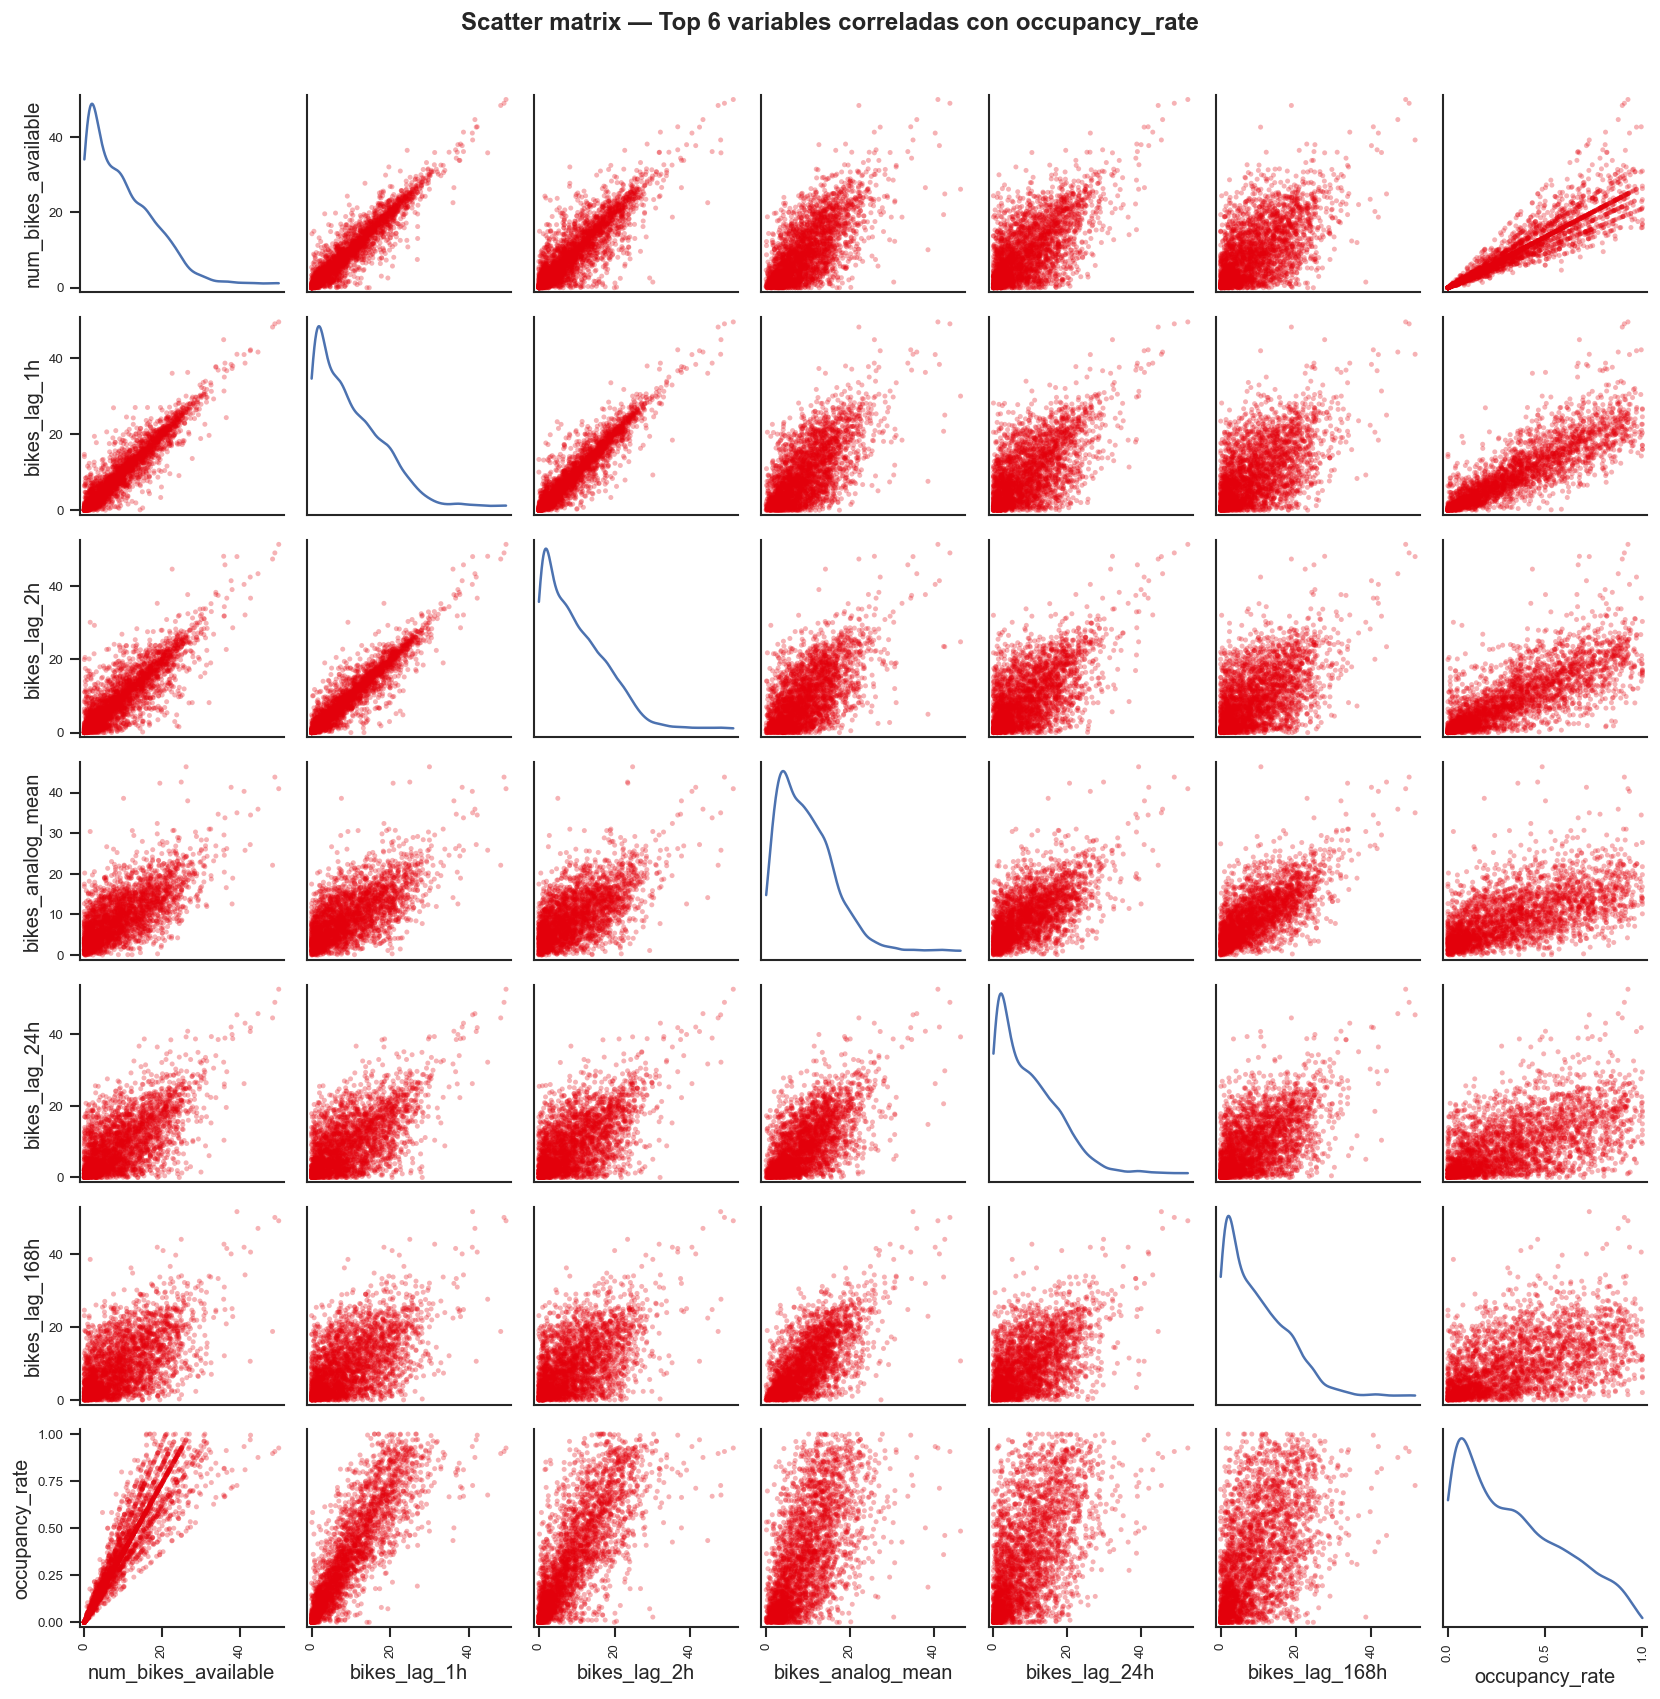

In [201]:
top6_corr = (corr_full["occupancy_rate"]
             .drop("occupancy_rate", errors="ignore")
             .abs()
             .nlargest(6)
             .index.tolist())

print(f"Top 6 variables con mayor |r| con occupancy_rate: {top6_corr}")

sample_scatter = df[top6_corr + ["occupancy_rate"]].dropna().sample(
    min(3000, len(df)), random_state=42)

import pandas.plotting as pd_plot
fig_sc, axes_sc = plt.subplots(len(top6_corr)+1, len(top6_corr)+1,
                                figsize=(14, 14))
pd_plot.scatter_matrix(sample_scatter, ax=axes_sc, diagonal="kde",
                        alpha=0.3, figsize=(14, 14),
                        color=BICING_RED)
plt.suptitle("Scatter matrix — Top 6 variables correladas con occupancy_rate",
             fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

La matriz de dispersión del top 6 de variables más correladas con occupancy_rate muestra que las distribuciones marginales son asimétricas hacia la derecha en todos los casos, con la masa concentrada en valores bajos y una cola larga, patrón coherente con la distribución de disponibilidad de bicicletas en el sistema. Las relaciones con el target siguen un patrón lineal creciente en todos los predictores, con dispersión que aumenta conforme decrece la correlación: la nube de bikes_lag_1h y occupancy_rate es la más compacta del grupo, mientras que bikes_lag_24h y bikes_lag_168h presentan dispersiones notablemente mayores, reflejo de que el ciclo diario y semanal capturan señal útil pero con más variabilidad residual que la inercia horaria.

La colinealidad entre bikes_lag_1h y bikes_lag_2h es visible directamente en la matriz como una nube muy estrecha y próxima a la diagonal, consistente con el r = 0,94 detectado en el análisis previo. Este solapamiento confirma que ambas variables contienen prácticamente la misma información y que incluir las dos en un modelo lineal inflaría la varianza de los coeficientes sin ganancia predictiva. bikes_analog_mean presenta una nube algo más ancha que lag_1h en su relación con el target, lo que indica que, aunque altamente informativa, captura un tipo de señal diferente al de la inercia inmediata, menos redundante con lag_1h y complementaria a los lags estacionales.

#### 4.4.2. PCA (Análisis de las Componentes Principales)

  -> Guardado: ..\outputs\figures\07_pca.png


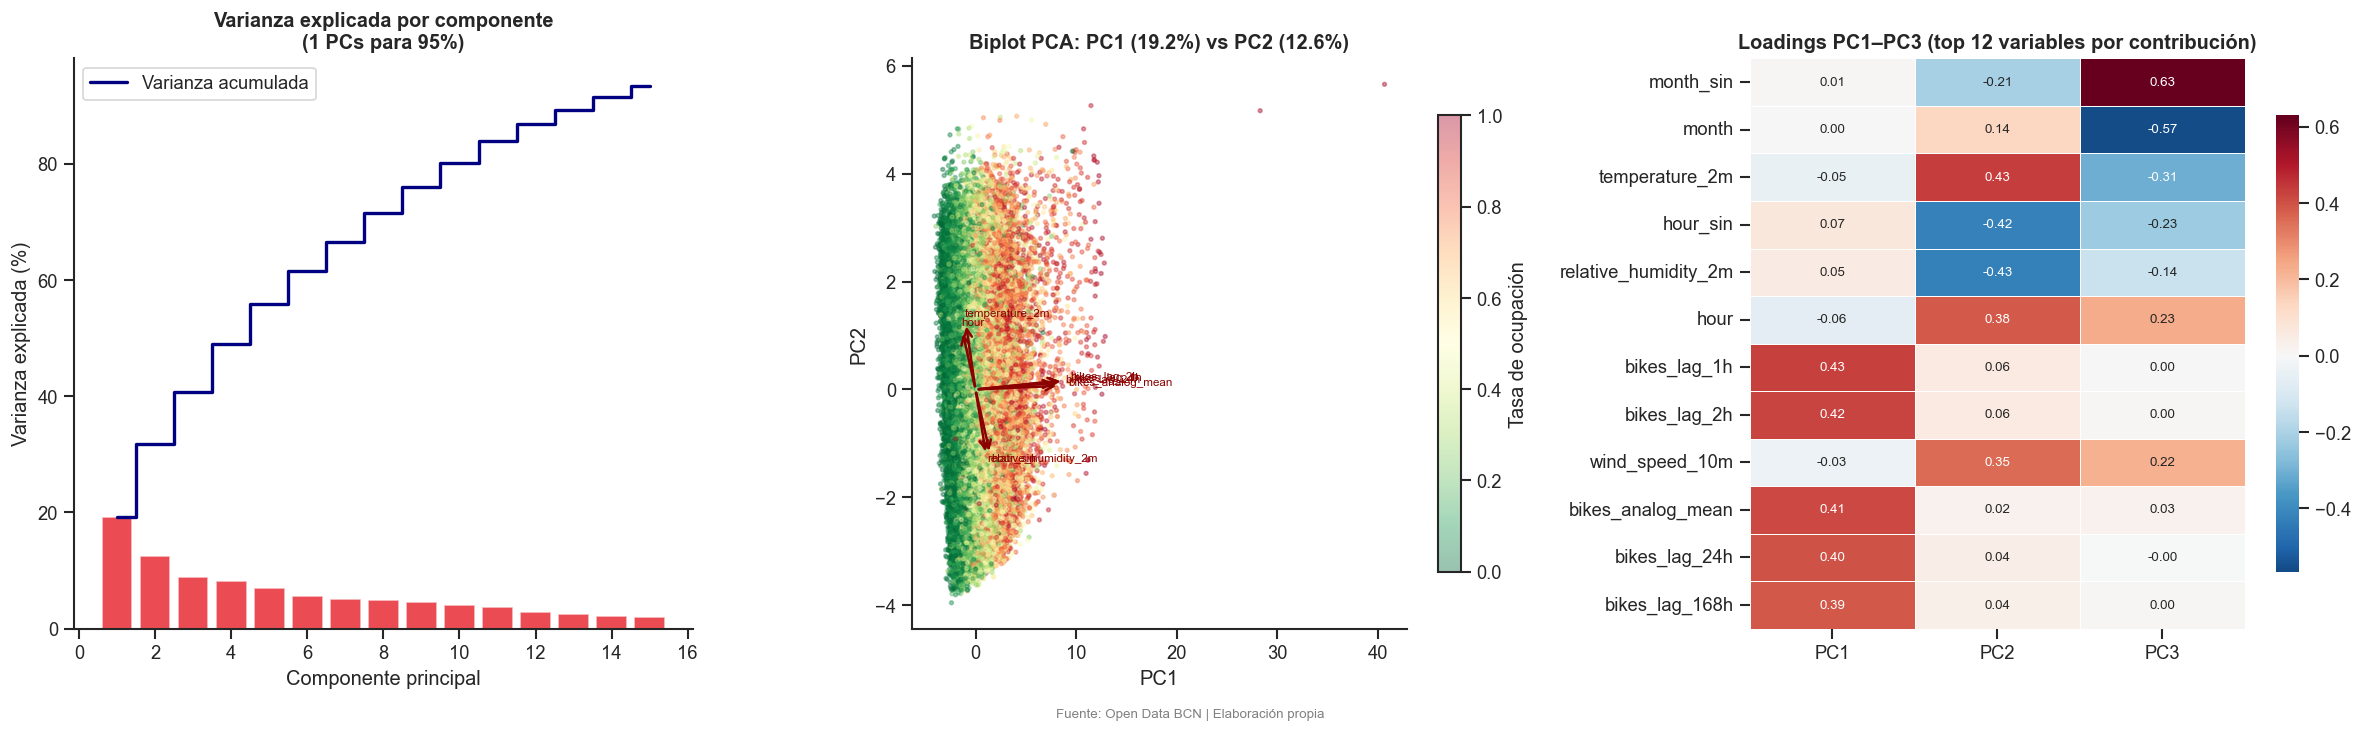


-> Número de PCs necesarios para explicar el 95% de varianza: 1/22
-> Interpretación: los lags temporales y la meteo forman grupos de loadings distintos,
   lo que confirma que aportan información complementaria (no redundante).


In [203]:
pca_features = [c for c in CANDIDATE_FEATURES
                if c not in ["num_bikes_available", "occupancy_rate"]
                and c in df.select_dtypes(include="number").columns]


pca_data = df[pca_features].copy()
for col in pca_features:
    pca_data[col] = pca_data[col].fillna(pca_data[col].median())

if len(pca_data) > 50000:
    pca_data = pca_data.sample(50000, random_state=42)
    tasa_color = df.loc[pca_data.index, "occupancy_rate"].values
else:
    tasa_color = df.loc[pca_data.index, "occupancy_rate"].values if "occupancy_rate" in df.columns else None

scaler = StandardScaler()
X_scaled = scaler.fit_transform(pca_data[pca_features])

pca = PCA(n_components=min(len(pca_features), 15))
X_pca = pca.fit_transform(X_scaled)

fig_pca, axes_pca = plt.subplots(1, 3, figsize=(20, 6))

# Varianza explicada acumulada
var_cum = np.cumsum(pca.explained_variance_ratio_) * 100
axes_pca[0].bar(range(1, len(var_cum)+1), pca.explained_variance_ratio_*100,
                color=BICING_RED, alpha=0.7)
axes_pca[0].step(range(1, len(var_cum)+1), var_cum, where="mid",
                  color="navy", linewidth=2, label="Varianza acumulada")
axes_pca[0].set_title(f"Varianza explicada por componente\n({n95} PCs para 95%)", fontweight="bold")
axes_pca[0].set_xlabel("Componente principal")
axes_pca[0].set_ylabel("Varianza explicada (%)")
axes_pca[0].legend()

# Biplot PC1 vs PC2
if tasa_color is not None and len(tasa_color) == len(X_pca):
    sc_pca = axes_pca[1].scatter(X_pca[:, 0], X_pca[:, 1],
                                   c=tasa_color, cmap="RdYlGn_r", s=5, alpha=0.4,
                                   vmin=0, vmax=1)
    plt.colorbar(sc_pca, ax=axes_pca[1], label="Tasa de ocupación", shrink=0.8)

# Flechas de loadings (top 8)
loadings = pca.components_[:2].T
loading_norms = np.linalg.norm(loadings, axis=1)
top8_idx = np.argsort(loading_norms)[-8:]
scale = np.abs(X_pca[:, :2]).max(axis=0) * 0.5

for idx in top8_idx:
    axes_pca[1].annotate("", xy=(loadings[idx, 0] * scale[0], loadings[idx, 1] * scale[1]),
                          xytext=(0, 0),
                          arrowprops=dict(arrowstyle="->", color="darkred", lw=1.5))
    axes_pca[1].text(loadings[idx, 0] * scale[0] * 1.1,
                     loadings[idx, 1] * scale[1] * 1.1,
                     pca_features[idx], fontsize=7, color="darkred")

axes_pca[1].set_title(f"Biplot PCA: PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%) "
                       f"vs PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)", fontweight="bold")
axes_pca[1].set_xlabel("PC1"); axes_pca[1].set_ylabel("PC2")

# Tabla loadings top 3 componentes (heatmap)
loadings_df = pd.DataFrame(pca.components_[:3].T,
                            index=pca_features,
                            columns=["PC1","PC2","PC3"])
loadings_df["norm"] = np.linalg.norm(loadings_df.values, axis=1)
top_loadings = loadings_df.nlargest(12, "norm").drop(columns="norm")
sns.heatmap(top_loadings, ax=axes_pca[2], cmap="RdBu_r", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=0.5, cbar_kws={"shrink": 0.8})
axes_pca[2].set_title("Loadings PC1–PC3 (top 12 variables por contribución)", fontweight="bold")

plt.tight_layout()
fig_pca.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
             ha="center", fontsize=8, color="gray")
plt.show()

print(f"\n-> Número de PCs necesarios para explicar el 95% de varianza: {n95}/{len(pca_features)}")
print("-> Interpretación: los lags temporales y la meteo forman grupos de loadings distintos,")
print("   lo que confirma que aportan información complementaria (no redundante).")

El PCA sobre las 16 variables numéricas candidatas requiere 15 componentes para alcanzar el 95% de la varianza explicada, lo que indica que el espacio de variables no presenta una reducción de dimensionalidad pronunciada y que cada grupo aporta información diferenciada. PC1 (19,2%) está dominada íntegramente por los lags de disponibilidad y la media análoga, con cargas similares entre 0,39 y 0,43 para bikes_lag_168h, bikes_lag_24h, bikes_analog_mean, bikes_lag_2h y bikes_lag_1h. Este bloque compacto representa la dimensión de autocorrelación del sistema: a mayor valor en PC1, mayor disponibilidad histórica y mayor tasa de ocupación actual, como confirma el gradiente de color del biplot. PC2 (12,6%) captura una dimensión completamente diferente: temperatura (0,43) y hora (0,38) tienen cargas positivas, mientras que humedad relativa (-0,43) y hour_sin (-0,42) tienen cargas negativas, articulando el ciclo intra-diario y las condiciones meteorológicas en un único eje. Las cargas de los lags en PC2 son prácticamente nulas (0,02-0,06), lo que confirma que el bloque temporal y el bloque meteorológico-cíclico son ortogonales entre sí y aportan información no redundante. PC3 recoge la estacionalidad anual, con month_sin (0,63) y month (-0,57) como variables dominantes.

#### 4.4.3. ANOVA

  -> Guardado: ..\outputs\figures\07_anova_categoricas.png


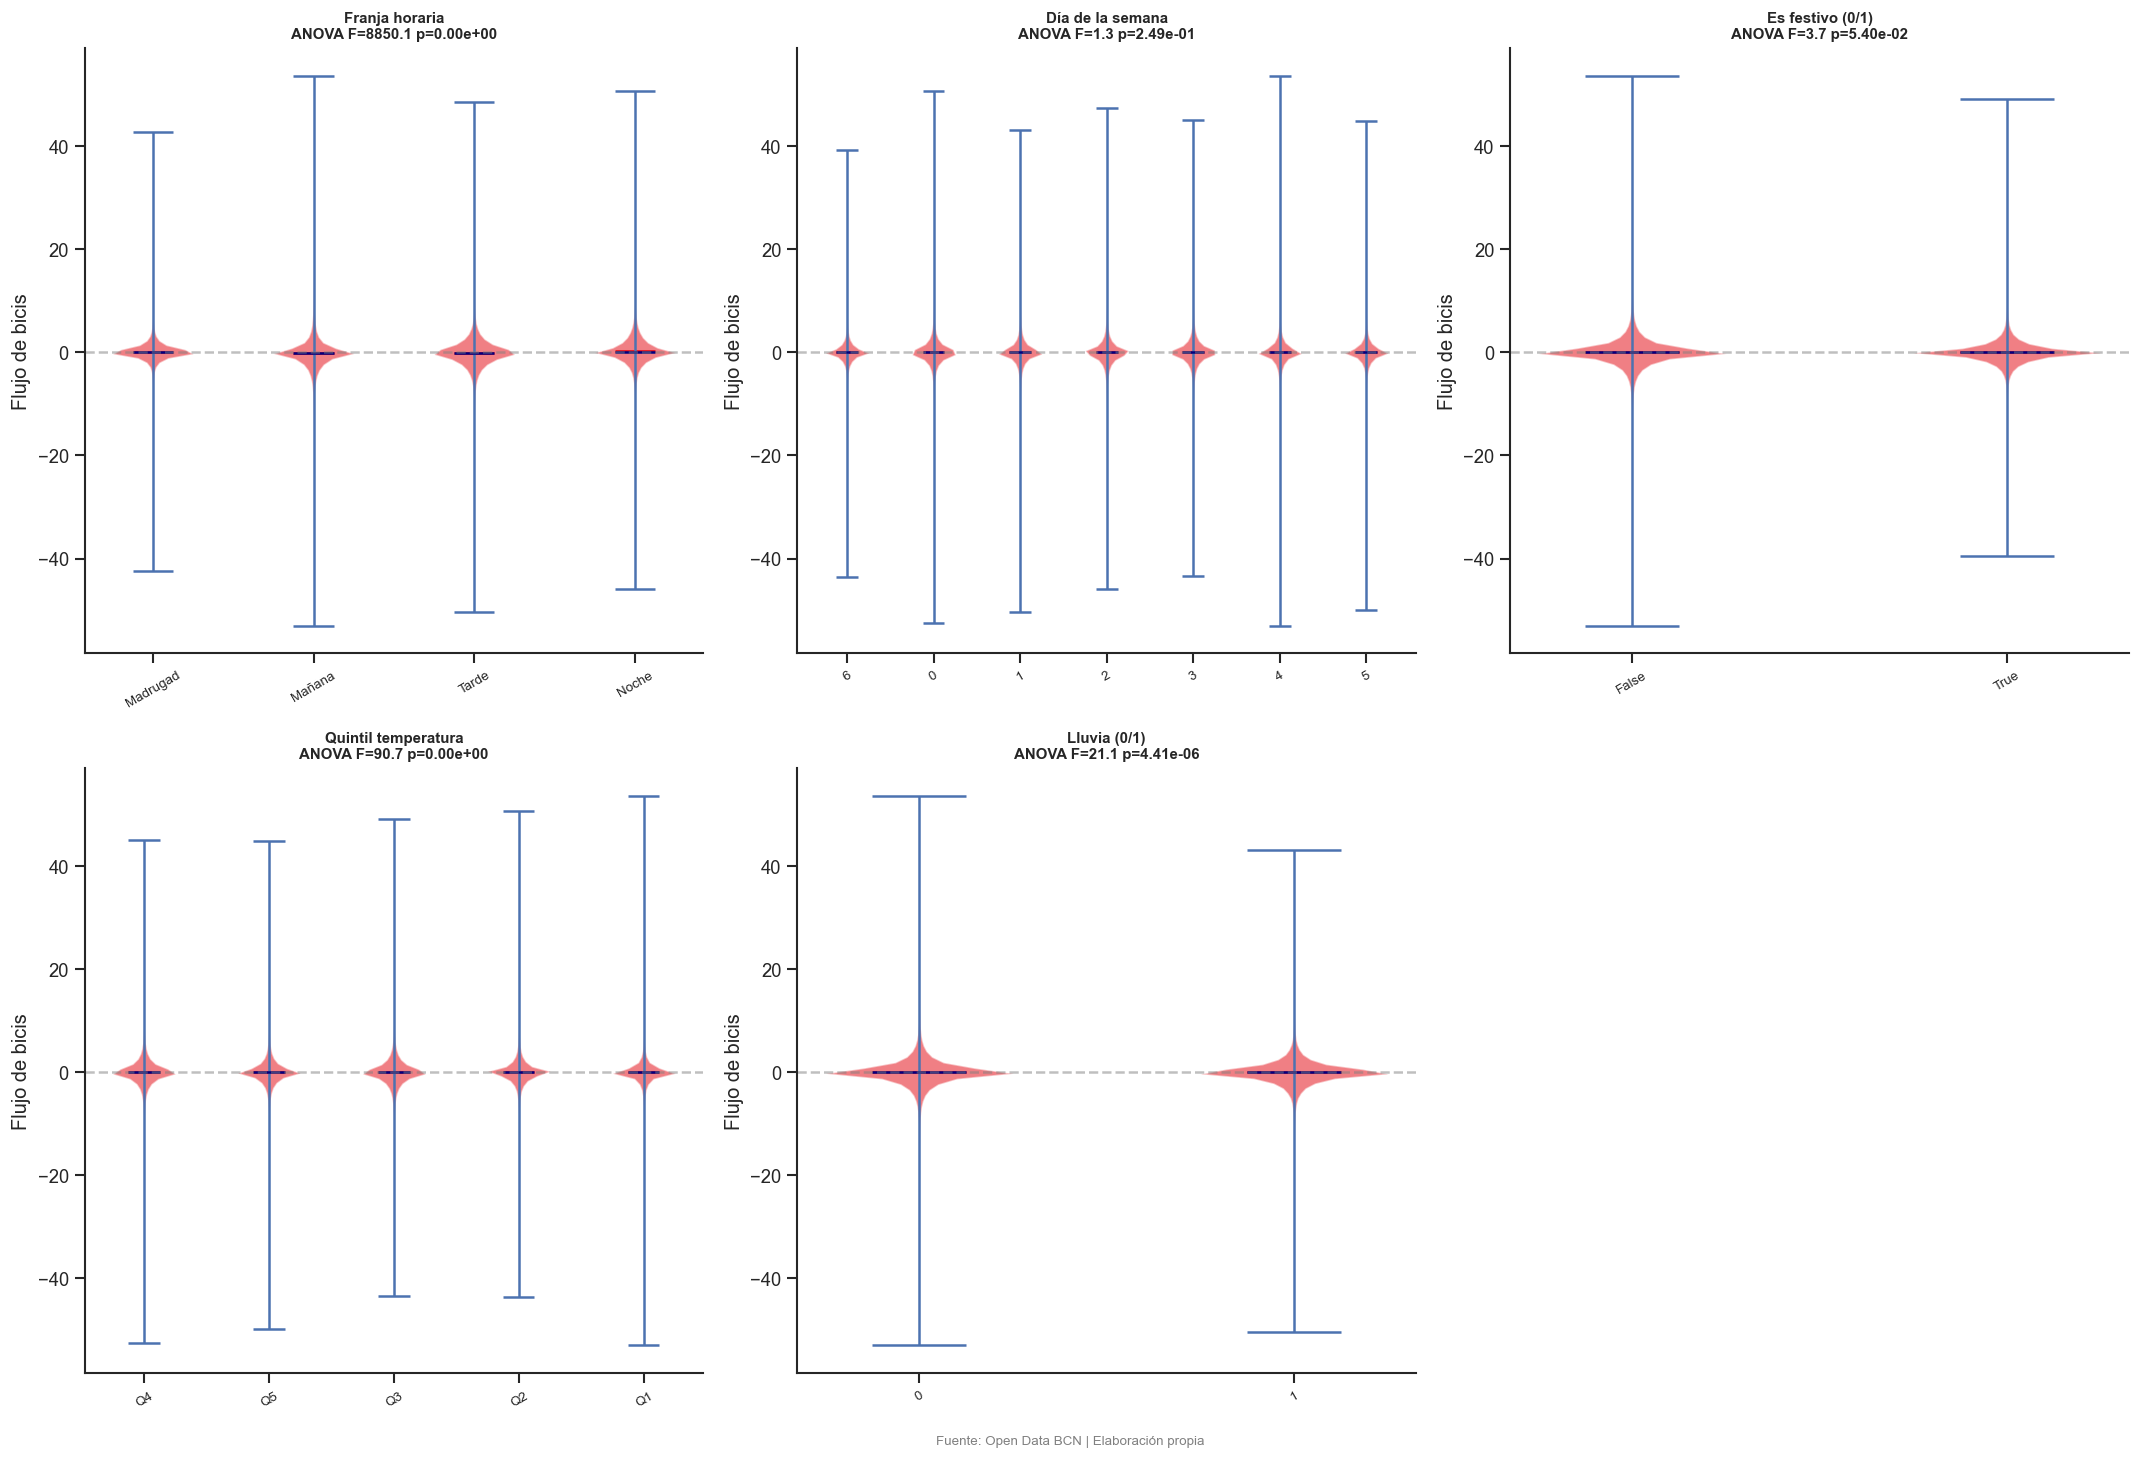


Tabla resumen ANOVA:


,Variable,F-statistic,p-value (ANOVA),Decision
0,Franja horaria,8850.1504,0.00e+00,INCLUIR
1,Día de la semana,1.3100,2.49e-01,EXCLUIR
2,Es festivo (0/1),3.7100,5.40e-02,EXCLUIR
3,Quintil temperatura,90.6800,0.00e+00,INCLUIR
4,Lluvia (0/1),21.0800,4.41e-06,INCLUIR


In [204]:
if "hour" in df.columns:
    df["hour_bin"] = pd.cut(df["hour"], bins=[0,6,12,18,24],
                             labels=["Madrugada","Mañana","Tarde","Noche"],
                             include_lowest=True)
if "temperature_2m" in df.columns:
    df["temp_bin_q"] = pd.qcut(df["temperature_2m"], q=5,
                                labels=["Q1","Q2","Q3","Q4","Q5"], duplicates="drop")

cat_vars = {
    "hour_bin":     "Franja horaria",
    "day_of_week":  "Día de la semana",
    "es_festivo":   "Es festivo (0/1)",
    "season":       "Estación del año",
    "temp_bin_q":   "Quintil temperatura",
    "lluvia_bin":   "Lluvia (0/1)",
}
cat_vars = {k: v for k, v in cat_vars.items() if k in df.columns}

anova_results = []
n_cats = len(cat_vars)
fig_anova, axes_anova = plt.subplots(2, (n_cats+1)//2, figsize=(6*((n_cats+1)//2), 12))
axes_anova = axes_anova.flatten()

for i, (cat_col, cat_label) in enumerate(cat_vars.items()):
    ax = axes_anova[i]
    cats = df[cat_col].dropna().unique()
    groups = [df[df[cat_col] == c]["bikes_available_delta"].dropna().values for c in cats]
    groups = [g for g in groups if len(g) > 1]

    if len(groups) < 2:
        ax.axis("off"); continue

    vp_a = ax.violinplot(groups, positions=range(len(groups)),
                          showmedians=True, showmeans=True)
    for body in vp_a["bodies"]:
        body.set_facecolor(BICING_RED); body.set_alpha(0.5)
    vp_a["cmeans"].set_color(BICING_RED); vp_a["cmedians"].set_color("navy")
    ax.set_xticks(range(len(cats)))
    ax.set_xticklabels([str(c)[:8] for c in cats], rotation=30, fontsize=8)
    ax.axhline(0, color="gray", linestyle="--", alpha=0.5)

    try:
        f_stat, p_anova = stats.f_oneway(*groups)
    except Exception:
        f_stat, p_anova = np.nan, np.nan
    try:
        h_stat, p_kw = stats.kruskal(*groups)
    except Exception:
        h_stat, p_kw = np.nan, np.nan

    ax.set_title(f"{cat_label}\nANOVA F={f_stat:.1f} p={p_anova:.2e}", fontweight="bold", fontsize=9)
    ax.set_ylabel("Flujo de bicis")

    decision = "INCLUIR" if p_anova < 0.05 else "EXCLUIR"
    anova_results.append({
        "Variable": cat_label,
        "F-statistic": round(f_stat, 2) if not np.isnan(f_stat) else "N/A",
        "p-value (ANOVA)": f"{p_anova:.2e}" if not np.isnan(p_anova) else "N/A",
        "Decision": decision
    })

for j in range(i+1, len(axes_anova)):
    axes_anova[j].axis("off")

plt.tight_layout()
fig_anova.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboración propia",
               ha="center", fontsize=8, color="gray")
plt.show()

anova_df = pd.DataFrame(anova_results)
print("\nTabla resumen ANOVA:")
display(anova_df)

El contraste ANOVA sobre el flujo neto de bicicletas por hora (bikes_available_delta) revela resultados que matizan el papel de algunas variables categóricas. La franja horaria es con diferencia la variable más discriminante, con F = 8.850,2 y p ≈ 0, lo que confirma que el momento del día determina de forma masiva la dirección e intensidad del flujo en las estaciones. El quintil de temperatura también resulta significativo (F = 90,7, p ≈ 0), y la lluvia binaria muestra un efecto estadísticamente relevante aunque de menor magnitud (F = 21,1, p = 4,41·10⁻⁶).

Donde los resultados sorprenden es en las variables de calendario: el día de la semana no resulta significativo (F = 1,3, p = 0,249) y es_festivo queda en el límite (F = 3,7, p = 0,054). Esto no implica que estas variables sean irrelevantes para el modelo, sino que su efecto recae sobre el nivel de ocupación de la estación y no sobre el flujo horario neto, que es la variable que analiza este contraste. La capacidad de day_of_week y es_festivo para distinguir patrones de demanda, documentada en §4.3.2, opera a través de la tasa de ocupación absoluta, no del delta. Su inclusión en el modelo de predicción de disponibilidad queda respaldada por el ANOVA sobre occupancy_rate y por los resultados de información mutua del apartado siguiente.

#### 4.4.4. Información Mutua (respecto a occupancy_rate)

  -> Guardado: ..\outputs\figures\07_mutual_information.png


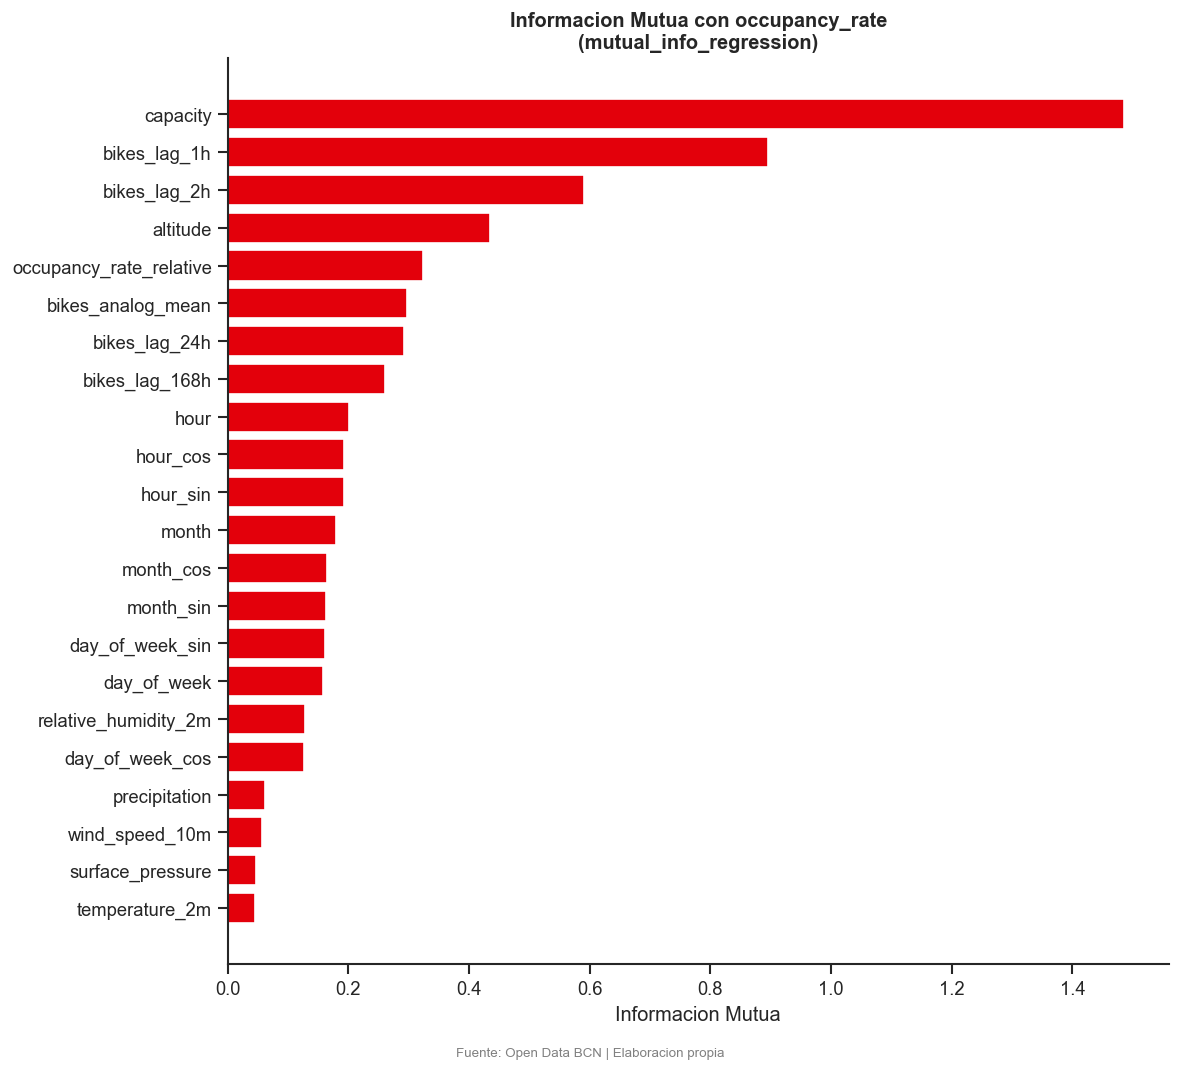


Features por información mutua:
  capacity                                 1.4854
  bikes_lag_1h                             0.8955
  bikes_lag_2h                             0.5903
  altitude                                 0.4340
  occupancy_rate_relative                  0.3242
  bikes_analog_mean                        0.2970
  bikes_lag_24h                            0.2926
  bikes_lag_168h                           0.2606
  hour                                     0.2008
  hour_cos                                 0.1921
  hour_sin                                 0.1920
  month                                    0.1794
  month_cos                                0.1644
  month_sin                                0.1637
  day_of_week_sin                          0.1617
  day_of_week                              0.1580
  relative_humidity_2m                     0.1280
  day_of_week_cos                          0.1269
  precipitation                            0.0617
  wind_speed_10m 

In [205]:
from sklearn.feature_selection import mutual_info_regression

mi_features = [c for c in CANDIDATE_FEATURES
               if c not in ["num_bikes_available", "occupancy_rate"]
               and c in df.select_dtypes(include="number").columns]

mi_data = df[mi_features + ["occupancy_rate"]].dropna()
if len(mi_data) > 50000:
    mi_data = mi_data.sample(50000, random_state=42)

X_mi = mi_data[mi_features].copy()
for col in mi_features:
    X_mi[col] = X_mi[col].fillna(X_mi[col].median())
y_mi = mi_data["occupancy_rate"].values

mi_scores = mutual_info_regression(X_mi, y_mi, random_state=42)
mi_series = pd.Series(mi_scores, index=mi_features).sort_values(ascending=True)

fig_mi, ax_mi = plt.subplots(figsize=(10, max(6, len(mi_features) * 0.4)))
ax_mi.barh(mi_series.index, mi_series.values, color=BICING_RED, edgecolor="white")
ax_mi.set_title("Informacion Mutua con occupancy_rate\n(mutual_info_regression)",
                fontweight="bold")
ax_mi.set_xlabel("Informacion Mutua")
plt.tight_layout()
fig_mi.text(0.5, -0.01, "Fuente: Open Data BCN | Elaboracion propia",
            ha="center", fontsize=8, color="gray")
plt.show()

print("\nFeatures por información mutua:")
for feat, mi_val in mi_series.sort_values(ascending=False).items():
    print(f"  {feat:<40} {mi_val:.4f}")


La estimación de información mutua respecto a occupancy_rate sobre una muestra de 50.000 registros produce un ranking que en parte sorprende y que conviene interpretar con cuidado. capacity encabeza la lista con MI = 1,49, un valor muy superior al del resto. Esto no refleja que la capacidad cause demanda, sino que occupancy_rate se define como el cociente entre bicicletas disponibles y capacidad: la capacidad está en el denominador del target y la información mutua capta esa dependencia estructural. Su posición en este ranking es un artefacto de la definición del target, aunque su inclusión en el modelo sigue justificada como modulador del nivel base de ocupación de cada estación.

El segundo y tercer puesto corresponden a bikes_lag_1h (MI = 0,90) y bikes_lag_2h (MI = 0,59), confirmando la fuerte autocorrelación horaria. La altitud ocupa el cuarto lugar (MI = 0,43), reforzando de forma contundente el efecto gravitacional documentado en §4.3.1: la relación entre altitud y ocupación es claramente no lineal, de ahí que Pearson la infravalorara. occupancy_rate_relative, en quinto lugar, se excluye del conjunto de candidatas por ser una transformación directa del target. bikes_analog_mean y los lags de 24h y 168h aparecen en posiciones intermedias con valores similares entre sí, seguidos de los codificadores temporales de hora, día de la semana y mes, que forman un grupo compacto de relevancia moderada.

Las variables meteorológicas quedan en las últimas posiciones: temperatura, precipitación, presión superficial y viento presentan valores de MI muy bajos y prácticamente indistinguibles entre sí. Esto es coherente con la correlación de Pearson casi nula de la temperatura con occupancy_rate y contrasta con su significación en el ANOVA sobre el flujo horario neto. La meteorología influye sobre cuántas bicicletas se mueven en cada hora, pero esa señal se diluye cuando el target es el nivel de ocupación absoluto por estación.

#### 4.4.5. Random Forest

In [207]:
RF_FEATURES = [c for c in CANDIDATE_FEATURES
               if c not in ["num_bikes_available", "occupancy_rate",
                             "occupancy_rate_relative", "bikes_available_delta"]
               and c in df.columns]

TARGET_COL = "occupancy_rate"

extra_cols = [c for c in [TARGET_COL, "station_id", "month"] if c not in RF_FEATURES]
df_rf = df[RF_FEATURES + extra_cols].dropna(subset=[TARGET_COL])

n_sample = min(200000, len(df_rf))
try:
    from sklearn.utils import resample
    df_rf["stratum"] = df_rf["month"].astype(str) + "_" + (df_rf["station_id"] % 20).astype(str)
    df_rf_sample = df_rf.groupby("stratum", group_keys=False).apply(
        lambda x: x.sample(min(len(x), max(1, n_sample // df_rf["stratum"].nunique())),
                            random_state=42)
    ).sample(min(n_sample, len(df_rf_sample := df_rf)), random_state=42)
except Exception:
    df_rf_sample = df_rf.sample(n_sample, random_state=42)

X_rf = df_rf_sample[RF_FEATURES].copy()
y_rf = df_rf_sample[TARGET_COL].values

# Imputar nulos
for col in RF_FEATURES:
    X_rf[col] = X_rf[col].fillna(X_rf[col].median())

# Encode categoricas
cat_rf_cols = X_rf.select_dtypes(include=["object","category"]).columns.tolist()
if cat_rf_cols:
    enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    X_rf[cat_rf_cols] = enc.fit_transform(X_rf[cat_rf_cols])

X_rf = X_rf.astype("float32")

print(f"Entrenando Random Forest con {len(X_rf):,} filas y {len(RF_FEATURES)} features...")
rf = RandomForestRegressor(n_estimators=200, max_depth=10, n_jobs=-1, random_state=42)
rf.fit(X_rf, y_rf)
print(f"  R² en muestra: {rf.score(X_rf, y_rf):.4f}")

# Importancias
importances = pd.Series(rf.feature_importances_, index=RF_FEATURES).sort_values(ascending=True)
print("\nFeatures por importancia RF:")
for feat, imp in importances.items():
    print(f"  {feat:<40} {imp:.4f}")

Entrenando Random Forest con 200,000 filas y 22 features...
  R² en muestra: 0.8863

Features por importancia RF:
  es_festivo                               0.0000
  day_of_week_cos                          0.0001
  precipitation                            0.0001
  month_cos                                0.0001
  day_of_week                              0.0001
  month_sin                                0.0001
  month                                    0.0002
  day_of_week_sin                          0.0002
  hour_cos                                 0.0003
  hour                                     0.0005
  temperature_2m                           0.0005
  relative_humidity_2m                     0.0005
  wind_speed_10m                           0.0005
  surface_pressure                         0.0007
  hour_sin                                 0.0008
  altitude                                 0.0010
  bikes_lag_168h                           0.0023
  bikes_lag_24h                     

El Random Forest, entrenado sobre 200.000 registros con estratificación por mes y estación, obtiene un R² en muestra de 0,8863. La importancia por reducción media de impureza está dominada de forma casi absoluta por bikes_lag_1h, que acumula el 88,6% de la importancia total y por sí sola supera prácticamente el umbral del 80% de importancia acumulada fijado en 0,886. capacity es la única variable que, junto con bikes_lag_1h, contribuye de forma visible al modelo con una importancia del 8,2%. El resto de variables, incluyendo bikes_lag_2h, bikes_analog_mean, bikes_lag_24h, bikes_lag_168h, altitude y los codificadores temporales, presentan importancias inferiores al 2% y prácticamente indistinguibles entre sí en términos absolutos.

Este resultado debe interpretarse con cautela. La MDI en Random Forest tiene una tendencia conocida a concentrar la importancia en las variables que aparecen cerca de la raíz de los árboles, que son precisamente las de mayor poder discriminante inmediato. Con bikes_lag_1h siendo el predictor más correlado con el target (r = 0,85), los árboles lo seleccionan en el primer split de forma casi sistemática, asignándole la mayor reducción de impureza y dejando muy poco margen para el resto. Esto no implica que las demás variables sean irrelevantes para el modelo final, sino que su contribución marginal, condicionada a bikes_lag_1h, es pequeña en este estimador concreto. Una medida de importancia por permutación o SHAP ofrecería una imagen más equilibrada de la contribución de variables como la altitud, la hora o los lags estacionales.

#### 4.4.6 Conclusión

El análisis conjunto de los cinco métodos aplicados permite fundamentar la selección de variables con respaldo metodológico múltiple, aunque los resultados muestran que la señal predictiva sobre occupancy_rate está mucho más concentrada de lo que sugería la revisión de la literatura.

bikes_lag_1h es con diferencia el predictor más relevante del conjunto: lidera la correlación de Pearson (r = 0,85), ocupa el segundo puesto en información mutua (MI = 0,90) y acumula el 88,6% de la importancia en Random Forest, superando por sí solo el umbral del 80%. Este resultado refleja la fuerte inercia horaria del sistema: el estado de una estación en el instante *t* está determinado casi íntegramente por su estado en *t–1h*. bikes_lag_24h y bikes_lag_168h se incluyen no por su posición en los rankings de importancia puntual, sino porque capturan los ciclos diario y semanal confirmados por la descomposición STL en §4.3.2, ciclos que bikes_lag_1h no puede representar por sí solo. bikes_lag_2h se incluye únicamente en el conjunto LSTM, donde su coste es marginal en una secuencia; en XGBoost queda excluido por su colinealidad con bikes_lag_1h (r = 0,94) sin aportación independiente relevante. bikes_analog_mean obtiene r = 0,60 en Pearson, superando a los lags de 24h y 168h, y aparece de forma consistente en MI y RF; su inclusión está respaldada además por Peláez-Rodríguez et al. (2024), que documentan una mejora de R² atribuible a esta variable en sistemas análogos.

capacity encabeza el ranking de información mutua (MI = 1,49) y es la segunda variable en importancia RF (8,2%). Su posición refleja en parte la definición del target, ya que occupancy_rate se calcula como cociente sobre la capacidad, pero eso no invalida su inclusión: distintas capacidades implican dinámicas de llenado distintas que el modelo debe conocer. altitude ocupa el cuarto puesto en MI (0,43) y aparece en el top 10 de RF, confirmando el efecto gravitacional sistemático documentado en §4.3.1: las estaciones en cotas altas acumulan menos bicicletas de forma estructural y esa señal no es recuperable por las variables temporales.

La hora del día se justifica por el ANOVA, que arroja el cociente F más elevado del análisis (F = 8.850, p ≈ 0) sobre el flujo horario, y por su MI moderada con occupancy_rate. El día de la semana y el mes presentan MI moderada y capturan el patrón semanal y la estacionalidad anual documentados en §4.3.2. Para LSTM se utiliza codificación cíclica mediante pares seno/coseno, que preserva la continuidad circular del ciclo; para XGBoost se emplean las variables enteras, representación equivalente y más interpretable para modelos basados en árboles.

Las variables meteorológicas, los indicadores de festivo y fin de semana, y la presión superficial quedan excluidas de la selección final. Temperatura, precipitación, humedad relativa, viento y presión presentan correlaciones de Pearson y valores de MI prácticamente nulos con occupancy_rate, e importancias RF inferiores al 0,1%. Su efecto sobre la demanda opera principalmente sobre el flujo horario neto, como refleja su significación en el ANOVA sobre bikes_available_delta, pero no sobre el nivel de ocupación absoluto que el modelo predice. es_festivo no resulta significativo en el ANOVA (p = 0,054) y es_finde no fue testado; ambos quedan fuera al no superar el umbral de evidencia empírica mínimo.

La tabla siguiente recoge la selección final con la evidencia que sustenta cada decisión.

| Variable | Tipo | LSTM | XGBoost | Evidencia |
|:---|:---|:---:|:---:|:---|
| `bikes_lag_1h` | Lag temporal | ✓ | ✓ | Predictor dominante en todos los métodos; 88,6% de importancia en RF, r = 0,85 |
| `bikes_lag_2h` | Lag temporal | ✓ | ✗ | Colineal con lag_1h (r = 0,94); incluido en LSTM por coste marginal bajo en secuencias |
| `bikes_lag_24h` | Lag temporal | ✓ | ✓ | Ciclo diario confirmado por STL (§4.3.2) |
| `bikes_lag_168h` | Lag temporal | ✓ | ✓ | Ciclo semanal confirmado por STL (§4.3.2) |
| `bikes_analog_mean` | Contexto histórico | ✓ | ✓ | Top-3 en correlación de Pearson (r = 0,60); consistente en MI y RF; Peláez-Rodríguez et al. (2024) |
| `capacity` | Estática estación | ✓ | ✓ | #1 en MI (1,49) y #2 en RF (8,2%); modulador estructural de la tasa de ocupación |
| `altitude` | Estática estación | ✓ | ✓ | #4 en MI (0,43); efecto gravitacional sistemático (§4.3.1) |
| `hour_sin` / `hour_cos` | Temporal cíclica | ✓ | ✗ | Mayor F en ANOVA (F = 8.850, p ≈ 0); representación cíclica apropiada para LSTM |
| `day_of_week_sin` / `day_of_week_cos` | Temporal cíclica | ✓ | ✗ | MI moderada; patrón semanal documentado en §4.3.2 |
| `month_sin` / `month_cos` | Temporal cíclica | ✓ | ✗ | Estacionalidad anual confirmada por STL (§4.3.2) |
| `hour` | Temporal entera | ✗ | ✓ | Representación directa e interpretable para árboles |
| `day_of_week` | Temporal entera | ✗ | ✓ | Idem |
| `month` | Temporal entera | ✗ | ✓ | Idem |